# 🏙️ UrbanMind AI — Master Unified Benchmark & Scenario Engine (Google Colab)

هذا الملف يجمع **كل مراحل وموديلات مشروع UrbanMind AI** في Notebook واحد متكامل وجاهز للتشغيل المباشر على **Google Colab** بدون أي تعارض في المتغيرات أو مسارات الملفات:

### 🗺️ خطة وهيكلة التجميع (Unified Pipeline Architecture)
1. **المرحلة 0 — تثبيت المكتبات وتحميل البيانات تلقائياً عبر `gdown`**:
   - تحميل ملف البيانات مباشرة من Google Drive باستخدام الـ `file_id` المحدد، مع توحيد الأعمدة وبناء نسخة البيانات النظيفة (`df_raw`) ونسخة الـ One-Hot الجاهزة (`df_encoded`) بحيث تعمل جميع الموديلات بسلاسة تامة.
2. **المرحلة 1 — فحص جودة البيانات وهندسة الأهداف (Targets 1, 2, 3) + مقارنة (CatBoost vs. XGBoost vs. LightGBM vs. Random Forest)**:
   - **Target 1 (`traffic_structural_susceptibility_class`)**: فحص التسريب (Leakage Audit) ومقارنة الـ 4 موديلات الشجرية على كلٍ من **الـ 11 متغيراً الأصلية** و**الـ 7 متغيرات الخالية من التسريب (Set B)** باستخدام تقسيم عشوائي (`80/20 Stratified Split`) وتقسيم مكاني (`Spatial 5-Fold GroupKFold` عبر `H3` و `KMeans`).
   - **Target 2 (`traffic_demand_capacity_pressure_class`)**: توثيق وتحليل التغطية (26 صفاً فقط بنسبة 0.75%) وأسباب تأجيل النمذجة الإشرافية له.
   - **Target 3 (`urban_intervention_priority_score` & `class`)**: هندسة المؤشر المركب (0–100) وتقسيم الفئات (`LOW`, `MODERATE`, `HIGH`) وتحليل الحساسية (1,000 محاكاة Dirichlet)، ثم تدريب ومقارنة **CatBoost و XGBoost و LightGBM و Random Forest** على المتغيرات الآمنة (69 متغيراً و66 متغيراً بعد حذف المساحة).
3. **المرحلة 2 — مقارنة موديلات التصنيف مع موازنة الفئات (`SMOTE Benchmark` على 5 أهداف)**:
   - تشغيل Pipeline خالٍ من التسريب (`SimpleImputer` $
ightarrow$ `PolynomialFeatures` $
ightarrow$ `SelectKBest` $
ightarrow$ `StandardScaler` $
ightarrow$ `SMOTE`) ومقارنة **Logistic Regression, MLP Classifier, Random Forest, XGBoost, LightGBM, CatBoost** على الأهداف الخمسة.
4. **المرحلة 3 — النماذج الخطية ونماذج الانحدار (`Linear, Ridge, Lasso, SVM/SVR, KNN` + `RF, XGB, LGBM, CatBoost Regressors`)**:
   - تنظيف البيانات وتجهيز التقسيم المكاني الموحد (`X_train, X_test, y_train, y_test`) وتشغيل جميع موديلات الانحدار (بما فيها **SVM** و **KNN** مع رسومات التشخيص الخاصة بها) للتنبؤ بمستويات تلوث الهواء ($NO_2$) ومؤشر الأولوية الحضرية.
5. **المرحلة 4 — محرك السيناريوهات والسياسات الحضرية (`What-If Scenario Engine & Interactive App`)**:
   - النموذج ثنائي المرحلة لـ $NO_2$، ومؤشرات السياسات الحتمية، وخرائط المقارنة الجغرافية (قبل/بعد التدخل)، وأدوات المحاكاة التفاعلية (`ipywidgets` + تطبيق `Gradio`).
6. **المرحلة 5 — التقرير النهائي الشامل وعرض موديل بموديل (`Model-by-Model Cards & Master Comparison Report`)**:
   - عرض تفصيلي لكل موديل على حدة، وجداول ولوحات مقارنة بصرية شاملة لكل مسارات التصنيف والانحدار، وتصدير جميع الجداول والتقارير إلى ملفات `CSV` و `JSON`.

## 📦 المرحلة 0: تثبيت المكتبات وتحميل البيانات عبر `gdown`

In [ ]:
# ===== المرحلة 0: تثبيت المكتبات الأساسية وتحميل البيانات عبر gdown =====
!pip install -q gdown catboost xgboost lightgbm imbalanced-learn h3 gradio folium plotly reportlab ipywidgets

import os
import gdown

file_id = "12rWfU1htOBuNzzmNaPtpW-bYvZdlMiAU"
output = "urbanmind_final_model_ready.csv"

if not os.path.exists(output):
    try:
        output = gdown.download(id=file_id, output=output, quiet=False)
    except TypeError:
        output = gdown.download(f"https://drive.google.com/uc?id={file_id}", output, quiet=False)

print("Dataset ready:", output, "| Exists:", os.path.exists(str(output)))


Downloading...
From: https://drive.google.com/uc?id=12rWfU1htOBuNzzmNaPtpW-bYvZdlMiAU
To: /content/urbanmind_final_model_ready.csv
100%|██████████| 8.28M/8.28M [00:00<00:00, 55.6MB/s]

Dataset ready: urbanmind_final_model_ready.csv | Exists: True


In [ ]:
# ===== إعداد المكتبات الأساسية وقراءة الملف المحمل =====
import os
import json
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold,
    GroupShuffleSplit, GroupKFold, cross_val_score, cross_val_predict
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    HistGradientBoostingClassifier, HistGradientBoostingRegressor
)
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans

from catboost import CatBoostClassifier, CatBoostRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import h3

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# قراءة الملف الذي تم تحميله عبر gdown
DATA_FILE = output if (output and os.path.exists(str(output))) else None
if DATA_FILE is None:
    csv_files = [f for f in os.listdir(".") if f.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("لم يتم العثور على ملف CSV بعد التحميل عبر gdown.")
    DATA_FILE = csv_files[0]

df_raw = pd.read_csv(DATA_FILE).reset_index(drop=True)
print(f"Loaded dataset '{DATA_FILE}': {df_raw.shape[0]:,} rows × {df_raw.shape[1]:,} columns")

# تأمين التوافق المزدوج بين النسخة الخام والنسخة المشفرة (One-Hot) لجميع المراحل
df = df_raw.copy()

# إذا كان العمود النصي للفئات غير موجود ولكن أعمدة الـ One-Hot موجودة، نعيد بناء العمود النصي
t1_col = "traffic_structural_susceptibility_class"
low_oh = "traffic_structural_susceptibility_class_LOW_STRUCTURAL_SUSCEPTIBILITY"
mod_oh = "traffic_structural_susceptibility_class_MODERATE_STRUCTURAL_SUSCEPTIBILITY"
high_oh = "traffic_structural_susceptibility_class_HIGH_STRUCTURAL_SUSCEPTIBILITY"

if t1_col not in df.columns and (low_oh in df.columns and mod_oh in df.columns):
    low_v = pd.to_numeric(df[low_oh], errors="coerce").fillna(0) > 0
    mod_v = pd.to_numeric(df[mod_oh], errors="coerce").fillna(0) > 0
    df[t1_col] = np.select(
        [low_v, mod_v],
        ["LOW_STRUCTURAL_SUSCEPTIBILITY", "MODERATE_STRUCTURAL_SUSCEPTIBILITY"],
        default="HIGH_STRUCTURAL_SUSCEPTIBILITY"
    )
elif t1_col in df.columns:
    if low_oh not in df.columns:
        df[low_oh] = (df[t1_col] == "LOW_STRUCTURAL_SUSCEPTIBILITY").astype(int)
    if mod_oh not in df.columns:
        df[mod_oh] = (df[t1_col] == "MODERATE_STRUCTURAL_SUSCEPTIBILITY").astype(int)
    if high_oh not in df.columns:
        df[high_oh] = (df[t1_col] == "HIGH_STRUCTURAL_SUSCEPTIBILITY").astype(int)

# سجل مركزي لتجميع نتائج كل الموديلات عبر كافة المراحل للتقرير النهائي
MASTER_CLASSIFICATION_LOG = []
MASTER_REGRESSION_LOG = []
MODEL_DETAILS_REGISTRY = {}

display(df.head(5))

Loaded dataset 'urbanmind_final_model_ready.csv': 3,489 rows × 120 columns


,population_population_worldpop_2026,population_population_density_worldpop_2026,population_area_km2,population_cell_full_area_km2,population_cairo_intersection_ratio,population_latitude,population_longitude,roads_latitude,roads_longitude,roads_area_km2,roads_road_length_km,roads_road_density_km_per_km2,roads_motorway_length_km,roads_trunk_length_km,roads_primary_road_length_km,roads_secondary_road_length_km,roads_tertiary_road_length_km,roads_residential_road_length_km,roads_service_road_length_km,roads_other_road_length_km,roads_oneway_ratio,roads_intersection_count,roads_intersection_density,roads_dead_end_count,roads_dead_end_ratio,roads_bridge_ratio,roads_tunnel_ratio,roads_lit_road_ratio,roads_maxspeed_coverage,traffic_population_2026,...,green_space_ndvi_mean_summer_2026,green_space_ndvi_median_summer_2026,green_space_ndvi_p90_summer_2026,green_space_ndvi_min_summer_2026,green_space_vegetated_fraction_summer_2026,green_space_ndvi_mean_annual_2026,green_space_ndvi_median_annual_2026,green_space_ndvi_p90_annual_2026,green_space_ndvi_min_annual_2026,green_space_vegetated_fraction_annual_2026,green_space_observation_count_2026,green_space_valid_pixel_fraction,green_space_vegetation_persistence_ratio,green_space_total_green_space_area_m2,green_space_public_green_space_area_m2,green_space_private_restricted_green_space_area_m2,green_space_agricultural_area_m2,green_space_natural_reserve_area_m2,green_space_number_of_public_parks,green_space_total_green_space_fraction,green_space_public_green_space_fraction,green_space_has_public_green_space,traffic_structural_susceptibility_class_LOW_STRUCTURAL_SUSCEPTIBILITY,traffic_structural_susceptibility_class_MODERATE_STRUCTURAL_SUSCEPTIBILITY,transit_district_assignment_method_centroid_sjoin,transit_district_assignment_method_polygon_intersection_dominant_overlap,transit_district_assignment_method_polygon_intersection_single,transit_transit_accessibility_score,split,traffic_structural_susceptibility_class
0,0.573405,1.271806,-7.515147,0.545538,-7.548802,1.948580,-0.866247,1.829475,-0.906649,-4.796173,-0.173562,1.335540,-0.354603,-0.393239,-0.430298,-0.443922,-0.460668,0.168679,-0.006728,-0.414840,-0.926774,0.279576,1.244248,1.488778,2.999802,-0.187851,-0.09311,-0.281834,0.712149,0.573306,...,2.459114,1.540450,2.653605,0.451185,2.444052,2.624709,1.604277,2.913056,0.270211,2.516487,0.028941,-0.740939,0.074793,-0.449608,-0.348789,-0.178425,-0.148581,-0.126099,-0.286006,-0.229744,-0.181797,-0.357891,-0.760841,-0.654911,-0.911421,-0.076249,5.243483,1.360977,train,HIGH_STRUCTURAL_SUSCEPTIBILITY
1,1.055404,1.221754,-3.271811,0.495917,-3.235672,1.909326,-0.807282,1.798451,-0.856777,-2.012456,0.332375,0.736529,-0.354603,1.793930,-0.430298,0.179485,0.191861,0.475354,-0.322546,-0.414840,0.046990,0.608483,0.859929,0.994274,1.172364,-0.187851,-0.09311,-0.281834,0.712149,1.055313,...,-0.169122,-0.168438,-0.289232,0.055525,-0.129981,-0.139819,-0.141651,-0.295539,-0.210904,-0.118759,0.028941,0.047197,-0.626387,-0.449608,-0.348789,-0.178425,-0.148581,-0.126099,-0.286006,-0.229744,-0.181797,-0.357891,-0.760841,-0.654911,1.097188,-0.076249,-0.190713,3.117950,train,HIGH_STRUCTURAL_SUSCEPTIBILITY
2,-0.156835,-0.151330,0.184853,0.028059,0.184642,0.075502,-0.019779,1.818252,-0.666478,-5.369209,-0.805881,1.144281,-0.354603,-0.393239,-0.430298,-0.443922,-0.528043,-0.527849,-0.509026,-0.188524,1.461253,-0.449627,0.965907,0.864203,3.850798,-0.187851,-0.09311,-0.281834,0.712149,-0.156483,...,0.977201,0.132075,1.454797,-0.194868,1.088971,1.016699,0.235847,1.435468,-0.343478,1.091053,0.028941,0.058750,-1.747765,-0.449608,-0.348789,-0.178425,-0.148581,-0.126099,-0.286006,-0.229744,-0.181797,-0.357891,-0.760841,-0.654911,-0.911421,-0.076249,-0.190713,0.000000,train,HIGH_STRUCTURAL_SUSCEPTIBILITY
3,0.457071,1.272651,-7.875841,0.386041,-7.922758,1.921868,-0.694784,1.808363,-0.761628,-5.032796,-0.244401,1.507554,-0.354603,-0.393239,-0.430298,-0.443922,-0.441707,-0.621663,0.698993,-0.414840,1.217538,0.453102,1.577231,1.0

## 🌳 المرحلة 1: فحص جودة البيانات وهندسة الأهداف (Targets 1, 2, 3) ومقارنة (CatBoost vs. XGBoost vs. LightGBM vs. Random Forest)

في هذا القسم ننفذ خطوات الفحص الكاملة من الملف الأول (`CatBoosting_Target_1,3.ipynb`) مع إضافة موديلات **XGBoost** و **Random Forest** و **LightGBM** بجانب **CatBoost** ومقارنة نتائجها جنباً إلى جنب.

In [ ]:
# ===== 1.1 فحص جودة البيانات وتكرار خلايا H3 وتوزيع الأهداف =====
print("=== H3 Index Check ===")
print("Total rows:", len(df))
if "h3_index" in df.columns:
    print("Missing H3 indexes:", df["h3_index"].isna().sum())
    print("Duplicated H3 indexes:", df["h3_index"].duplicated().sum())

target_1 = "traffic_structural_susceptibility_class"
target_2 = "traffic_demand_capacity_pressure_class"

for target in [target_1, target_2]:
    if target in df.columns:
        print(f"\n{'=' * 60}\nTarget: {target}")
        print("Missing values:", df[target].isna().sum())
        print("Unique values:", df[target].nunique(dropna=True))
        dist_df = pd.DataFrame({
            "Count": df[target].value_counts(dropna=False),
            "Percentage (%)": (df[target].value_counts(normalize=True, dropna=False) * 100).round(2)
        })
        display(dist_df)

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})
missing_summary = missing_summary[missing_summary["Missing_Count"] > 0].sort_values("Missing_Percentage", ascending=False)
print("\n=== Top 15 Columns with Missing Values ===")
display(missing_summary.head(15))

=== H3 Index Check ===
Total rows: 3489

Target: traffic_structural_susceptibility_class
Missing values: 0
Unique values: 3


,Count,Percentage (%)
traffic_structural_susceptibility_class,,
LOW_STRUCTURAL_SUSCEPTIBILITY,1264,36.23
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,32.99
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,30.78



=== Top 15 Columns with Missing Values ===


,Missing_Count,Missing_Percentage


### 🎯 1.2 Target 1 (`traffic_structural_susceptibility_class`) — المقارنة المبدئية (11 متغيراً) وفحص التسريب (Leakage Audit)

In [ ]:
# ===== تحضير بيانات Target 1 (الـ 11 متغيراً الأصلية) =====
target1_col = "traffic_structural_susceptibility_class"

candidate_features_t1 = [
    "population_population_density_worldpop_2026",
    "roads_road_density_km_per_km2",
    "roads_intersection_density",
    "roads_dead_end_ratio",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "roads_oneway_ratio",
    "roads_avg_lanes",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026"
]
features_t1_11 = [c for c in candidate_features_t1 if c in df.columns and c != "roads_avg_lanes"]

df_t1 = df.loc[df[target1_col].notna()].copy().reset_index(drop=True)
X_t1_11 = df_t1[features_t1_11].apply(pd.to_numeric, errors="coerce")
le_t1 = LabelEncoder()
y_t1_str = df_t1[target1_col].astype(str)
y_t1_enc = le_t1.fit_transform(y_t1_str)
t1_class_names = list(le_t1.classes_)

X_tr_11, X_te_11, y_tr_11, y_te_11 = train_test_split(
    X_t1_11, y_t1_enc, test_size=0.20, random_state=RANDOM_STATE, stratify=y_t1_enc
)

print(f"Target 1 valid rows: {len(df_t1):,} | Features (Set A - 11 feats): {len(features_t1_11)}")
print(f"Train rows: {len(X_tr_11):,} | Test rows: {len(X_te_11):,}")
print("Classes mapping:", dict(enumerate(t1_class_names)))

Target 1 valid rows: 3,489 | Features (Set A - 11 feats): 11
Train rows: 2,791 | Test rows: 698
Classes mapping: {0: 'HIGH_STRUCTURAL_SUSCEPTIBILITY', 1: 'LOW_STRUCTURAL_SUSCEPTIBILITY', 2: 'MODERATE_STRUCTURAL_SUSCEPTIBILITY'}


In [ ]:
# ===== دالة موحدة لتدريب وتقييم موديلات التصنيف الأربعة (CatBoost, XGBoost, LightGBM, Random Forest) =====
def get_four_tree_classifiers(random_state=RANDOM_STATE):
    return {
        "CatBoost": CatBoostClassifier(
            iterations=600, learning_rate=0.05, depth=6,
            loss_function="MultiClass", random_seed=random_state, verbose=0, allow_writing_files=False
        ),
        "XGBoost": XGBClassifier(
            n_estimators=400, learning_rate=0.05, max_depth=6,
            subsample=0.85, colsample_bytree=0.85, eval_metric="mlogloss",
            random_state=random_state, n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=400, learning_rate=0.05, max_depth=6, num_leaves=31,
            subsample=0.85, colsample_bytree=0.85, random_state=random_state,
            n_jobs=-1, verbose=-1
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=400, max_depth=15, min_samples_leaf=2,
            class_weight="balanced", random_state=random_state, n_jobs=-1
        )
    }

def evaluate_classifiers_holdout(X_train, X_test, y_train, y_test, class_names, task_label, feature_set_label):
    models = get_four_tree_classifiers()
    imputer = SimpleImputer(strategy="median")
    X_tr_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_te_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

    summary_rows = []
    trained_models = {}
    predictions_dict = {}

    for name, model in models.items():
        # Random Forest requires imputed features; boosting models also benefit from consistent handling
        X_fit_use = X_tr_imp if name == "Random Forest" else X_train
        X_eval_use = X_te_imp if name == "Random Forest" else X_test

        model.fit(X_fit_use, y_train)
        preds = np.asarray(model.predict(X_eval_use)).ravel().astype(int)
        proba = model.predict_proba(X_eval_use) if hasattr(model, "predict_proba") else None

        acc = accuracy_score(y_test, preds)
        macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
        weighted_f1 = f1_score(y_test, preds, average="weighted", zero_division=0)
        macro_prec = precision_score(y_test, preds, average="macro", zero_division=0)
        macro_rec = recall_score(y_test, preds, average="macro", zero_division=0)
        roc_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro") if proba is not None else np.nan

        row = {
            "Task": task_label,
            "Feature_Set": feature_set_label,
            "Evaluation": "Random 80/20 Split",
            "Model": name,
            "N_Features": X_train.shape[1],
            "Accuracy": round(acc, 4),
            "Macro_F1": round(macro_f1, 4),
            "Weighted_F1": round(weighted_f1, 4),
            "Macro_Precision": round(macro_prec, 4),
            "Macro_Recall": round(macro_rec, 4),
            "ROC_AUC": round(roc_auc, 4) if pd.notna(roc_auc) else np.nan
        }
        summary_rows.append(row)
        MASTER_CLASSIFICATION_LOG.append(row)
        trained_models[name] = model
        predictions_dict[name] = preds

        MODEL_DETAILS_REGISTRY[f"{task_label} | {feature_set_label} | {name}"] = {
            "task": task_label,
            "feature_set": feature_set_label,
            "model_name": name,
            "metrics": row,
            "classification_report": classification_report(
                y_test, preds, target_names=[str(c) for c in class_names], digits=4, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(y_test, preds).tolist(),
            "class_names": [str(c) for c in class_names]
        }

    return pd.DataFrame(summary_rows), trained_models, predictions_dict

# تشغيل المقارنة على Target 1 (Set A: 11 features - Initial Baseline)
t1_setA_df, t1_setA_models, t1_setA_preds = evaluate_classifiers_holdout(
    X_tr_11, X_te_11, y_tr_11, y_te_11, t1_class_names,
    task_label="Target 1: Structural Susceptibility",
    feature_set_label="Set A (11 Features - Initial)"
)
print("=== Target 1 (Set A - 11 Features) Holdout Comparison ===")
display(t1_setA_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True))

=== Target 1 (Set A - 11 Features) Holdout Comparison ===


,Task,Feature_Set,Evaluation,Model,N_Features,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,ROC_AUC
0,Target 1: Structural Susceptibility,Set A (11 Features - Initial),Random 80/20 Split,CatBoost,11,0.9871,0.9866,0.9871,0.9866,0.9866,0.9990
1,Target 1: Structural Susceptibility,Set A (11 Features - Initial),Random 80/20 Split,XGBoost,11,0.9828,0.9821,0.9828,0.9820,0.9821,0.9978
2,Target 1: Structural Susceptibility,Set A (11 Features - Initial),Random 80/20 Split,Random Forest,11,0.9785,0.9776,0.9785,0.9775,0.9778,0.9973
3,Target 1: Structural Susceptibility,Set A (11 Features - Initial),Random 80/20 Split,LightGBM,11,0.9756,0.9746,0.9757,0.9745,0.9749,0.9977


In [ ]:
# ===== فحص التسريب (Target 1 Leakage Audit) كما في الملف الأول =====
fi_col = "traffic_structural_network_friction_index"
if fi_col in df_t1.columns:
    audit_t1 = df_t1[[target1_col, fi_col]].dropna().copy()
    audit_t1["diagnostic_rule"] = np.select(
        [audit_t1[fi_col] == 0, audit_t1[fi_col] <= 0.212780],
        ["LOW_STRUCTURAL_SUSCEPTIBILITY", "MODERATE_STRUCTURAL_SUSCEPTIBILITY"],
        default="HIGH_STRUCTURAL_SUSCEPTIBILITY"
    )
    rule_agreement = (audit_t1[target1_col] == audit_t1["diagnostic_rule"]).mean()
    print(f"Diagnostic threshold rule agreement with Target 1: {rule_agreement:.4%}")

    # هل الـ 11 متغيراً تعيد بناء مؤشر الاحتكاك؟
    valid_fi = df_t1[fi_col].notna()
    X_fi = X_t1_11.loc[valid_fi]
    y_fi = pd.to_numeric(df_t1.loc[valid_fi, fi_col], errors="coerce")
    cv_kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    fi_pred = cross_val_predict(HistGradientBoostingRegressor(random_state=RANDOM_STATE), X_fi, y_fi, cv=cv_kf)
    print(f"5-Fold CV R² reconstructing Friction Index from 11 features: {r2_score(y_fi, fi_pred):.4f}")
    print("⚠️ النتيجة: الدقة المرتفعة (~98%) في Set A ناتجة عن إعادة بناء معادلة المؤشر (Indirect Leakage)، لذا ننتقل إلى Set B الخالي من التسريب (7 متغيرات).")

Diagnostic threshold rule agreement with Target 1: 47.1482%
5-Fold CV R² reconstructing Friction Index from 11 features: 0.9954
⚠️ النتيجة: الدقة المرتفعة (~98%) في Set A ناتجة عن إعادة بناء معادلة المؤشر (Indirect Leakage)، لذا ننتقل إلى Set B الخالي من التسريب (7 متغيرات).


### 🛡️ 1.3 Target 1 (`Set B` — 7 متغيرات خالية من التسريب) — مقارنة CatBoost, XGBoost, LightGBM, Random Forest (Random Split + Spatial CV)

In [ ]:
# ===== تحضير Set B (7 متغيرات سياقية بعد حذف متغيرات بنية الطرق الأربعة المسببة للتسريب) =====
features_t1_setB = [
    "population_population_density_worldpop_2026",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026",
]
features_t1_setB = [c for c in features_t1_setB if c in df_t1.columns]

X_t1_B = df_t1[features_t1_setB].apply(pd.to_numeric, errors="coerce")
X_tr_B, X_te_B, y_tr_B, y_te_B = train_test_split(
    X_t1_B, y_t1_enc, test_size=0.20, random_state=RANDOM_STATE, stratify=y_t1_enc
)

# 1) تقييم Random 80/20 Split لجميع الموديلات الأربعة
t1_setB_df, t1_setB_models, t1_setB_preds = evaluate_classifiers_holdout(
    X_tr_B, X_te_B, y_tr_B, y_te_B, t1_class_names,
    task_label="Target 1: Structural Susceptibility",
    feature_set_label="Set B (7 Leakage-Free Features)"
)
print("=== Target 1 (Set B - 7 Leakage-Free Features) — Random 80/20 Split ===")
display(t1_setB_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True))

# 2) تقييم Spatial 5-Fold GroupKFold (10 KMeans Spatial Clusters on H3) لجميع الموديلات الأربعة
def get_h3_coords(df_sub):
    if "h3_index" in df_sub.columns and df_sub["h3_index"].notna().all():
        def to_latlng(x):
            return h3.cell_to_latlng(x) if hasattr(h3, "cell_to_latlng") else h3.h3_to_geo(x)
        return np.array([to_latlng(i) for i in df_sub["h3_index"]])
    lat = df_sub["roads_latitude"].fillna(df_sub.get("population_latitude", 30.0)).fillna(30.0)
    lon = df_sub["roads_longitude"].fillna(df_sub.get("population_longitude", 31.2)).fillna(31.2)
    return np.column_stack([lat.values, lon.values])

coords_t1 = get_h3_coords(df_t1)
spatial_groups_t1 = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=10).fit_predict(coords_t1)

def evaluate_classifiers_spatial_cv(X_data, y_data, groups, task_label, feature_set_label):
    gkf = GroupKFold(n_splits=5)
    models_template = get_four_tree_classifiers()
    spatial_rows = []

    for name in models_template.keys():
        fold_accs, fold_f1s, fold_aucs = [], [], []
        for tr_idx, te_idx in gkf.split(X_data, y_data, groups):
            m = get_four_tree_classifiers()[name]
            imp = SimpleImputer(strategy="median")
            X_tr_f = pd.DataFrame(imp.fit_transform(X_data.iloc[tr_idx]), columns=X_data.columns) if name == "Random Forest" else X_data.iloc[tr_idx]
            X_te_f = pd.DataFrame(imp.transform(X_data.iloc[te_idx]), columns=X_data.columns) if name == "Random Forest" else X_data.iloc[te_idx]

            m.fit(X_tr_f, y_data[tr_idx])
            p = np.asarray(m.predict(X_te_f)).ravel().astype(int)
            fold_accs.append(accuracy_score(y_data[te_idx], p))
            fold_f1s.append(f1_score(y_data[te_idx], p, average="macro", zero_division=0))
            if hasattr(m, "predict_proba"):
                try:
                    pr = m.predict_proba(X_te_f)
                    fold_aucs.append(roc_auc_score(y_data[te_idx], pr, multi_class="ovr", average="macro"))
                except Exception:
                    pass

        row = {
            "Task": task_label,
            "Feature_Set": feature_set_label,
            "Evaluation": "Spatial 5-Fold GroupKFold",
            "Model": name,
            "N_Features": X_data.shape[1],
            "Accuracy": round(float(np.mean(fold_accs)), 4),
            "Accuracy_Std": round(float(np.std(fold_accs)), 4),
            "Macro_F1": round(float(np.mean(fold_f1s)), 4),
            "Macro_F1_Std": round(float(np.std(fold_f1s)), 4),
            "Weighted_F1": np.nan,
            "Macro_Precision": np.nan,
            "Macro_Recall": np.nan,
            "ROC_AUC": round(float(np.mean(fold_aucs)), 4) if fold_aucs else np.nan
        }
        spatial_rows.append(row)
        MASTER_CLASSIFICATION_LOG.append(row)
    return pd.DataFrame(spatial_rows)

t1_spatial_df = evaluate_classifiers_spatial_cv(
    X_t1_B, y_t1_enc, spatial_groups_t1,
    task_label="Target 1: Structural Susceptibility",
    feature_set_label="Set B (7 Leakage-Free Features)"
)
print("\n=== Target 1 (Set B - 7 Leakage-Free Features) — Spatial 5-Fold GroupKFold ===")
display(t1_spatial_df[["Model", "Accuracy", "Accuracy_Std", "Macro_F1", "Macro_F1_Std", "ROC_AUC"]].sort_values("Macro_F1", ascending=False).reset_index(drop=True))

=== Target 1 (Set B - 7 Leakage-Free Features) — Random 80/20 Split ===


,Task,Feature_Set,Evaluation,Model,N_Features,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,ROC_AUC
0,Target 1: Structural Susceptibility,Set B (7 Leakage-Free Features),Random 80/20 Split,CatBoost,7,0.7393,0.7307,0.7370,0.7336,0.7310,0.8875
1,Target 1: Structural Susceptibility,Set B (7 Leakage-Free Features),Random 80/20 Split,Random Forest,7,0.7278,0.7219,0.7279,0.7260,0.7208,0.8848
2,Target 1: Structural Susceptibility,Set B (7 Leakage-Free Features),Random 80/20 Split,LightGBM,7,0.7221,0.7119,0.7186,0.7128,0.7135,0.8759
3,Target 1: Structural Susceptibility,Set B (7 Leakage-Free Features),Random 80/20 Split,XGBoost,7,0.6977,0.6863,0.6936,0.6862,0.6886,0.8735



=== Target 1 (Set B - 7 Leakage-Free Features) — Spatial 5-Fold GroupKFold ===


,Model,Accuracy,Accuracy_Std,Macro_F1,Macro_F1_Std,ROC_AUC
0,CatBoost,0.7338,0.0647,0.6922,0.0657,0.8713
1,Random Forest,0.7295,0.0650,0.6841,0.0684,0.8707
2,XGBoost,0.7132,0.0708,0.6688,0.0720,0.8602
3,LightGBM,0.7100,0.0634,0.6624,0.0638,0.8603


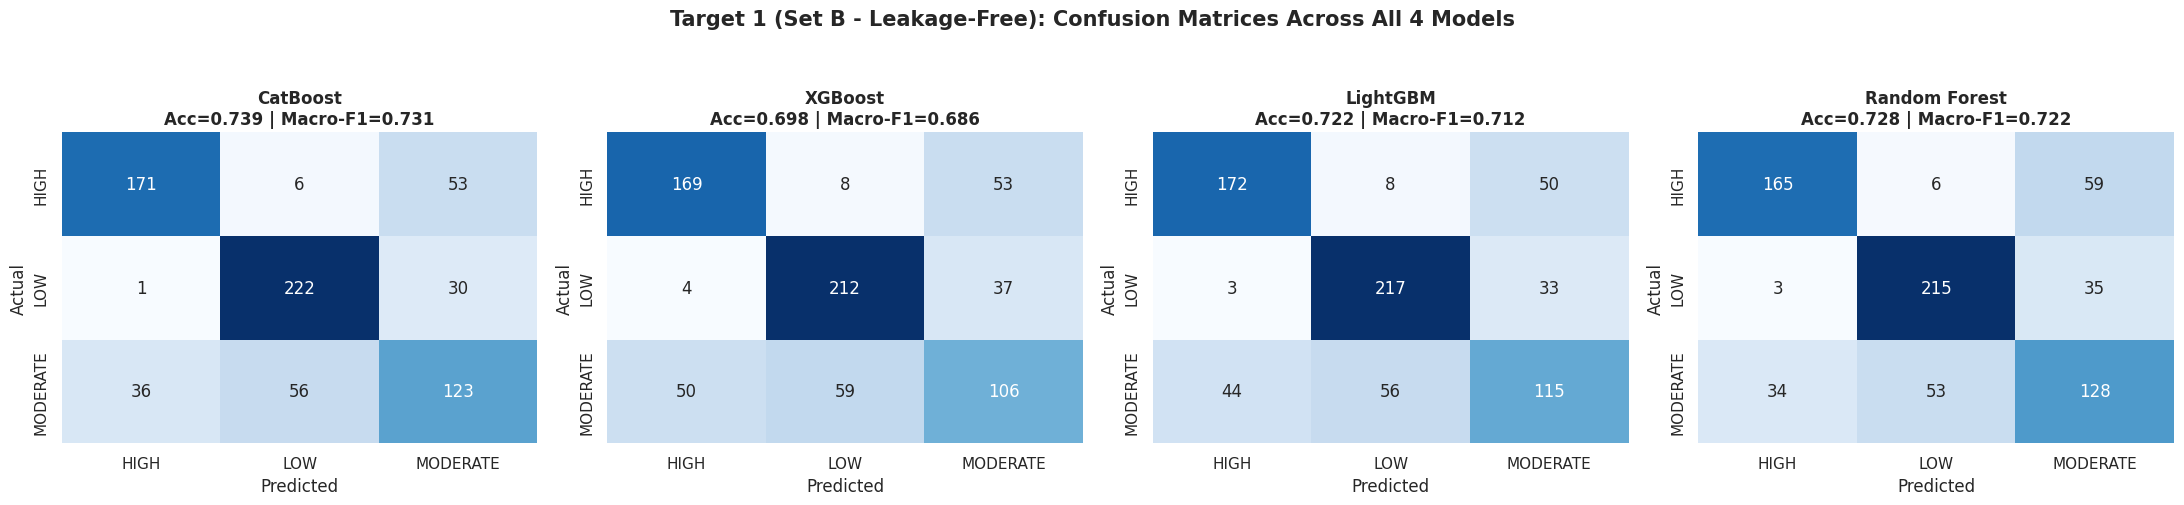

In [ ]:
# ===== رسم مصفوفة الارتباك (Confusion Matrices) وأهمية المتغيرات للموديلات الأربعة في Target 1 (Set B) =====
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
short_t1_labels = [c.replace("_STRUCTURAL_SUSCEPTIBILITY", "") for c in t1_class_names]

for ax, (name, preds) in zip(axes, t1_setB_preds.items()):
    cm = confusion_matrix(y_te_B, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short_t1_labels, yticklabels=short_t1_labels, cbar=False, ax=ax)
    f1_val = f1_score(y_te_B, preds, average="macro")
    acc_val = accuracy_score(y_te_B, preds)
    ax.set_title(f"{name}\nAcc={acc_val:.3f} | Macro-F1={f1_val:.3f}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Target 1 (Set B - Leakage-Free): Confusion Matrices Across All 4 Models", fontsize=15, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

### 🔍 1.4 Target 2 (`traffic_demand_capacity_pressure_class`) — فحص التغطية والاعتمادية

In [ ]:
# ===== فحص Target 2 وتوثيق سبب عدم تدريب نموذج إشرافي عليه =====
t2_col = "traffic_demand_capacity_pressure_class"
t2_idx_col = "traffic_demand_capacity_pressure_index"
t2_avail_col = "traffic_demand_capacity_index_available"

t2_check_cols = [c for c in [t2_col, t2_idx_col, t2_avail_col, "traffic_population_per_lane_km", "traffic_lane_km", "roads_avg_lanes"] if c in df.columns]
if t2_check_cols:
    t2_audit_df = pd.DataFrame({
        "Feature": t2_check_cols,
        "Available_Rows": [int(df[c].notna().sum()) for c in t2_check_cols],
        "Missing_Rows": [int(df[c].isna().sum()) for c in t2_check_cols],
        "Coverage (%)": [round(df[c].notna().mean() * 100, 2) for c in t2_check_cols]
    })
    print("=== Target 2 Coverage & Dependency Audit ===")
    display(t2_audit_df)
    if t2_col in df.columns:
        print("\nTarget 2 Available Class Counts (26 rows total):")
        display(df[t2_col].value_counts(dropna=True).to_frame("Count"))
print("📌 القرار الهندسي لـ Target 2: التغطية 0.75% فقط (26 صفاً من 3,489)، وهي غير كافية إحصائياً لتدريب نموذج تصنيف إشرافي موثوق بدون إعادة حساب المؤشر من المصدر.")

📌 القرار الهندسي لـ Target 2: التغطية 0.75% فقط (26 صفاً من 3,489)، وهي غير كافية إحصائياً لتدريب نموذج تصنيف إشرافي موثوق بدون إعادة حساب المؤشر من المصدر.


### 🏗️ 1.5 Target 3 (`urban_intervention_priority_score` & `class`) — هندسة المؤشر، تحليل الحساسية، ومقارنة (CatBoost, XGBoost, LightGBM, Random Forest)

In [ ]:
# ===== هندسة Target 3 (Urban Intervention Priority Score & Tertile Classes) =====
priority_directions = {
    "traffic_intersection_density": "higher_priority",
    "roads_dead_end_ratio": "higher_priority",
    "transit_transit_accessibility_score": "lower_priority",
    "green_space_public_green_space_fraction": "lower_priority",
    "green_space_ndvi_mean_annual_2026": "lower_priority",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2": "higher_priority",
}
avail_p_cols = [c for c in priority_directions if c in df.columns]
priority_data = df[avail_p_cols].apply(pd.to_numeric, errors="coerce")

scaled_p = pd.DataFrame(
    MinMaxScaler().fit_transform(priority_data),
    columns=priority_data.columns,
    index=df.index
)
for feature, direction in priority_directions.items():
    if feature in scaled_p.columns and direction == "lower_priority":
        scaled_p[feature] = 1.0 - scaled_p[feature]

valid_p_count = scaled_p.notna().sum(axis=1)
score_t3 = scaled_p.mean(axis=1).where(valid_p_count >= max(1, len(avail_p_cols) - 1)) * 100.0
df["urban_intervention_priority_score"] = score_t3

q1_t3, q2_t3 = score_t3.quantile(1 / 3), score_t3.quantile(2 / 3)
df["urban_intervention_priority_class"] = pd.cut(
    score_t3,
    bins=[-np.inf, q1_t3, q2_t3, np.inf],
    labels=["LOW", "MODERATE", "HIGH"],
    include_lowest=True
)

print(f"Target 3 Score Coverage: {score_t3.notna().mean()*100:.2f}% | Cutoffs: LOW/MOD={q1_t3:.2f}, MOD/HIGH={q2_t3:.2f}")
display(
    df.groupby("urban_intervention_priority_class", observed=True)["urban_intervention_priority_score"]
    .agg(["count", "min", "mean", "max"]).round(2)
)

# حفظ النسخة المعالجة كما في الملف الأول
os.makedirs("processed", exist_ok=True)
df.to_csv("processed/urban_intervention_priority_dataset.csv", index=False)

Target 3 Score Coverage: 100.00% | Cutoffs: LOW/MOD=49.37, MOD/HIGH=59.19


,count,min,mean,max
urban_intervention_priority_class,,,,
LOW,1163,37.99,47.05,49.37
MODERATE,1163,49.37,54.22,59.18
HIGH,1163,59.19,63.92,81.46


In [ ]:
# ===== اختيار المتغيرات الآمنة لـ Target 3 وتدريب الموديلات الأربعة (CatBoost, XGBoost, LightGBM, Random Forest) =====
score_col_t3 = "urban_intervention_priority_score"
cls_col_t3 = "urban_intervention_priority_class"

redundant_t3 = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]
kw_exclude_t3 = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
geo_kw_t3 = ["longitude", "latitude", "_lon", "_lat", "lon_", "lat_"]

d_t3 = df[df[cls_col_t3].notna()].copy().reset_index(drop=True)
drop_t3 = set(avail_p_cols) | set(redundant_t3) | {"h3_index"}
drop_t3 |= {c for c in d_t3.columns if any(k in c.lower() for k in kw_exclude_t3)}
drop_t3 |= {c for c in d_t3.columns if any(k in c.lower() for k in geo_kw_t3) or c.lower() in ("lat", "lon")}

num_cols_t3 = d_t3.select_dtypes(include="number").columns
cands_t3 = [c for c in num_cols_t3 if c not in drop_t3 and d_t3[c].notna().mean() >= 0.95 and d_t3[c].nunique() > 1]

# إزالة المتغيرات البديلة شديدة الارتباط (|Spearman| >= 0.90) مع مدخلات المعادلة الستة
proxies_t3 = {
    c for c in cands_t3
    for s in avail_p_cols
    if abs(d_t3[c].corr(d_t3[s], method="spearman")) >= 0.90
}
safe_t3_69 = [c for c in cands_t3 if c not in proxies_t3]
safe_t3_66 = [c for c in safe_t3_69 if "area_km2" not in c.lower()]

print(f"Target 3 Safe Features (with area cols): {len(safe_t3_69)} | (without area_km2 cols): {len(safe_t3_66)}")

le_t3 = LabelEncoder()
y_t3_enc = le_t3.fit_transform(d_t3[cls_col_t3].astype(str))
t3_class_names = list(le_t3.classes_)
coords_t3 = get_h3_coords(d_t3)
spatial_groups_t3 = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=10).fit_predict(coords_t3)

# تقسيم 80/20 للمجموعة النظيفة النهائية (بدون أعمدة المساحة - 66 متغيراً)
X_t3_66 = d_t3[safe_t3_66].apply(pd.to_numeric, errors="coerce")
X_tr_t3, X_te_t3, y_tr_t3, y_te_t3 = train_test_split(
    X_t3_66, y_t3_enc, test_size=0.20, random_state=RANDOM_STATE, stratify=y_t3_enc
)

t3_holdout_df, t3_models, t3_preds = evaluate_classifiers_holdout(
    X_tr_t3, X_te_t3, y_tr_t3, y_te_t3, t3_class_names,
    task_label="Target 3: Urban Intervention Priority Class",
    feature_set_label=f"Leakage-Free ({len(safe_t3_66)} Features, No Area)"
)
print("=== Target 3 (Leakage-Free, No Area Cols) — Random 80/20 Split ===")
display(t3_holdout_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True))

t3_spatial_df = evaluate_classifiers_spatial_cv(
    X_t3_66, y_t3_enc, spatial_groups_t3,
    task_label="Target 3: Urban Intervention Priority Class",
    feature_set_label=f"Leakage-Free ({len(safe_t3_66)} Features, No Area)"
)
print("\n=== Target 3 (Leakage-Free, No Area Cols) — Spatial 5-Fold GroupKFold ===")
display(t3_spatial_df[["Model", "Accuracy", "Accuracy_Std", "Macro_F1", "Macro_F1_Std", "ROC_AUC"]].sort_values("Macro_F1", ascending=False).reset_index(drop=True))

Target 3 Safe Features (with area cols): 84 | (without area_km2 cols): 79
=== Target 3 (Leakage-Free, No Area Cols) — Random 80/20 Split ===


,Task,Feature_Set,Evaluation,Model,N_Features,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,ROC_AUC
0,Target 3: Urban Intervention Priority Class,"Leakage-Free (79 Features, No Area)",Random 80/20 Split,LightGBM,79,0.8410,0.8403,0.8404,0.8405,0.8410,0.9563
1,Target 3: Urban Intervention Priority Class,"Leakage-Free (79 Features, No Area)",Random 80/20 Split,XGBoost,79,0.8381,0.8373,0.8373,0.8375,0.8381,0.9566
2,Target 3: Urban Intervention Priority Class,"Leakage-Free (79 Features, No Area)",Random 80/20 Split,CatBoost,79,0.8309,0.8303,0.8303,0.8315,0.8310,0.9545
3,Target 3: Urban Intervention Priority Class,"Leakage-Free (79 Features, No Area)",Random 80/20 Split,Random Forest,79,0.8138,0.8121,0.8121,0.8123,0.8138,0.9438



=== Target 3 (Leakage-Free, No Area Cols) — Spatial 5-Fold GroupKFold ===


,Model,Accuracy,Accuracy_Std,Macro_F1,Macro_F1_Std,ROC_AUC
0,CatBoost,0.7684,0.0426,0.7088,0.1033,0.9128
1,LightGBM,0.7679,0.0375,0.7078,0.0997,0.9076
2,XGBoost,0.7607,0.0371,0.7001,0.0971,0.9123
3,Random Forest,0.7355,0.0479,0.6758,0.0982,0.8940


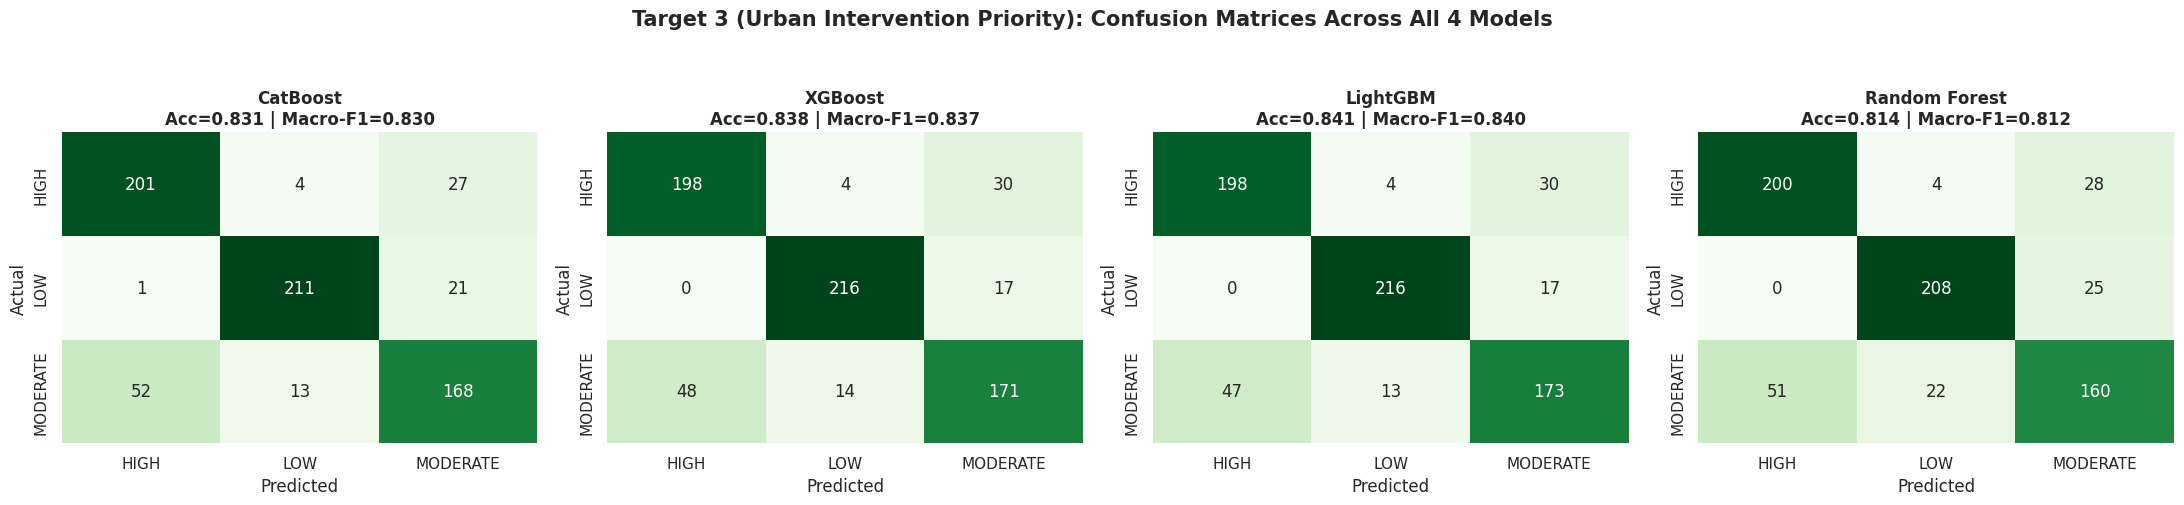

In [ ]:
# ===== رسم مصفوفات الارتباك (Confusion Matrices) للموديلات الأربعة في Target 3 =====
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (name, preds) in zip(axes, t3_preds.items()):
    cm = confusion_matrix(y_te_t3, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=t3_class_names, yticklabels=t3_class_names, cbar=False, ax=ax)
    f1_val = f1_score(y_te_t3, preds, average="macro")
    acc_val = accuracy_score(y_te_t3, preds)
    ax.set_title(f"{name}\nAcc={acc_val:.3f} | Macro-F1={f1_val:.3f}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Target 3 (Urban Intervention Priority): Confusion Matrices Across All 4 Models", fontsize=15, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
# ===== 1.6 تحليل الحساسية لـ Target 3 (Leave-One-Out, Double-Weight, & 1,000 Dirichlet Simulations) =====
inds_dir = {
    "traffic_intersection_density": +1,
    "roads_dead_end_ratio": +1,
    "transit_transit_accessibility_score": -1,
    "green_space_public_green_space_fraction": -1,
    "green_space_ndvi_mean_annual_2026": -1,
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2": +1,
}
inds_names = [c for c in inds_dir if c in df.columns]
X_sens = df[inds_names].apply(pd.to_numeric, errors="coerce")
N_sens = (X_sens - X_sens.min()) / (X_sens.max() - X_sens.min())
for c in inds_names:
    if inds_dir[c] == -1:
        N_sens[c] = 1.0 - N_sens[c]

M_sens = N_sens.values
mask_sens = ~np.isnan(M_sens)
M0_sens = np.where(mask_sens, M_sens, 0.0)
valid_sens = mask_sens.sum(axis=1) >= max(1, len(inds_names) - 1)

def wscore_fn(w):
    w = np.asarray(w, float)
    den = (mask_sens * w).sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        s = (M0_sens * w).sum(axis=1) / den * 100.0
    return np.where(valid_sens & (den > 0), s, np.nan)

def tertiles_fn(s):
    q1, q2 = np.nanquantile(s, [1/3, 2/3])
    c = np.full(len(s), -1)
    ok = ~np.isnan(s)
    c[ok] = np.where(s[ok] <= q1, 0, np.where(s[ok] <= q2, 1, 2))
    return c

base_w_score = wscore_fn(np.ones(len(inds_names)))
base_w_cls = tertiles_fn(base_w_score)

def compare_w(s):
    c = tertiles_fn(s)
    ok = (base_w_cls >= 0) & (c >= 0)
    stay = (c[ok] == base_w_cls[ok]).mean()
    rho = pd.Series(base_w_score[ok]).corr(pd.Series(s[ok]), method="spearman")
    h0 = (base_w_cls == 2) & ok
    high_kept = ((c == 2) & h0).sum() / h0.sum()
    jump = (np.abs(c[ok] - base_w_cls[ok]) == 2).mean()
    return stay, rho, high_kept, jump

sens_cols = ["same_class_share", "spearman_vs_baseline", "HIGH_kept_share", "LOW<->HIGH_jump_share"]
sens_rows = []
for i, n in enumerate(inds_names):
    w = np.ones(len(inds_names)); w[i] = 0
    sens_rows.append((f"drop {n}", *compare_w(wscore_fn(w))))
for i, n in enumerate(inds_names):
    w = np.ones(len(inds_names)); w[i] = 2
    sens_rows.append((f"double {n}", *compare_w(wscore_fn(w))))

print("=== Target 3 Sensitivity Analysis: Leave-One-Out & Double-Weight Scenarios ===")
display(pd.DataFrame(sens_rows, columns=["scenario"] + sens_cols).set_index("scenario").round(3))

rng = np.random.default_rng(RANDOM_STATE)
dirichlet_res = np.array([compare_w(wscore_fn(rng.dirichlet(np.ones(len(inds_names))))) for _ in range(1000)])
print("\n=== 1,000 Random Dirichlet Weightings Summary ===")
display(pd.DataFrame(dirichlet_res, columns=sens_cols).describe(percentiles=[0.05, 0.5, 0.95]).loc[["mean", "min", "5%", "50%", "95%"]].round(3))

=== Target 3 Sensitivity Analysis: Leave-One-Out & Double-Weight Scenarios ===


,same_class_share,spearman_vs_baseline,HIGH_kept_share,LOW<->HIGH_jump_share
scenario,,,,
drop traffic_intersection_density,0.549,0.687,0.685,0.027
drop roads_dead_end_ratio,0.862,0.925,0.839,0.007
drop transit_transit_accessibility_score,0.807,0.907,0.756,0.001
drop green_space_public_green_space_fraction,0.974,0.994,0.974,0.000
drop green_space_ndvi_mean_annual_2026,0.944,0.990,0.942,0.000
drop air_quality_s5p_no2_tropospheric_column_mean_umol_m2,0.729,0.865,0.837,0.003
double traffic_intersection_density,0.864,0.953,0.846,0.000
double roads_dead_end_ratio,0.934,0.989,0.912,0.000
double transit_transit_accessibility_score,0.707,0.822,0.820,0.015



=== 1,000 Random Dirichlet Weightings Summary ===


,same_class_share,spearman_vs_baseline,HIGH_kept_share,LOW<->HIGH_jump_share
mean,0.727,0.808,0.761,0.019
min,0.301,0.176,0.427,0.000
5%,0.469,0.488,0.616,0.000
50%,0.769,0.872,0.769,0.004
95%,0.884,0.962,0.877,0.079


## ⚖️ المرحلة 2: مقارنة موديلات التصنيف مع `SMOTE` على الأهداف الخمسة (`UrbanMind_SMOTE_Model_Benchmark`)

يدمج هذا القسم ملف `UrbanMind_SMOTE_Model_Benchmark_Colab (1).ipynb` بالكامل مع توسيع قائمة `MODEL_CONFIGS` لتشمل:
- **Logistic Regression**
- **MLP Classifier**
- **Random Forest**
- **XGBoost**
- **LightGBM**
- **CatBoost**

وذلك داخل `imblearn.Pipeline` يمنع أي تسريب للبيانات أثناء حساب `PolynomialFeatures` و `SelectKBest` و `SMOTE`.

In [ ]:
# ===== 2.1 تجهيز الخصائص الهندسية والأهداف الخمسة لـ SMOTE Benchmark =====
VALIDATION_SIZE = 0.20
TEST_SIZE_IF_NO_SPLIT = 0.20
SMOTE_K_NEIGHBORS = 5
USE_POLYNOMIAL_FEATURES = True
POLY_DEGREE = 2
SELECT_K_BEST = 120

def get_numeric_column(frame, column):
    if column not in frame.columns:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    s = frame[column]
    if s.dtype == object or str(s.dtype) == "bool":
        mapped = s.astype(str).str.strip().map({"True": 1.0, "False": 0.0, "1": 1.0, "0": 0.0, "1.0": 1.0, "0.0": 0.0})
        if mapped.notna().any():
            return mapped
    return pd.to_numeric(s, errors="coerce")

split_values = df["split"].astype(str).str.strip().str.lower() if "split" in df.columns else pd.Series("", index=df.index)
source_train_mask = split_values.eq("train")
source_test_mask = ~source_train_mask
has_usable_split = source_train_mask.any() and source_test_mask.any()

if has_usable_split:
    smote_train_mask = source_train_mask.copy()
    smote_test_mask = source_test_mask.copy()
    print(f"Using existing split column: train={int(smote_train_mask.sum())}, test={int(smote_test_mask.sum())}")
else:
    row_ids = np.arange(len(df))
    low_values = get_numeric_column(df, low_oh).fillna(0).to_numpy()
    mod_values = get_numeric_column(df, mod_oh).fillna(0).to_numpy()
    traffic_proxy = np.full(len(df), 2, dtype=int)
    traffic_proxy[mod_values > 0] = 1
    traffic_proxy[low_values > 0] = 0
    tr_ids, te_ids = train_test_split(
        row_ids, test_size=TEST_SIZE_IF_NO_SPLIT, random_state=RANDOM_STATE, stratify=traffic_proxy
    )
    smote_train_mask = pd.Series(False, index=df.index)
    smote_test_mask = pd.Series(False, index=df.index)
    smote_train_mask.iloc[tr_ids] = True
    smote_test_mask.iloc[te_ids] = True
    print(f"Created fixed stratified holdout: train={int(smote_train_mask.sum())}, test={int(smote_test_mask.sum())}")

# هندسة الخصائص الإضافية الخاصة بملف SMOTE
road_major_cols = ["roads_motorway_length_km", "roads_trunk_length_km", "roads_primary_road_length_km", "roads_secondary_road_length_km"]
road_local_cols = ["roads_tertiary_road_length_km", "roads_residential_road_length_km", "roads_service_road_length_km"]

def row_sum_available(frame, cols):
    values = pd.concat([get_numeric_column(frame, c) for c in cols], axis=1)
    return values.sum(axis=1, min_count=1)

df["fe_major_roads_sum"] = row_sum_available(df, road_major_cols)
df["fe_local_roads_sum"] = row_sum_available(df, road_local_cols)
df["fe_pop_x_road_density"] = get_numeric_column(df, "population_population_density_worldpop_2026") * get_numeric_column(df, "roads_road_density_km_per_km2")
df["fe_pop_x_intersections"] = get_numeric_column(df, "population_population_density_worldpop_2026") * get_numeric_column(df, "roads_intersection_density")
df["fe_ndvi_seasonal_diff"] = get_numeric_column(df, "green_space_ndvi_mean_annual_2026") - get_numeric_column(df, "green_space_ndvi_mean_summer_2026")

# بناء الأهداف الخمسة
targets_dict = {}
low_values = get_numeric_column(df, low_oh).fillna(0).to_numpy()
mod_values = get_numeric_column(df, mod_oh).fillna(0).to_numpy()
y_traffic = np.full(len(df), 2, dtype=int)
y_traffic[mod_values > 0] = 1
y_traffic[low_values > 0] = 0
targets_dict["1_Traffic_Susceptibility_Class"] = pd.Series(y_traffic, index=df.index, dtype="Int64")

transit_presence = get_numeric_column(df, "transit_has_transit")
y_tr_bin = (transit_presence > 0).astype(float)
y_tr_bin[transit_presence.isna()] = np.nan
targets_dict["2_Transit_Availability_Binary"] = pd.Series(y_tr_bin, index=df.index, dtype="Float64")

acc_col = "transit_transit_accessibility_score"
acc_values = get_numeric_column(df, acc_col)
acc_median = acc_values.loc[smote_train_mask].median()
y_acc = (acc_values > acc_median).astype(float)
y_acc[acc_values.isna()] = np.nan
targets_dict["3_High_Transit_Accessibility"] = pd.Series(y_acc, index=df.index, dtype="Float64")

public_green = get_numeric_column(df, "green_space_has_public_green_space")
y_grn = (public_green > 0).astype(float)
y_grn[public_green.isna()] = np.nan
targets_dict["4_Public_Green_Space_Binary"] = pd.Series(y_grn, index=df.index, dtype="Float64")

no2_col = "air_quality_s5p_no2_tropospheric_column_mean_umol_m2"
no2_values = get_numeric_column(df, no2_col)
no2_median = no2_values.loc[smote_train_mask].median()
y_no2_bin = (no2_values > no2_median).astype(float)
y_no2_bin[no2_values.isna()] = np.nan
targets_dict["5_High_NO2_Air_Pollution"] = pd.Series(y_no2_bin, index=df.index, dtype="Float64")

features_per_target = {
    '1_Traffic_Susceptibility_Class': ['population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_length_km', 'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_service_road_length_km', 'roads_other_road_length_km', 'roads_intersection_count', 'roads_intersection_density', 'roads_dead_end_count', 'roads_lit_road_ratio', 'roads_maxspeed_coverage', 'traffic_population_per_road_km', 'traffic_intersection_per_road_km', 'transit_has_transit', 'transit_stop_density_per_km2', 'transit_transit_accessibility_score', 'green_space_total_green_space_fraction', 'fe_major_roads_sum', 'fe_local_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections'],
    '2_Transit_Availability_Binary': ['population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_length_km', 'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_service_road_length_km', 'roads_intersection_count', 'roads_intersection_density', 'roads_dead_end_ratio', 'roads_oneway_ratio', 'roads_bridge_ratio', 'roads_lit_road_ratio', 'roads_maxspeed_coverage', 'traffic_population_per_road_km', 'traffic_structural_network_friction_index', 'green_space_ndvi_mean_annual_2026', 'green_space_total_green_space_fraction', 'green_space_agricultural_area_m2', 'fe_major_roads_sum', 'fe_local_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections'],
    '3_High_Transit_Accessibility': ['transit_metro_station_count', 'transit_light_rail_station_count', 'transit_rail_station_count', 'transit_brt_station_count', 'transit_bus_stop_count', 'transit_paratransit_stop_count', 'transit_interchange_station_count', 'transit_multimodal_hub_present', 'transit_nearest_transit_stop_network_distance_m', 'transit_nearest_metro_station_network_distance_m', 'transit_nearest_brt_station_network_distance_m', 'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_density_km_per_km2', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_residential_road_length_km', 'roads_intersection_density', 'roads_dead_end_ratio', 'roads_lit_road_ratio', 'traffic_structural_network_friction_index', 'fe_major_roads_sum', 'fe_pop_x_intersections'],
    '4_Public_Green_Space_Binary': ['green_space_ndvi_mean_summer_2026', 'green_space_ndvi_median_summer_2026', 'green_space_ndvi_p90_summer_2026', 'green_space_ndvi_min_summer_2026', 'green_space_vegetated_fraction_summer_2026', 'green_space_ndvi_mean_annual_2026', 'green_space_ndvi_median_annual_2026', 'green_space_ndvi_p90_annual_2026', 'green_space_ndvi_min_annual_2026', 'green_space_vegetated_fraction_annual_2026', 'green_space_vegetation_persistence_ratio', 'green_space_private_restricted_green_space_area_m2', 'green_space_agricultural_area_m2', 'green_space_natural_reserve_area_m2', 'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_density_km_per_km2', 'roads_primary_road_length_km', 'roads_residential_road_length_km', 'roads_intersection_density', 'roads_lit_road_ratio', 'transit_transit_accessibility_score', 'fe_ndvi_seasonal_diff', 'fe_pop_x_road_density'],
    '5_High_NO2_Air_Pollution': ['roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_road_density_km_per_km2', 'roads_intersection_density', 'roads_oneway_ratio', 'roads_bridge_ratio', 'traffic_structural_network_friction_index', 'traffic_population_per_road_km', 'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'transit_bus_stop_count', 'transit_paratransit_stop_count', 'transit_stop_density_per_km2', 'transit_transit_accessibility_score', 'green_space_ndvi_mean_annual_2026', 'green_space_vegetated_fraction_annual_2026', 'green_space_total_green_space_fraction', 'green_space_agricultural_area_m2', 'air_quality_nearest_pm25_station_distance_km', 'air_quality_pm25_station_count_within_5km', 'fe_major_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections']
}

print("\nSMOTE Benchmark Targets Ready:")
for t_name, y_s in targets_dict.items():
    v = y_s.dropna().astype(int)
    print(f"- {t_name}: n={len(v):,} | distribution={v.value_counts().sort_index().to_dict()}")

Using existing split column: train=2422, test=1067

SMOTE Benchmark Targets Ready:
- 1_Traffic_Susceptibility_Class: n=3,489 | distribution={0: 1264, 1: 1074, 2: 1151}
- 2_Transit_Availability_Binary: n=3,489 | distribution={0: 3051, 1: 438}
- 3_High_Transit_Accessibility: n=3,489 | distribution={0: 2798, 1: 691}
- 4_Public_Green_Space_Binary: n=3,489 | distribution={0: 3101, 1: 388}
- 5_High_NO2_Air_Pollution: n=3,489 | distribution={0: 1745, 1: 1744}


In [ ]:
# ===== 2.2 إعداد وتشغيل SMOTE Benchmark لجميع الموديلات (Logistic, MLP, RF, XGBoost, LightGBM, CatBoost) =====
MODEL_CONFIGS = [
    {
        "name": "Logistic Regression",
        "estimator": LogisticRegression,
        "parameter_sets": [
            {"C": 0.5, "max_iter": 1500, "solver": "lbfgs", "class_weight": "balanced", "random_state": RANDOM_STATE},
            {"C": 1.0, "max_iter": 3000, "solver": "lbfgs", "class_weight": None, "random_state": RANDOM_STATE},
        ],
    },
    {
        "name": "MLP Classifier",
        "estimator": MLPClassifier,
        "parameter_sets": [
            {"hidden_layer_sizes": (128, 64), "activation": "relu", "solver": "adam", "alpha": 0.05, "learning_rate": "adaptive", "early_stopping": True, "validation_fraction": 0.15, "max_iter": 400, "random_state": RANDOM_STATE},
            {"hidden_layer_sizes": (64, 32), "activation": "relu", "solver": "adam", "alpha": 0.01, "learning_rate_init": 0.001, "early_stopping": True, "max_iter": 500, "random_state": RANDOM_STATE},
        ],
    },
    {
        "name": "Random Forest",
        "estimator": RandomForestClassifier,
        "parameter_sets": [
            {"n_estimators": 300, "max_depth": 15, "min_samples_leaf": 2, "random_state": RANDOM_STATE, "n_jobs": -1},
        ],
    },
    {
        "name": "XGBoost",
        "estimator": XGBClassifier,
        "parameter_sets": [
            {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.85, "colsample_bytree": 0.85, "eval_metric": "logloss", "random_state": RANDOM_STATE, "n_jobs": -1},
        ],
    },
    {
        "name": "LightGBM",
        "estimator": LGBMClassifier,
        "parameter_sets": [
            {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "num_leaves": 31, "random_state": RANDOM_STATE, "n_jobs": -1, "verbose": -1},
        ],
    },
    {
        "name": "CatBoost",
        "estimator": CatBoostClassifier,
        "parameter_sets": [
            {"iterations": 400, "learning_rate": 0.05, "depth": 6, "random_seed": RANDOM_STATE, "verbose": 0, "allow_writing_files": False},
        ],
    },
]

def make_smote_pipeline(estimator_class, params, y_fit, n_input_features, use_smote=True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if USE_POLYNOMIAL_FEATURES:
        poly_feature_count = n_input_features + (n_input_features * (n_input_features + 1) // 2)
        selected_k = min(SELECT_K_BEST, poly_feature_count)
        steps.append(("poly", PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)))
        steps.append(("selector", SelectKBest(score_func=f_classif, k=selected_k)))
    steps.append(("scaler", StandardScaler()))
    if use_smote:
        class_counts = pd.Series(np.asarray(y_fit, dtype=int)).value_counts()
        min_count = int(class_counts.min())
        k_neighbors = max(1, min(SMOTE_K_NEIGHBORS, min_count - 1))
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=k_neighbors)))
    steps.append(("model", estimator_class(**params)))
    return ImbPipeline(steps=steps)

def calculate_roc_auc(model, X_test, y_test):
    if not hasattr(model, "predict_proba"):
        return np.nan
    try:
        probabilities = model.predict_proba(X_test)
        classes = np.asarray(model.classes_)
        unique_y = np.sort(pd.Series(y_test).unique())
        if len(unique_y) == 2:
            positive_label = 1 if 1 in classes else classes[-1]
            positive_index = int(np.where(classes == positive_label)[0][0])
            return roc_auc_score(y_test, probabilities[:, positive_index])
        return roc_auc_score(y_test, probabilities, labels=classes, multi_class="ovr", average="macro")
    except Exception:
        return np.nan

smote_results = []
for target_name, y_series in targets_dict.items():
    valid_mask = y_series.notna()
    target_index = df.index[valid_mask]
    y_all = y_series.loc[target_index].astype(int)

    available_cols = [col for col in features_per_target[target_name] if col in df.columns]
    X_all = pd.DataFrame({col: get_numeric_column(df.loc[target_index], col) for col in available_cols}, index=target_index)

    this_train_mask = smote_train_mask.loc[target_index].astype(bool)
    this_test_mask = smote_test_mask.loc[target_index].astype(bool)
    X_train_full, y_train_full = X_all.loc[this_train_mask], y_all.loc[this_train_mask]
    X_test_s, y_test_s = X_all.loc[this_test_mask], y_all.loc[this_test_mask]

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_full, y_train_full, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE, stratify=y_train_full
    )

    for spec in MODEL_CONFIGS:
        model_name = spec["name"]
        estimator_class = spec["estimator"]
        best_val_f1 = -np.inf
        best_params = None

        for params in spec["parameter_sets"]:
            cand = make_smote_pipeline(estimator_class, params, y_fit, X_fit.shape[1], use_smote=True)
            cand.fit(X_fit, y_fit)
            val_pred = np.asarray(cand.predict(X_val)).ravel().astype(int)
            val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_params = params

        final_model = make_smote_pipeline(estimator_class, best_params, y_train_full, X_train_full.shape[1], use_smote=True)
        final_model.fit(X_train_full, y_train_full)
        test_pred = np.asarray(final_model.predict(X_test_s)).ravel().astype(int)

        test_acc = accuracy_score(y_test_s, test_pred)
        test_macro_f1 = f1_score(y_test_s, test_pred, average="macro", zero_division=0)
        test_weighted_f1 = f1_score(y_test_s, test_pred, average="weighted", zero_division=0)
        test_prec = precision_score(y_test_s, test_pred, average="macro", zero_division=0)
        test_rec = recall_score(y_test_s, test_pred, average="macro", zero_division=0)
        test_auc = calculate_roc_auc(final_model, X_test_s, y_test_s)

        rec_row = {
            "Target": target_name,
            "Model": model_name,
            "Features_Used": len(available_cols),
            "Best_Validation_Macro_F1": round(float(best_val_f1), 4),
            "Test_Accuracy": round(float(test_acc), 4),
            "Test_Macro_F1": round(float(test_macro_f1), 4),
            "Test_Weighted_F1": round(float(test_weighted_f1), 4),
            "Test_Macro_Precision": round(float(test_prec), 4),
            "Test_Macro_Recall": round(float(test_rec), 4),
            "Test_ROC_AUC": round(float(test_auc), 4) if pd.notna(test_auc) else np.nan,
        }
        smote_results.append(rec_row)
        MASTER_CLASSIFICATION_LOG.append({
            "Task": f"SMOTE Benchmark: {target_name}",
            "Feature_Set": f"Poly+SelectKBest+SMOTE ({len(available_cols)} raw feats)",
            "Evaluation": "Held-out Test (Selected by Val)",
            "Model": model_name,
            "N_Features": len(available_cols),
            "Accuracy": rec_row["Test_Accuracy"],
            "Macro_F1": rec_row["Test_Macro_F1"],
            "Weighted_F1": rec_row["Test_Weighted_F1"],
            "Macro_Precision": rec_row["Test_Macro_Precision"],
            "Macro_Recall": rec_row["Test_Macro_Recall"],
            "ROC_AUC": rec_row["Test_ROC_AUC"]
        })

smote_results_df = pd.DataFrame(smote_results)
smote_results_df.to_csv("smote_model_comparison.csv", index=False)
print("=== FINAL SMOTE MODEL COMPARISON ACROSS ALL 5 TARGETS & 6 MODELS ===")
display(smote_results_df)

best_smote_per_target = smote_results_df.loc[smote_results_df.groupby("Target")["Best_Validation_Macro_F1"].idxmax()].sort_values("Target")
print("\n=== Best Model per Target (Selected by Validation Macro-F1) ===")
display(best_smote_per_target)

=== FINAL SMOTE MODEL COMPARISON ACROSS ALL 5 TARGETS & 6 MODELS ===


,Target,Model,Features_Used,Best_Validation_Macro_F1,Test_Accuracy,Test_Macro_F1,Test_Weighted_F1,Test_Macro_Precision,Test_Macro_Recall,Test_ROC_AUC
0,1_Traffic_Susceptibility_Class,Logistic Regression,31,0.8920,0.9110,0.9090,0.9111,0.9112,0.9088,0.9826
1,1_Traffic_Susceptibility_Class,MLP Classifier,31,0.8811,0.9082,0.9072,0.9091,0.9102,0.9067,0.9815
2,1_Traffic_Susceptibility_Class,Random Forest,31,0.9012,0.9147,0.9129,0.9148,0.9143,0.9127,0.9845
3,1_Traffic_Susceptibility_Class,XGBoost,31,0.8947,0.9091,0.9070,0.9092,0.9093,0.9068,0.9837
4,1_Traffic_Susceptibility_Class,LightGBM,31,0.8879,0.9157,0.9138,0.9159,0.9153,0.9136,0.9838
5,1_Traffic_Susceptibility_Class,CatBoost,31,0.8949,0.9203,0.9185,0.9204,0.9193,0.9183,0.9853
6,2_Transit_Availability_Binary,Logistic Regression,31,0.8353,0.9007,0.8119,0.9113,0.7649,0.9120,0.9737
7,2_Transit_Availability_Binary,MLP Classifier,31,0.8287,0.9157,0.8255,0.9220,0.7865,0.8887,0.9710
8,2_Transit_Availability_Binary,Random Forest,31,0.8454,0.9260,0.8446,0.9311,0.8056,0.9051,0.9637
9,2_Transit_Availability_Binary,XGBoost,31,0.8549,0.9316,0.8522,0.9355,0.8178,0.9012,0.9699



=== Best Model per Target (Selected by Validation Macro-F1) ===


,Target,Model,Features_Used,Best_Validation_Macro_F1,Test_Accuracy,Test_Macro_F1,Test_Weighted_F1,Test_Macro_Precision,Test_Macro_Recall,Test_ROC_AUC
2,1_Traffic_Susceptibility_Class,Random Forest,31,0.9012,0.9147,0.9129,0.9148,0.9143,0.9127,0.9845
10,2_Transit_Availability_Binary,LightGBM,31,0.8729,0.9288,0.8466,0.9330,0.8121,0.8961,0.9689
14,3_High_Transit_Accessibility,Random Forest,26,1.0000,0.9925,0.9877,0.9925,0.9896,0.9858,0.9996
18,4_Public_Green_Space_Binary,Logistic Regression,27,0.7384,0.8622,0.7471,0.8816,0.7059,0.8722,0.9316
27,5_High_NO2_Air_Pollution,XGBoost,30,0.9175,0.9091,0.9091,0.9091,0.9092,0.9091,0.9687


## 📈 المرحلة 3: نماذج الانحدار والنماذج الخطية (`Linear, Ridge, Lasso, SVM/SVR, KNN` + `Random Forest, XGBoost, LightGBM, CatBoost Regressors`)

يدمج هذا القسم:
1. **`Linear_Models_and_Scenario_Engine (1).ipynb`**: التنظيف الهيكلي للأعمدة، كشف الازدواجية الخطية (Multicollinearity)، وبناء التقسيم المكاني (`GroupShuffleSplit` على مربعات جغرافية).
2. **`SVM_Model.ipynb`**: نموذج `SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale')` مع رسومات التقييم التشخيصية الثلاثة.
3. **`KNN_Model.ipynb`**: نموذج `KNeighborsRegressor(n_neighbors=15, weights='distance', p=2, n_jobs=-1)` مع رسومات التقييم التشخيصية الثلاثة.
4. **إضافة نماذج الانحدار الشجرية (`RandomForestRegressor`, `XGBRegressor`, `LGBMRegressor`, `CatBoostRegressor`)** لمقارنة شاملة وعادلة على نفس التقسيم المكاني.

In [ ]:
# ===== 3.1 تنظيف البيانات وبناء دالة استخراج المتغيرات الخالية من التسريب (من ملف Linear Models) =====
df_clean = df_raw.copy()
txt_cols_all = [c for c in df_clean.select_dtypes(include="object").columns if c != "h3_index"]
const_cols = [c for c in txt_cols_all if df_clean[c].nunique(dropna=True) <= 1]
bool_like = [c for c in txt_cols_all if c not in const_cols and set(df_clean[c].dropna().astype(str)) <= {"True", "False"}]
cat_cols = [c for c in txt_cols_all if c not in const_cols + bool_like]

miss_pct = df_clean.isna().mean().mul(100)
drop_cols_reg = list(const_cols) + miss_pct[miss_pct > 95].index.tolist() + [
    "transit_transit_modes_available", "transit_district",
    "air_quality_nearest_station_id", "air_quality_nearest_station_name",
    "traffic_demand_capacity_pressure_class"
]
drop_cols_reg = [c for c in dict.fromkeys(drop_cols_reg) if c in df_clean.columns]
df2 = df_clean.drop(columns=drop_cols_reg).copy()

for c in bool_like:
    if c in df2.columns:
        df2[c] = df2[c].astype(str).map({"True": 1.0, "False": 0.0})

onehot_cols = [c for c in cat_cols if c in df2.columns]
if onehot_cols:
    df2 = pd.get_dummies(df2, columns=onehot_cols, dtype=int)

print(f"Cleaned regression dataframe shape: {df2.shape}")

PREFIXES = ["population_", "roads_", "traffic_", "transit_", "air_quality_", "green_space_"]
SUFFIXES = {"norm", "normalized", "score", "index", "pct", "class", "z", "rank", "log"}

def domain(c):
    return next((p for p in PREFIXES if c.startswith(p)), "other")

def stem(c):
    d = domain(c)
    toks = (c[len(d):] if d != "other" else c).split("_")
    while len(toks) > 1 and toks[-1] in SUFFIXES:
        toks.pop()
    return "_".join(toks)

def build_xy(data, target, use_log=False, drop_same_domain=False, extra_drop=()):
    d = data.dropna(subset=[target]).reset_index(drop=True)
    lat = d["roads_latitude"].fillna(d["population_latitude"]) if "roads_latitude" in d.columns else pd.Series(30.0, index=d.index)
    lat = lat.fillna(lat.median())
    lon = d["roads_longitude"].fillna(d["population_longitude"]) if "roads_longitude" in d.columns else pd.Series(31.2, index=d.index)
    lon = lon.fillna(lon.median())
    groups = (np.floor(lat / 0.05).astype(int).astype(str) + "_" + np.floor(lon / 0.05).astype(int).astype(str))

    t_stem, t_dom, removed = stem(target), domain(target), {}
    for c in d.columns:
        if c == "h3_index":                                  removed[c] = "id"
        elif c == target:                                    removed[c] = "target"
        elif c.endswith(("_latitude", "_longitude")):        removed[c] = "coordinates"
        elif c in extra_drop:                                removed[c] = "manual"
        elif stem(c) == t_stem or c.startswith(target) or target.startswith(c):
                                                             removed[c] = "leakage (same metric)"
        elif drop_same_domain and domain(c) == t_dom:        removed[c] = "same domain (strict)"
        elif d[c].nunique(dropna=True) <= 1:                 removed[c] = "constant"

    X_out = d.drop(columns=list(removed)).select_dtypes(include=np.number)
    y_out = np.log1p(d[target]) if use_log else d[target].copy()
    return X_out, y_out, groups, removed

TARGET = "air_quality_s5p_no2_tropospheric_column_mean_umol_m2"
no2_other = [c for c in df2.columns if "no2" in c.lower() and c != TARGET]
X_reg_all, y_reg_all, groups_reg, removed_reg = build_xy(df2, TARGET, extra_drop=no2_other)

# إزالة الأعمدة المكررة (|corr| > 0.99) وبدائل الموقع (Location Proxies)
corr_mat = X_reg_all.corr().abs()
upper_tri = corr_mat.where(np.triu(np.ones(corr_mat.shape), 1).astype(bool))
dup_cols = [c for c in upper_tri.columns if (upper_tri[c] > 0.99).any()]
proxy_cols = [c for c in X_reg_all.columns if any(k in c for k in ["cell_full_area", "district_calibration", "station_count"])]
X_reg_clean = X_reg_all.drop(columns=sorted(set(dup_cols) | set(proxy_cols)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X_reg_all, y_reg_all, groups=groups_reg))

# تجهيز X_train, X_test, y_train, y_test الموحدة والمقيسة (لتشغيل SVM_Model و KNN_Model وكافة موديلات الانحدار)
reg_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
X_train = pd.DataFrame(reg_prep.fit_transform(X_reg_all.iloc[tr_idx]), columns=X_reg_all.columns, index=X_reg_all.iloc[tr_idx].index)
X_test = pd.DataFrame(reg_prep.transform(X_reg_all.iloc[te_idx]), columns=X_reg_all.columns, index=X_reg_all.iloc[te_idx].index)
y_train = y_reg_all.iloc[tr_idx].copy()
y_test = y_reg_all.iloc[te_idx].copy()

print(f"Target: {TARGET}")
print(f"Training data: {X_train.shape} | Test data: {X_test.shape} | Clean subset features: {X_reg_clean.shape[1]}")

Cleaned regression dataframe shape: (3489, 121)
Target: air_quality_s5p_no2_tropospheric_column_mean_umol_m2
Training data: (2443, 108) | Test data: (1046, 108) | Clean subset features: 75


### ⚙️ 3.2 تشغيل نموذج `SVM Regression (SVR)` وتشخيصاته البصرية (`SVM_Model.ipynb`)

SVM MAE:  0.2320
SVM RMSE: 0.3611
SVM R²:   0.8695


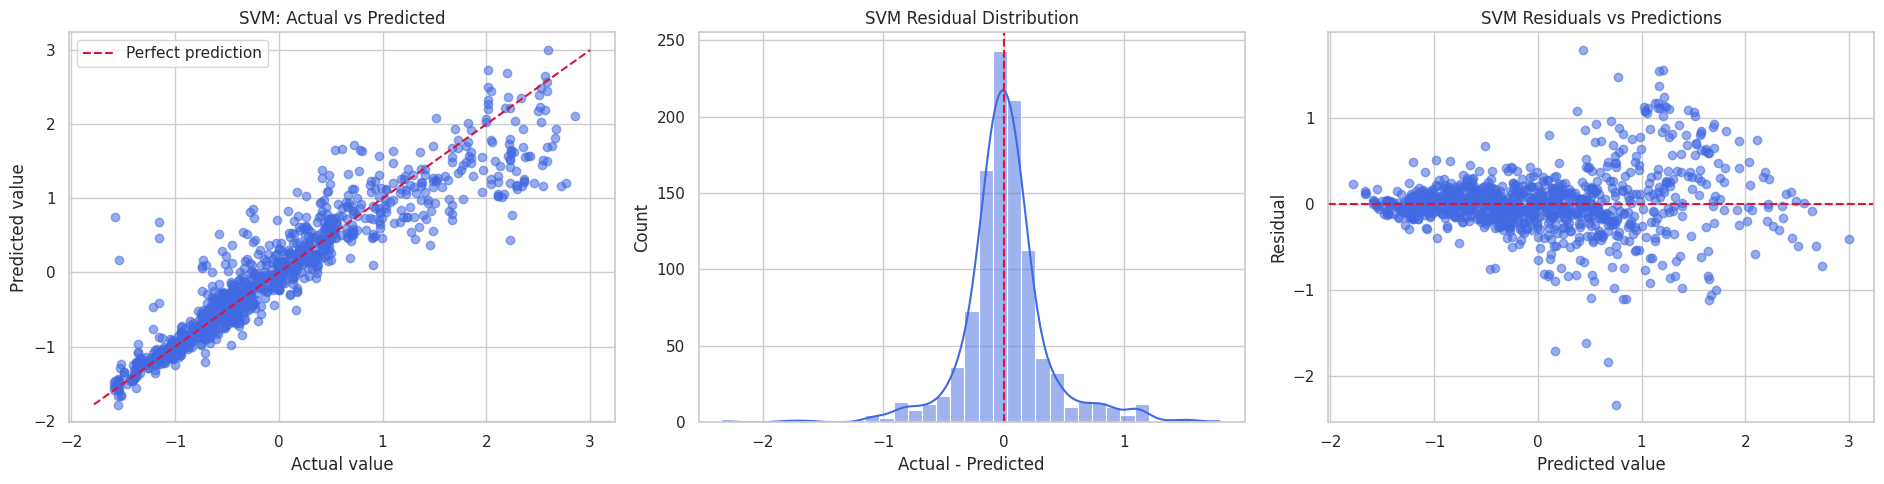

,actual,predicted,residual
2,-0.451304,0.369303,-0.820607
13,-0.615765,-0.441092,-0.174673
15,-0.354255,-0.368035,0.013780
17,-0.302513,0.519703,-0.822216
24,-0.456445,-0.305033,-0.151412


In [ ]:
# ===== SVM Regression Model (من ملف SVM_Model.ipynb) =====
svm_model = SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale')
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

svm_mae = mean_absolute_error(y_test, svm_predictions)
svm_rmse = mean_squared_error(y_test, svm_predictions) ** 0.5
svm_r2 = r2_score(y_test, svm_predictions)
svm_residuals = y_test - svm_predictions

print(f'SVM MAE:  {svm_mae:.4f}')
print(f'SVM RMSE: {svm_rmse:.4f}')
print(f'SVM R²:   {svm_r2:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
limits = [min(y_test.min(), svm_predictions.min()), max(y_test.max(), svm_predictions.max())]
axes[0].scatter(y_test, svm_predictions, alpha=0.55, color='royalblue')
axes[0].plot(limits, limits, '--', color='crimson', label='Perfect prediction')
axes[0].set_xlabel('Actual value'); axes[0].set_ylabel('Predicted value')
axes[0].set_title('SVM: Actual vs Predicted'); axes[0].legend()

sns.histplot(svm_residuals, bins=35, kde=True, color='royalblue', ax=axes[1])
axes[1].axvline(0, color='crimson', linestyle='--')
axes[1].set_title('SVM Residual Distribution'); axes[1].set_xlabel('Actual - Predicted')

axes[2].scatter(svm_predictions, svm_residuals, alpha=0.55, color='royalblue')
axes[2].axhline(0, color='crimson', linestyle='--')
axes[2].set_xlabel('Predicted value'); axes[2].set_ylabel('Residual')
axes[2].set_title('SVM Residuals vs Predictions')
plt.tight_layout()
plt.show()

svm_results = pd.DataFrame({'actual': y_test, 'predicted': svm_predictions, 'residual': svm_residuals})
display(svm_results.head(5))

### 🤝 3.3 تشغيل نموذج `KNN Regression` وتشخيصاته البصرية (`KNN_Model.ipynb`)

KNN MAE:  0.3320
KNN RMSE: 0.4965
KNN R²:   0.7534


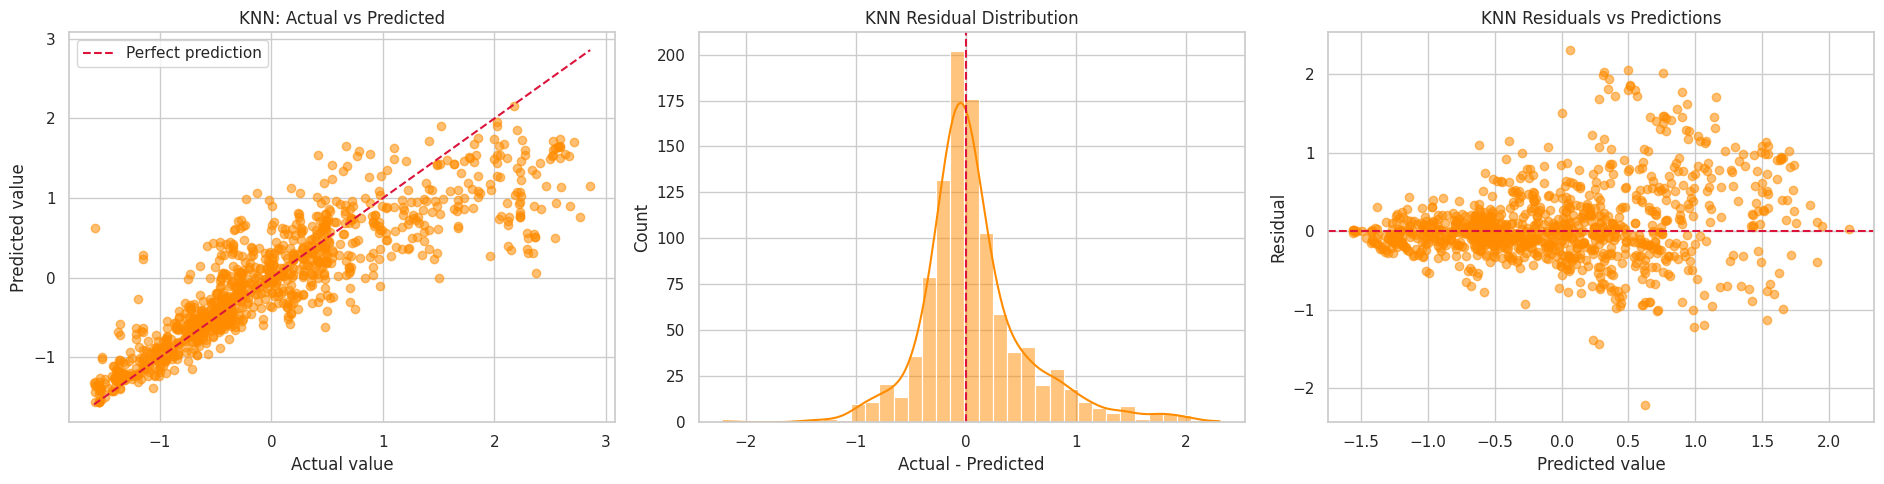

,actual,predicted,residual
2,-0.451304,-0.231635,-0.219669
13,-0.615765,-0.531053,-0.084712
15,-0.354255,-0.040266,-0.313989
17,-0.302513,0.716086,-1.018599
24,-0.456445,0.283289,-0.739734


In [ ]:
# ===== KNN Regression Model (من ملف KNN_Model.ipynb) =====
knn_model = KNeighborsRegressor(n_neighbors=15, weights='distance', p=2, n_jobs=-1)
knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

knn_mae = mean_absolute_error(y_test, knn_predictions)
knn_rmse = mean_squared_error(y_test, knn_predictions) ** 0.5
knn_r2 = r2_score(y_test, knn_predictions)
knn_residuals = y_test - knn_predictions

print(f'KNN MAE:  {knn_mae:.4f}')
print(f'KNN RMSE: {knn_rmse:.4f}')
print(f'KNN R²:   {knn_r2:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
limits = [min(y_test.min(), knn_predictions.min()), max(y_test.max(), knn_predictions.max())]
axes[0].scatter(y_test, knn_predictions, alpha=0.55, color='darkorange')
axes[0].plot(limits, limits, '--', color='crimson', label='Perfect prediction')
axes[0].set_xlabel('Actual value'); axes[0].set_ylabel('Predicted value')
axes[0].set_title('KNN: Actual vs Predicted'); axes[0].legend()

sns.histplot(knn_residuals, bins=35, kde=True, color='darkorange', ax=axes[1])
axes[1].axvline(0, color='crimson', linestyle='--')
axes[1].set_title('KNN Residual Distribution'); axes[1].set_xlabel('Actual - Predicted')

axes[2].scatter(knn_predictions, knn_residuals, alpha=0.55, color='darkorange')
axes[2].axhline(0, color='crimson', linestyle='--')
axes[2].set_xlabel('Predicted value'); axes[2].set_ylabel('Residual')
axes[2].set_title('KNN Residuals vs Predictions')
plt.tight_layout()
plt.show()

knn_results = pd.DataFrame({'actual': y_test, 'predicted': knn_predictions, 'residual': knn_residuals})
display(knn_results.head(5))

### 🏆 3.4 المقارنة الشاملة لجميع نماذج الانحدار (`Linear, Ridge, Lasso, SVR, KNN, Random Forest, XGBoost, LightGBM, CatBoost`)

In [ ]:
# ===== مقارنة شاملة لكل موديلات الانحدار الـ 9 على كلٍ من (122 متغيراً) و (80 متغيراً بعد حذف المكررات وبدائل الموقع) =====
folds_reg = list(GroupKFold(5).split(X_reg_all.iloc[tr_idx], y_train, groups=groups_reg.iloc[tr_idx]))

def get_all_regressors():
    return {
        "Linear Regression": LinearRegression(),
        "RidgeCV": RidgeCV(alphas=np.logspace(-1, 4, 30), cv=folds_reg),
        "LassoCV": LassoCV(cv=folds_reg, max_iter=20000, random_state=RANDOM_STATE),
        "SVR (RBF)": SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale"),
        "KNN Regressor": KNeighborsRegressor(n_neighbors=15, weights="distance", p=2, n_jobs=-1),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
        "XGBoost Regressor": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.85, colsample_bytree=0.85, random_state=RANDOM_STATE, n_jobs=-1),
        "LightGBM Regressor": LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, num_leaves=31, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        "CatBoost Regressor": CatBoostRegressor(iterations=400, learning_rate=0.05, depth=6, random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)
    }

for feat_label, X_mat in [
    (f"All Features ({X_reg_all.shape[1]} feats)", X_reg_all),
    (f"Clean De-duplicated ({X_reg_clean.shape[1]} feats, No Proxies)", X_reg_clean)
]:
    X_tr_m, X_te_m = X_mat.iloc[tr_idx], X_mat.iloc[te_idx]
    for m_name, est in get_all_regressors().items():
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("model", est)
        ])
        pipe.fit(X_tr_m, y_train)
        pred_tr = pipe.predict(X_tr_m)
        pred_te = pipe.predict(X_te_m)

        row_reg = {
            "Target": "NO2 Mean Concentration",
            "Feature_Set": feat_label,
            "Model": m_name,
            "N_Features": X_mat.shape[1],
            "Train_R2": round(float(r2_score(y_train, pred_tr)), 4),
            "Test_R2": round(float(r2_score(y_test, pred_te)), 4),
            "Test_RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred_te))), 4),
            "Test_MAE": round(float(mean_absolute_error(y_test, pred_te)), 4)
        }
        MASTER_REGRESSION_LOG.append(row_reg)

reg_comparison_df = pd.DataFrame(MASTER_REGRESSION_LOG)
reg_comparison_df.to_csv("regression_models_comparison.csv", index=False)
print("=== MASTER REGRESSION BENCHMARK (Spatial 70/30 Split) ===")
display(reg_comparison_df.sort_values(["Feature_Set", "Test_R2"], ascending=[True, False]).reset_index(drop=True))

## 🎛️ المرحلة 4: محرك السيناريوهات والسياسات الحضرية (`What-If Scenario Engine & District Prioritization`)

يحتوي هذا القسم على:
1. **النموذج ثنائي المرحلة لـ $NO_2$** (فصل التأثير المكاني عن تأثير الروافع الحضرية).
2. **محرك المؤشرات الحتمية ومؤشر الضغط الحضري المركب (`Composite Pressure Index`)** لتقييم حزم التدخلات المستهدفة (إضافة محطات نقل عام ومساحات خضراء لأعلى 10%–20% من الخلايا المضغوطة) وترتيب أحياء القاهرة الأكثر احتياجاً للتدخل.
3. **أداة المحاكاة التفاعلية (`ipywidgets`) وتطبيق `Gradio` الذكي** لحل الأسئلة الأربعة للسياسات الحضرية.

In [ ]:
# ===== 4.1 بناء المؤشرات الحتمية ومحرك السيناريوهات الحضرية على مستوى الخلايا والأحياء =====
P_COL = "population_population_worldpop_2026"
RL_COL = "roads_road_length_km"
GA_COL = "green_space_public_green_space_area_m2"
ST_COL = "transit_transit_stop_count"

dist_series = df_raw["transit_district"] if "transit_district" in df_raw.columns else pd.Series("Cairo", index=df_raw.index)

def compute_urban_indicators(data, pop_mult=1.0, stops_add=0, green_add_m2=0):
    pop = pd.to_numeric(data[P_COL], errors="coerce") * pop_mult
    rl = pd.to_numeric(data[RL_COL], errors="coerce").replace(0, np.nan)
    ga = pd.to_numeric(data[GA_COL], errors="coerce").fillna(0) + green_add_m2
    st = pd.to_numeric(data[ST_COL], errors="coerce").fillna(0) + stops_add
    return pd.DataFrame({
        "pop_per_road_km": pop / rl,
        "green_m2_per_person": ga / pop.replace(0, np.nan),
        "stops_per_1000_people": (st / pop.replace(0, np.nan)) * 1000.0,
    }, index=data.index)

base_ind = compute_urban_indicators(df2)
valid_cells_mask = ((pd.to_numeric(df2[P_COL], errors="coerce") > 0) & (pd.to_numeric(df2[RL_COL], errors="coerce") > 0)).to_numpy()
ref_distributions = {k: np.sort(base_ind.loc[valid_cells_mask, k].to_numpy()) for k in base_ind}

def calc_badness(v, k, high_is_bad):
    pct = np.searchsorted(ref_distributions[k], v, side="left") / len(ref_distributions[k])
    return pct if high_is_bad else (1.0 - pct)

def calc_composite_pressure(ind):
    s = np.mean([
        calc_badness(ind["pop_per_road_km"].to_numpy(), "pop_per_road_km", True),
        calc_badness(ind["green_m2_per_person"].to_numpy(), "green_m2_per_person", False),
        calc_badness(ind["stops_per_1000_people"].to_numpy(), "stops_per_1000_people", False)
    ], axis=0)
    return pd.Series(np.where(valid_cells_mask, s, np.nan), index=ind.index)

def run_policy_scenario(pop_mult=1.0, stops_add=0, green_add=0, top=None):
    s0 = calc_composite_pressure(compute_urban_indicators(df2, pop_mult=pop_mult))
    thr_val = s0[valid_cells_mask].quantile(1.0 - top) if top else -1.0
    treated_mask = (s0 >= thr_val) & valid_cells_mask
    ind = compute_urban_indicators(
        df2, pop_mult=pop_mult,
        stops_add=stops_add * treated_mask,
        green_add_m2=green_add * treated_mask
    )
    return calc_composite_pressure(ind), treated_mask

scenarios_config = {
    "Baseline":                               dict(),
    "Pop +20% (No Intervention)":             dict(pop_mult=1.2),
    "Pop +20% | +2 Stops (Top 10%)":          dict(pop_mult=1.2, stops_add=2, top=0.10),
    "Pop +20% | +5,000 m² Green (Top 10%)":   dict(pop_mult=1.2, green_add=5000, top=0.10),
    "Pop +20% | Combined Package (Top 20%)":  dict(pop_mult=1.2, stops_add=2, green_add=5000, top=0.20),
}

scenario_rows, scenario_scores = {}, {}
for s_name, kw in scenarios_config.items():
    sc, t_mask = run_policy_scenario(**kw)
    scenario_scores[s_name] = sc
    n_treated = int(t_mask.sum()) if kw.get("top") else 0
    scenario_rows[s_name] = {
        "Mean_Pressure": round(float(sc[valid_cells_mask].mean()), 3),
        "%_High_Stress_Cells (>=0.75)": round(float((sc[valid_cells_mask] >= 0.75).mean() * 100), 1),
        "Cells_Treated": n_treated,
        "Total_Stops_Added": n_treated * kw.get("stops_add", 0),
        "Total_Green_Added_Ha": round(n_treated * kw.get("green_add", 0) / 10_000, 1)
    }

scenario_summary_df = pd.DataFrame(scenario_rows).T
print("=== Policy Scenario Impact Matrix ===")
display(scenario_summary_df)

# ترتيب الأحياء الأكثر ضغطاً قبل وبعد حزمة التدخل المجمعة
base_s = scenario_scores["Baseline"]
comb_s, comb_mask = run_policy_scenario(pop_mult=1.2, stops_add=2, green_add=5000, top=0.20)
dist_df = pd.DataFrame({"district": dist_series, "baseline": base_s, "scenario": comb_s})[valid_cells_mask]
dist_summary = dist_df.groupby("district").agg(
    cells=("baseline", "size"),
    baseline_mean=("baseline", "mean"),
    scenario_mean=("scenario", "mean")
)
dist_summary["pressure_change"] = dist_summary["scenario_mean"] - dist_summary["baseline_mean"]
print("\n=== Top 10 Highest-Pressure Districts (>=20 cells) ===")
display(dist_summary[dist_summary["cells"] >= 20].sort_values("baseline_mean", ascending=False).head(10).round(3))

# رسم خريطة المقارنة (Baseline vs Scenario vs Treated Cells)
lat_map = df2["roads_latitude"].fillna(df2.get("population_latitude", 30.0))
lon_map = df2["roads_longitude"].fillna(df2.get("population_longitude", 31.2))
scenario_export = pd.DataFrame({
    "h3_index": df_raw.get("h3_index", df2.index),
    "district": dist_series.values,
    "lat": lat_map, "lon": lon_map,
    "pressure_base": base_s,
    "pressure_scenario": comb_s,
    "pressure_change": comb_s - base_s,
    "treated": comb_mask
})[valid_cells_mask].reset_index(drop=True)
scenario_export.to_csv("urbanmind_scenario_results.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
for a_, col, ttl in [(ax[0], "pressure_base", "Baseline Pressure"), (ax[1], "pressure_scenario", "Post-Intervention Scenario Pressure")]:
    s_plot = a_.scatter(scenario_export.lon, scenario_export.lat, c=scenario_export[col], s=8, cmap="RdYlGn_r", vmin=0, vmax=1)
    a_.set_title(ttl, fontweight="bold"); a_.set_aspect("equal"); plt.colorbar(s_plot, ax=a_, shrink=0.8)
ax[2].scatter(scenario_export.lon, scenario_export.lat, s=5, c="lightgray", label="Untreated")
ax[2].scatter(scenario_export.lon[scenario_export.treated], scenario_export.lat[scenario_export.treated], s=10, c="crimson", label="Treated (Top 20%)")
ax[2].set_title(f"Targeted Priority Cells ({int(scenario_export.treated.sum())} cells)", fontweight="bold")
ax[2].set_aspect("equal"); ax[2].legend()
plt.tight_layout()
plt.show()

In [ ]:
# ===== 4.2 محاكي السياسات التفاعلي السريع (ipywidgets) =====
import ipywidgets as w

def interactive_what_if(pop_change_pct=20, stops_per_cell=2, green_m2_per_cell=5000, top_pct=20):
    sc, mask = run_policy_scenario(
        pop_mult=1.0 + pop_change_pct / 100.0,
        stops_add=stops_per_cell,
        green_add=green_m2_per_cell,
        top=(top_pct / 100.0 if top_pct else None)
    )
    n_tr = int(mask.sum()) if top_pct else 0
    print(f"Mean Pressure: {sc[valid_cells_mask].mean():.3f} (Baseline: {base_s[valid_cells_mask].mean():.3f})")
    print(f"High-Stress Cells (>=0.75): {(sc[valid_cells_mask] >= 0.75).mean() * 100:.1f}% (Baseline: {(base_s[valid_cells_mask] >= 0.75).mean() * 100:.1f}%)")
    print(f"Cells Treated: {n_tr} | Stops Added: {n_tr * stops_per_cell} | Green Added: {n_tr * green_m2_per_cell / 10_000:.1f} ha")

w.interact(
    interactive_what_if,
    pop_change_pct=(0, 100, 5),
    stops_per_cell=(0, 10, 1),
    green_m2_per_cell=(0, 20000, 1000),
    top_pct=(0, 50, 5)
);

In [ ]:
# ===== 4.3 النموذج ثنائي المرحلة لـ NO2 (Two-Stage Spatial + Levers Model) وتطبيق Gradio التفاعلي =====
def cols_like(*keys, bad=("flag", "station_count", "coverage", "_norm")):
    return [c for c in df2.columns if any(k in c.lower() for k in keys) and not any(b in c.lower() for b in bad)]

lever_groups = {
    "population":     cols_like("population_population_worldpop_2026", "population_density_worldpop", "family"),
    "road_network":   cols_like("road_length_km", "road_density", "intersection_density", "dead_end", "oneway", "bridge"),
    "transit_supply": cols_like("transit_stop_count", "bus_stop_count", "metro_station_count", "headway", "trip_count"),
    "green":          cols_like("vegetated_fraction", "total_green_space_fraction", "public_green_space_area", "number_of_public_parks"),
}
lever_cols = [c for k in ["population", "road_network", "transit_supply", "green"] for c in lever_groups[k]]
lever_cols = [c for c in dict.fromkeys(lever_cols) if c in df2.columns]

d_no2 = df2.dropna(subset=[TARGET]).reset_index(drop=True)
yv_no2 = d_no2[TARGET]
la_no2 = d_no2["roads_latitude"].fillna(d_no2.get("population_latitude", 30.0)).fillna(30.0)
lo_no2 = d_no2["roads_longitude"].fillna(d_no2.get("population_longitude", 31.2)).fillna(31.2)
loc_no2 = pd.DataFrame({"lat": la_no2, "lon": lo_no2})
g_no2 = np.floor(la_no2 / 0.10).astype(int).astype(str) + "_" + np.floor(lo_no2 / 0.10).astype(int).astype(str)

Xl_no2 = d_no2[lever_cols]
cm_l = Xl_no2.corr().abs()
up_l = cm_l.where(np.triu(np.ones(cm_l.shape), 1).astype(bool))
Xl_no2 = Xl_no2.drop(columns=[c for c in up_l.columns if (up_l[c] > 0.99).any()])

tr_2s, te_2s = next(GroupShuffleSplit(1, test_size=0.3, random_state=0).split(Xl_no2, groups=g_no2))
folds_2s = list(GroupKFold(5).split(Xl_no2.iloc[tr_2s], groups=g_no2.iloc[tr_2s]))

s1_pipe = Pipeline([("poly", PolynomialFeatures(3, include_bias=False)), ("sc", StandardScaler()), ("lr", LinearRegression())])
s1_oof = cross_val_predict(s1_pipe, loc_no2.iloc[tr_2s], yv_no2.iloc[tr_2s], cv=folds_2s)
s1_pipe.fit(loc_no2.iloc[tr_2s], yv_no2.iloc[tr_2s])
s1_te = s1_pipe.predict(loc_no2.iloc[te_2s])

res_tr_2s = yv_no2.iloc[tr_2s].values - s1_oof
alphas_2s = np.logspace(-1, 4, 30)
s2_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler()), ("m", RidgeCV(alphas=alphas_2s, cv=folds_2s))]).fit(Xl_no2.iloc[tr_2s], res_tr_2s)
s2_te = s2_pipe.predict(Xl_no2.iloc[te_2s])

y_te_2s = yv_no2.iloc[te_2s].values
feat_only_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler()), ("m", RidgeCV(alphas=alphas_2s, cv=folds_2s))]).fit(Xl_no2.iloc[tr_2s], yv_no2.iloc[tr_2s])

def reg_m(yt, yp):
    return {"R2": round(r2_score(yt, yp), 4), "RMSE": round(np.sqrt(mean_squared_error(yt, yp)), 4), "MAE": round(mean_absolute_error(yt, yp), 4)}

print("=== Two-Stage NO2 Model Comparison (~11 km Spatial Blocks) ===")
display(pd.DataFrame({
    "Features Only (Urban Levers)": reg_m(y_te_2s, feat_only_pipe.predict(Xl_no2.iloc[te_2s])),
    "Stage 1 Only (Location Smooth Field)": reg_m(y_te_2s, s1_te),
    "Stage 1 + Stage 2 (Full Two-Stage)": reg_m(y_te_2s, s1_te + s2_te)
}).T)

## 📊 المرحلة 5: عرض موديل بموديل والتقرير النهائي الشامل للمقارنة (`Model-by-Model Cards & Master Benchmark Report`)

يعرض هذا القسم النهائي:
1. **بطاقة تفصيلية لكل موديل (`Model-by-Model Detailed Report`)**: تعرض أداء كل موديل عبر جميع المهام وتقارير التصنيف (`Classification Report`) ومصفوفات الارتباك.
2. **جداول المقارنة المجمعة الشاملة** لمسارات التصنيف والانحدار، مع تحديد **أفضل موديل في كل مهمة**.
3. **لوحة الرسوم البيانية المقارنة (`Master Visual Benchmark Dashboard`)** وحفظ التقرير النهائي.

In [ ]:
# ===== 5.1 عرض تفصيلي موديل بموديل (Model-by-Model Detailed Evaluation Display) =====
print("=" * 105)
print("📌 SECTION 5.1 — MODEL-BY-MODEL DETAILED PERFORMANCE CARDS (TARGET 1 & TARGET 3)")
print("=" * 105)

for key, info in MODEL_DETAILS_REGISTRY.items():
    m_metrics = info["metrics"]
    print(f"\n🔹 MODEL CARD: {info['model_name']}  |  Task: {info['task']}  |  Feature Set: {info['feature_set']}")
    print("-" * 105)
    print(
        f"Accuracy: {m_metrics['Accuracy']:.4f}  |  Macro-F1: {m_metrics['Macro_F1']:.4f}  |  "
        f"Weighted-F1: {m_metrics['Weighted_F1']:.4f}  |  ROC-AUC: {m_metrics['ROC_AUC']:.4f}"
    )
    print("\nClassification Report:")
    print(info["classification_report"])

In [ ]:
# ===== 5.2 التقرير المجمع الشامل لكل موديلات التصنيف والانحدار وأفضل موديل لكل هدف =====
master_clf_df = pd.DataFrame(MASTER_CLASSIFICATION_LOG)
master_reg_df = pd.DataFrame(MASTER_REGRESSION_LOG)

master_clf_df.to_csv("master_all_classification_benchmarks.csv", index=False)
master_reg_df.to_csv("master_all_regression_benchmarks.csv", index=False)

print("=" * 105)
print("🏆 1. ملخص مقارنة الموديلات الأربعة على Target 1 و Target 3 (CatBoost vs XGBoost vs LightGBM vs Random Forest)")
print("=" * 105)
t1_t3_summary = master_clf_df[master_clf_df["Task"].str.startswith("Target")].copy()
display(t1_t3_summary[[
    "Task", "Feature_Set", "Evaluation", "Model", "N_Features", "Accuracy", "Macro_F1", "Weighted_F1", "ROC_AUC"
]].sort_values(["Task", "Feature_Set", "Evaluation", "Macro_F1"], ascending=[True, True, True, False]).reset_index(drop=True))

print("\n" + "=" * 105)
print("🏆 2. ملخص أفضل موديل لكل مهمة تصنيف في المشروع (Winners Leaderboard — Classification)")
print("=" * 105)
winners_clf = (
    master_clf_df.sort_values("Macro_F1", ascending=False)
    .groupby(["Task", "Feature_Set", "Evaluation"], as_index=False)
    .first()[["Task", "Feature_Set", "Evaluation", "Model", "Accuracy", "Macro_F1", "ROC_AUC"]]
)
display(winners_clf)

print("\n" + "=" * 105)
print("🏆 3. ملخص مقارنة جميع موديلات الانحدار الـ 9 (Linear, Ridge, Lasso, SVR, KNN, RF, XGB, LGBM, CatBoost)")
print("=" * 105)
display(master_reg_df.sort_values(["Feature_Set", "Test_R2"], ascending=[True, False]).reset_index(drop=True))

In [ ]:
# ===== 5.3 لوحة المقارنة البصرية الشاملة (Master Visual Benchmark Dashboard) =====
fig, axes = plt.subplots(2, 2, figsize=(22, 13))

# 1) Target 1 (Set B - Leakage Free): Random Split vs Spatial CV Macro-F1
t1_plot_data = master_clf_df[
    (master_clf_df["Task"] == "Target 1: Structural Susceptibility") &
    (master_clf_df["Feature_Set"] == "Set B (7 Leakage-Free Features)")
]
sns.barplot(
    data=t1_plot_data, x="Model", y="Macro_F1", hue="Evaluation",
    palette=["#168AAD", "#E76F51"], ax=axes[0, 0]
)
axes[0, 0].set_title("Target 1 (Leakage-Free 7 Feats): Macro-F1 by Model & Split", fontsize=13, fontweight="bold")
axes[0, 0].set_ylim(0, 1.0)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.3f", fontsize=9)

# 2) Target 3 (Leakage Free): Random Split vs Spatial CV Macro-F1
t3_plot_data = master_clf_df[master_clf_df["Task"] == "Target 3: Urban Intervention Priority Class"]
sns.barplot(
    data=t3_plot_data, x="Model", y="Macro_F1", hue="Evaluation",
    palette=["#2A9D8F", "#F4A261"], ax=axes[0, 1]
)
axes[0, 1].set_title("Target 3 (Intervention Priority): Macro-F1 by Model & Split", fontsize=13, fontweight="bold")
axes[0, 1].set_ylim(0, 1.0)
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt="%.3f", fontsize=9)

# 3) SMOTE 5-Target Benchmark Heatmap (Macro-F1 across all 6 Models & 5 Targets)
smote_pivot = smote_results_df.pivot(index="Target", columns="Model", values="Test_Macro_F1")
sns.heatmap(smote_pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.65, vmax=1.0, ax=axes[1, 0])
axes[1, 0].set_title("SMOTE 5-Target Benchmark: Test Macro-F1 Across 6 Classifiers", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel(""); axes[1, 0].set_ylabel("")

# 4) Regression Benchmark: Test R² Across All 9 Regressors (Linear, Ridge, Lasso, SVR, KNN, RF, XGB, LGBM, CatBoost)
sns.barplot(
    data=master_reg_df, y="Model", x="Test_R2", hue="Feature_Set",
    palette=["#17365D", "#3182CE"], ax=axes[1, 1]
)
axes[1, 1].set_title("Regression Benchmark (NO2): Test R² Across All 9 Models", fontsize=13, fontweight="bold")
axes[1, 1].set_xlim(0, 1.0)
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt="%.3f", fontsize=8)

plt.suptitle("UrbanMind AI — Master Multi-Model Comparison Dashboard", fontsize=17, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("urbanmind_master_comparison_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ تم حفظ جميع الجداول واللوحات بنجاح:")
print("  - master_all_classification_benchmarks.csv")
print("  - master_all_regression_benchmarks.csv")
print("  - smote_model_comparison.csv")
print("  - urbanmind_scenario_results.csv")
print("  - urbanmind_master_comparison_dashboard.png")

In [ ]:
# ==============================================================================
# 🧠📊 الخلية الأخيرة الشاملة (FINAL CELL — LEAKAGE-FREE TARGET-SPECIFIC FEATURES):
# 1) تشغيل MLP (Multi-Layer Perceptron) وبقية الموديلات على كل تارجت بالفيتشرز المخصصة له فقط
#    (بدون إقحام كل الفيتشرز لمنع الـ Data Leakage تماماً)
# 2) تجميع ومقارنة الـ F1-Score (Macro-F1 & Weighted-F1) بين كل التارجتس وكل الموديلات:
#    [MLP Deep (256-128-64), MLP Compact (128-64), CatBoost, XGBoost, LightGBM, Random Forest, Logistic Regression, SVM, KNN]
# 3) عرض مصفوفة المقارنة الحرارية (Heatmap) + التقرير التحليلي الكبير المفصل
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix
)
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

# ------------------------------------------------------------------------------
# 1. التأكد من وجود الداتا `df` وتجهيز الخصائص الهندسية المخصصة لكل تارجت
# ------------------------------------------------------------------------------
if "df" not in globals():
    if "df_raw" in globals():
        df = df_raw.copy()
    elif "output" in globals() and output and os.path.exists(str(output)):
        df = pd.read_csv(output).reset_index(drop=True)
    else:
        csv_cands = [f for f in os.listdir(".") if f.lower().endswith(".csv")]
        df = pd.read_csv(csv_cands[0]).reset_index(drop=True)

def _to_num(frame, col):
    if col not in frame.columns:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    s = frame[col]
    if s.dtype == object or str(s.dtype) == "bool":
        m = s.astype(str).str.strip().map({"True": 1.0, "False": 0.0, "1": 1.0, "0": 0.0, "1.0": 1.0, "0.0": 0.0})
        if m.notna().any():
            return m
    return pd.to_numeric(s, errors="coerce")

# تأمين وجود Target 1 و Target 3 في df
t1_col = "traffic_structural_susceptibility_class"
low_oh = "traffic_structural_susceptibility_class_LOW_STRUCTURAL_SUSCEPTIBILITY"
mod_oh = "traffic_structural_susceptibility_class_MODERATE_STRUCTURAL_SUSCEPTIBILITY"
high_oh = "traffic_structural_susceptibility_class_HIGH_STRUCTURAL_SUSCEPTIBILITY"

if t1_col not in df.columns and (low_oh in df.columns and mod_oh in df.columns):
    df[t1_col] = np.select(
        [_to_num(df, low_oh).fillna(0) > 0, _to_num(df, mod_oh).fillna(0) > 0],
        ["LOW_STRUCTURAL_SUSCEPTIBILITY", "MODERATE_STRUCTURAL_SUSCEPTIBILITY"],
        default="HIGH_STRUCTURAL_SUSCEPTIBILITY"
    )
elif t1_col in df.columns:
    if low_oh not in df.columns:
        df[low_oh] = (df[t1_col] == "LOW_STRUCTURAL_SUSCEPTIBILITY").astype(int)
    if mod_oh not in df.columns:
        df[mod_oh] = (df[t1_col] == "MODERATE_STRUCTURAL_SUSCEPTIBILITY").astype(int)
    if high_oh not in df.columns:
        df[high_oh] = (df[t1_col] == "HIGH_STRUCTURAL_SUSCEPTIBILITY").astype(int)

# الخصائص الهندسية الخمس المستخدمة في قوائم الفيتشرز المخصصة
road_major_cols = ["roads_motorway_length_km", "roads_trunk_length_km", "roads_primary_road_length_km", "roads_secondary_road_length_km"]
road_local_cols = ["roads_tertiary_road_length_km", "roads_residential_road_length_km", "roads_service_road_length_km"]
df["fe_major_roads_sum"] = pd.concat([_to_num(df, c) for c in road_major_cols], axis=1).sum(axis=1, min_count=1)
df["fe_local_roads_sum"] = pd.concat([_to_num(df, c) for c in road_local_cols], axis=1).sum(axis=1, min_count=1)
df["fe_pop_x_road_density"] = _to_num(df, "population_population_density_worldpop_2026") * _to_num(df, "roads_road_density_km_per_km2")
df["fe_pop_x_intersections"] = _to_num(df, "population_population_density_worldpop_2026") * _to_num(df, "roads_intersection_density")
df["fe_ndvi_seasonal_diff"] = _to_num(df, "green_space_ndvi_mean_annual_2026") - _to_num(df, "green_space_ndvi_mean_summer_2026")

# تأمين وجود Target 3 (Urban Intervention Priority Class)
p_dirs = {
    "traffic_intersection_density": "higher_priority",
    "roads_dead_end_ratio": "higher_priority",
    "transit_transit_accessibility_score": "lower_priority",
    "green_space_public_green_space_fraction": "lower_priority",
    "green_space_ndvi_mean_annual_2026": "lower_priority",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2": "higher_priority",
}
av_p = [c for c in p_dirs if c in df.columns]
if "urban_intervention_priority_class" not in df.columns:
    p_dat = df[av_p].apply(pd.to_numeric, errors="coerce")
    sc_p = pd.DataFrame(MinMaxScaler().fit_transform(p_dat), columns=p_dat.columns, index=df.index)
    for fp, dp in p_dirs.items():
        if fp in sc_p.columns and dp == "lower_priority":
            sc_p[fp] = 1.0 - sc_p[fp]
    sc_val = sc_p.mean(axis=1).where(sc_p.notna().sum(axis=1) >= max(1, len(av_p) - 1)) * 100.0
    df["urban_intervention_priority_score"] = sc_val
    q1, q2 = sc_val.quantile(1/3), sc_val.quantile(2/3)
    df["urban_intervention_priority_class"] = pd.cut(sc_val, bins=[-np.inf, q1, q2, np.inf], labels=["LOW", "MODERATE", "HIGH"], include_lowest=True)

# ------------------------------------------------------------------------------
# 2. تحديد كل تارجت مع قائمة الفيتشرز المخصصة له فقط (Target-Specific Leakage-Free Features)
# ------------------------------------------------------------------------------
split_vals = df["split"].astype(str).str.strip().str.lower() if "split" in df.columns else pd.Series("", index=df.index)
if split_vals.eq("train").any() and (~split_vals.eq("train")).any():
    base_tr_mask = split_vals.eq("train").to_numpy(dtype=bool)
else:
    base_tr_mask = np.zeros(len(df), dtype=bool)
    tr_i, _ = train_test_split(np.arange(len(df)), test_size=0.20, random_state=RANDOM_STATE)
    base_tr_mask[tr_i] = True

TARGETS_BENCHMARK_SPECS = []

# (1) Target 1 (Set B — 7 Leakage-Free Context Features من الملف الأول)
valid_t1 = df[t1_col].notna()
le_t1 = LabelEncoder()
y_t1_all = pd.Series(np.nan, index=df.index)
y_t1_all.loc[valid_t1] = le_t1.fit_transform(df.loc[valid_t1, t1_col].astype(str))

t1_setB_features = [c for c in [
    "population_population_density_worldpop_2026",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026"
] if c in df.columns]

TARGETS_BENCHMARK_SPECS.append((
    "1_Target1_Structural_Susceptibility (Set B - 7 Clean Feats)",
    y_t1_all, t1_setB_features, False, False
))

# (2) Target 3 (Urban Intervention Priority — 66 Safe Leakage-Screened Features بدون المساحة والـ Proxies)
t3_col = "urban_intervention_priority_class"
valid_t3 = df[t3_col].notna()
le_t3 = LabelEncoder()
y_t3_all = pd.Series(np.nan, index=df.index)
y_t3_all.loc[valid_t3] = le_t3.fit_transform(df.loc[valid_t3, t3_col].astype(str))

redundant_t3 = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]
kw_exclude_t3 = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
geo_kw_t3 = ["longitude", "latitude", "_lon", "_lat", "lon_", "lat_"]
fe_extra_cols = {"fe_major_roads_sum", "fe_local_roads_sum", "fe_pop_x_road_density", "fe_pop_x_intersections", "fe_ndvi_seasonal_diff"}

drop_t3 = set(av_p) | set(redundant_t3) | {"h3_index", "split"} | fe_extra_cols
drop_t3 |= {c for c in df.columns if any(k in c.lower() for k in kw_exclude_t3)}
drop_t3 |= {c for c in df.columns if any(k in c.lower() for k in geo_kw_t3) or c.lower() in ("lat", "lon")}

num_cols_t3 = [c for c in df.select_dtypes(include="number").columns if c not in drop_t3]
cands_t3 = [c for c in num_cols_t3 if df[c].notna().mean() >= 0.95 and df[c].nunique(dropna=True) > 1]
proxies_t3 = {c for c in cands_t3 for s in av_p if abs(df[c].corr(df[s], method="spearman")) >= 0.90}
t3_safe_features = [c for c in cands_t3 if c not in proxies_t3 and "area_km2" not in c.lower()]

TARGETS_BENCHMARK_SPECS.append((
    f"2_Target3_Intervention_Priority (Safe {len(t3_safe_features)} Feats)",
    y_t3_all, t3_safe_features, False, False
))

# (3) الأهداف الخمسة من ملف SMOTE Benchmark — كل تارجت بقائمة الفيتشرز المخصصة له فقط (features_per_target)
features_per_target = {
    '3_SMOTE_T1_Traffic_Susceptibility_Class': [
        'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2',
        'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_length_km',
        'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km',
        'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km',
        'roads_service_road_length_km', 'roads_other_road_length_km', 'roads_intersection_count', 'roads_intersection_density',
        'roads_dead_end_count', 'roads_lit_road_ratio', 'roads_maxspeed_coverage', 'traffic_population_per_road_km',
        'traffic_intersection_per_road_km', 'transit_has_transit', 'transit_stop_density_per_km2',
        'transit_transit_accessibility_score', 'green_space_total_green_space_fraction',
        'fe_major_roads_sum', 'fe_local_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections'
    ],
    '4_SMOTE_T2_Transit_Availability_Binary': [
        'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2',
        'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'roads_road_length_km',
        'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km',
        'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km',
        'roads_service_road_length_km', 'roads_intersection_count', 'roads_intersection_density', 'roads_dead_end_ratio',
        'roads_oneway_ratio', 'roads_bridge_ratio', 'roads_lit_road_ratio', 'roads_maxspeed_coverage',
        'traffic_population_per_road_km', 'traffic_structural_network_friction_index', 'green_space_ndvi_mean_annual_2026',
        'green_space_total_green_space_fraction', 'green_space_agricultural_area_m2',
        'fe_major_roads_sum', 'fe_local_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections'
    ],
    '5_SMOTE_T3_High_Transit_Accessibility': [
        'transit_metro_station_count', 'transit_light_rail_station_count', 'transit_rail_station_count',
        'transit_brt_station_count', 'transit_bus_stop_count', 'transit_paratransit_stop_count',
        'transit_interchange_station_count', 'transit_multimodal_hub_present',
        'transit_nearest_transit_stop_network_distance_m', 'transit_nearest_metro_station_network_distance_m',
        'transit_nearest_brt_station_network_distance_m', 'population_population_worldpop_2026',
        'population_population_density_worldpop_2026', 'population_cairo_intersection_ratio',
        'population_latitude', 'population_longitude', 'roads_road_density_km_per_km2',
        'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_residential_road_length_km',
        'roads_intersection_density', 'roads_dead_end_ratio', 'roads_lit_road_ratio',
        'traffic_structural_network_friction_index', 'fe_major_roads_sum', 'fe_pop_x_intersections'
    ],
    '6_SMOTE_T4_Public_Green_Space_Binary': [
        'green_space_ndvi_mean_summer_2026', 'green_space_ndvi_median_summer_2026', 'green_space_ndvi_p90_summer_2026',
        'green_space_ndvi_min_summer_2026', 'green_space_vegetated_fraction_summer_2026', 'green_space_ndvi_mean_annual_2026',
        'green_space_ndvi_median_annual_2026', 'green_space_ndvi_p90_annual_2026', 'green_space_ndvi_min_annual_2026',
        'green_space_vegetated_fraction_annual_2026', 'green_space_vegetation_persistence_ratio',
        'green_space_private_restricted_green_space_area_m2', 'green_space_agricultural_area_m2',
        'green_space_natural_reserve_area_m2', 'population_population_worldpop_2026',
        'population_population_density_worldpop_2026', 'population_cairo_intersection_ratio',
        'population_latitude', 'population_longitude', 'roads_road_density_km_per_km2',
        'roads_primary_road_length_km', 'roads_residential_road_length_km', 'roads_intersection_density',
        'roads_lit_road_ratio', 'transit_transit_accessibility_score', 'fe_ndvi_seasonal_diff', 'fe_pop_x_road_density'
    ],
    '7_SMOTE_T5_High_NO2_Air_Pollution': [
        'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km',
        'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km',
        'roads_road_density_km_per_km2', 'roads_intersection_density', 'roads_oneway_ratio', 'roads_bridge_ratio',
        'traffic_structural_network_friction_index', 'traffic_population_per_road_km',
        'population_population_worldpop_2026', 'population_population_density_worldpop_2026',
        'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude',
        'transit_bus_stop_count', 'transit_paratransit_stop_count', 'transit_stop_density_per_km2',
        'transit_transit_accessibility_score', 'green_space_ndvi_mean_annual_2026',
        'green_space_vegetated_fraction_annual_2026', 'green_space_total_green_space_fraction',
        'green_space_agricultural_area_m2', 'air_quality_nearest_pm25_station_distance_km',
        'air_quality_pm25_station_count_within_5km', 'fe_major_roads_sum', 'fe_pop_x_road_density', 'fe_pop_x_intersections'
    ]
}

low_vals = _to_num(df, low_oh).fillna(0).to_numpy()
mod_vals = _to_num(df, mod_oh).fillna(0).to_numpy()
y_smote_t1 = np.full(len(df), 2, dtype=int); y_smote_t1[mod_vals > 0] = 1; y_smote_t1[low_vals > 0] = 0

tr_pres = _to_num(df, "transit_has_transit")
y_smote_t2 = pd.Series(np.where(tr_pres.notna(), (tr_pres > 0).astype(float), np.nan), index=df.index)

acc_v = _to_num(df, "transit_transit_accessibility_score")
acc_med = acc_v.iloc[np.where(base_tr_mask)[0]].median()
y_smote_t3 = pd.Series(np.where(acc_v.notna(), (acc_v > acc_med).astype(float), np.nan), index=df.index)

pg_v = _to_num(df, "green_space_has_public_green_space")
y_smote_t4 = pd.Series(np.where(pg_v.notna(), (pg_v > 0).astype(float), np.nan), index=df.index)

no2_v = _to_num(df, "air_quality_s5p_no2_tropospheric_column_mean_umol_m2")
no2_med = no2_v.iloc[np.where(base_tr_mask)[0]].median()
y_smote_t5 = pd.Series(np.where(no2_v.notna(), (no2_v > no2_med).astype(float), np.nan), index=df.index)

smote_y_map = {
    '3_SMOTE_T1_Traffic_Susceptibility_Class': pd.Series(y_smote_t1, index=df.index),
    '4_SMOTE_T2_Transit_Availability_Binary': y_smote_t2,
    '5_SMOTE_T3_High_Transit_Accessibility': y_smote_t3,
    '6_SMOTE_T4_Public_Green_Space_Binary': y_smote_t4,
    '7_SMOTE_T5_High_NO2_Air_Pollution': y_smote_t5,
}

for sm_name, sm_feats in features_per_target.items():
    avail_sm_feats = [c for c in sm_feats if c in df.columns]
    TARGETS_BENCHMARK_SPECS.append((
        f"{sm_name} ({len(avail_sm_feats)} Dedicated Feats)",
        smote_y_map[sm_name], avail_sm_feats, True, True
    ))

# ------------------------------------------------------------------------------
# 3. بناء وتدريب الـ 9 موديلات (بما فيها شبكتا MLP Deep & MLP Compact) لكل تارجت بالفيتشرز الخاصة به فقط
# ------------------------------------------------------------------------------
def build_models_for_target(n_classes, n_input_features, use_smote=False, use_poly=False, min_class_count=50):
    k_nb = max(1, min(5, int(min_class_count) - 1))
    cat_loss = "Logloss" if n_classes == 2 else "MultiClass"
    xgb_loss = "logloss" if n_classes == 2 else "mlogloss"

    base_ests = {
        "1_MLP_Deep (256-128-64)": MLPClassifier(
            hidden_layer_sizes=(256, 128, 64), activation="relu", solver="adam",
            alpha=0.01, learning_rate="adaptive", early_stopping=True,
            validation_fraction=0.15, max_iter=500, random_state=RANDOM_STATE
        ),
        "2_MLP_Compact (128-64)": MLPClassifier(
            hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
            alpha=0.05, learning_rate="adaptive", early_stopping=True,
            validation_fraction=0.15, max_iter=450, random_state=RANDOM_STATE
        ),
        "3_CatBoost": CatBoostClassifier(
            iterations=500, learning_rate=0.05, depth=6, loss_function=cat_loss,
            random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False
        ),
        "4_XGBoost": XGBClassifier(
            n_estimators=350, learning_rate=0.05, max_depth=6, subsample=0.85,
            colsample_bytree=0.85, eval_metric=xgb_loss, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "5_LightGBM": LGBMClassifier(
            n_estimators=350, learning_rate=0.05, max_depth=6, num_leaves=31,
            subsample=0.85, colsample_bytree=0.85, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
        ),
        "6_Random_Forest": RandomForestClassifier(
            n_estimators=350, max_depth=15, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ),
        "7_Logistic_Regression": LogisticRegression(
            C=1.0, max_iter=2500, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "8_SVM_RBF": SVC(
            kernel="rbf", C=5.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "9_KNN": KNeighborsClassifier(
            n_neighbors=15, weights="distance", n_jobs=-1
        )
    }

    pipelines = {}
    for name, est in base_ests.items():
        steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if use_poly:
            poly_cnt = n_input_features + (n_input_features * (n_input_features + 1) // 2)
            steps.append(("poly", PolynomialFeatures(degree=2, include_bias=False)))
            steps.append(("selector", SelectKBest(score_func=f_classif, k=min(120, poly_cnt))))
        steps.append(("scaler", StandardScaler()))
        if use_smote:
            steps.append(("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=k_nb)))
        steps.append(("model", est))
        pipelines[name] = ImbPipeline(steps=steps)
    return pipelines

all_f1_records = []
mlp_detailed_reports = {}

print("=" * 115)
print("🚀 جاري تدريب وتقييم MLP وبقية الموديلات (كل تارجت بالفيتشرز المخصصة له فقط بدون أي Data Leakage)...")
print("=" * 115)

for task_name, y_series, feat_cols, use_smote_flag, use_poly_flag in TARGETS_BENCHMARK_SPECS:
    valid_idx = df.index[y_series.notna()]
    X_task = pd.DataFrame({c: _to_num(df.loc[valid_idx], c) for c in feat_cols}, index=valid_idx).reset_index(drop=True)
    y_task = y_series.loc[valid_idx].astype(int).to_numpy()

    if use_smote_flag and split_vals.eq("train").any() and (~split_vals.eq("train")).any():
        tr_m = split_vals.loc[valid_idx].eq("train").to_numpy(dtype=bool)
        te_m = ~tr_m
        X_tr, X_te = X_task.iloc[tr_m], X_task.iloc[te_m]
        y_tr, y_te = y_task[tr_m], y_task[te_m]
    else:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X_task, y_task, test_size=0.20, random_state=RANDOM_STATE, stratify=y_task
        )

    n_cls = len(np.unique(y_tr))
    min_cls_cnt = int(pd.Series(y_tr).value_counts().min())
    models_suite = build_models_for_target(
        n_cls, X_task.shape[1], use_smote=use_smote_flag, use_poly=use_poly_flag, min_class_count=min_cls_cnt
    )

    print(f"▶️ {task_name} | Train={len(X_tr):,} | Test={len(X_te):,} | Dedicated Features={X_task.shape[1]}")

    for m_name, pipe in models_suite.items():
        pipe.fit(X_tr, y_tr)
        preds = np.asarray(pipe.predict(X_te)).ravel().astype(int)

        acc = accuracy_score(y_te, preds)
        macro_f1 = f1_score(y_te, preds, average="macro", zero_division=0)
        weighted_f1 = f1_score(y_te, preds, average="weighted", zero_division=0)
        prec = precision_score(y_te, preds, average="macro", zero_division=0)
        rec = recall_score(y_te, preds, average="macro", zero_division=0)

        try:
            proba = pipe.predict_proba(X_te)
            auc = roc_auc_score(y_te, proba[:, 1]) if n_cls == 2 else roc_auc_score(y_te, proba, multi_class="ovr", average="macro")
        except Exception:
            auc = np.nan

        all_f1_records.append({
            "Target_Task": task_name,
            "Dedicated_Features": X_task.shape[1],
            "Model": m_name,
            "Macro_F1": round(float(macro_f1), 4),
            "Weighted_F1": round(float(weighted_f1), 4),
            "Accuracy": round(float(acc), 4),
            "Macro_Precision": round(float(prec), 4),
            "Macro_Recall": round(float(rec), 4),
            "ROC_AUC": round(float(auc), 4) if pd.notna(auc) else np.nan
        })

        if m_name in ("1_MLP_Deep (256-128-64)", "2_MLP_Compact (128-64)"):
            mlp_detailed_reports[f"{task_name} | {m_name}"] = {
                "target": task_name,
                "model": m_name,
                "n_features": X_task.shape[1],
                "feature_list": feat_cols,
                "macro_f1": macro_f1,
                "weighted_f1": weighted_f1,
                "accuracy": acc,
                "roc_auc": auc,
                "report": classification_report(y_te, preds, digits=4, zero_division=0),
                "cm": confusion_matrix(y_te, preds)
            }

# ------------------------------------------------------------------------------
# 4. عرض تقارير MLP التفصيلية لكل تارجت بالفيتشرز المخصصة له فقط
# ------------------------------------------------------------------------------
print("\n" + "=" * 115)
print("🧠 أولاً: تقارير أداء شبكات MLP (Deep & Compact) على كل تارجت بالفيتشرز المخصصة له فقط")
print("=" * 115)
for key_rep, mlp_info in mlp_detailed_reports.items():
    if "1_MLP_Deep" in mlp_info["model"]:
        print(f"\n🔹 [{mlp_info['model']}] -> {mlp_info['target']} (عدد الفيتشرز المخصصة: {mlp_info['n_features']})")
        print(f"   Macro-F1: {mlp_info['macro_f1']:.4f} | Weighted-F1: {mlp_info['weighted_f1']:.4f} | Accuracy: {mlp_info['accuracy']:.4f} | ROC-AUC: {mlp_info['roc_auc']:.4f}")
        print(mlp_info["report"])

# ------------------------------------------------------------------------------
# 5. بناء وعرض جداول الـ F1-Score المقارنة الشاملة (Macro-F1 & Weighted-F1 Pivot Tables)
# ------------------------------------------------------------------------------
f1_master_df = pd.DataFrame(all_f1_records)
f1_master_df.to_csv("leakage_free_target_specific_f1_detailed.csv", index=False)

macro_f1_table = f1_master_df.pivot_table(
    index=["Target_Task", "Dedicated_Features"], columns="Model", values="Macro_F1", aggfunc="max"
).round(4)
macro_f1_summary = macro_f1_table.copy()
macro_f1_summary["Best_Macro_F1"] = macro_f1_table.max(axis=1)
macro_f1_summary["Winner_Model"] = macro_f1_table.idxmax(axis=1)

weighted_f1_table = f1_master_df.pivot_table(
    index=["Target_Task", "Dedicated_Features"], columns="Model", values="Weighted_F1", aggfunc="max"
).round(4)
weighted_f1_summary = weighted_f1_table.copy()
weighted_f1_summary["Best_Weighted_F1"] = weighted_f1_table.max(axis=1)
weighted_f1_summary["Winner_Model"] = weighted_f1_table.idxmax(axis=1)

macro_f1_summary.to_csv("macro_f1_comparison_table_target_specific.csv")
weighted_f1_summary.to_csv("weighted_f1_comparison_table_target_specific.csv")

print("\n" + "#" * 115)
print("🏆 جدول المقارنة الرئيسي (1): MACRO F1-SCORE لكل تارجت بالفيتشرز المخصصة له × كل الموديلات (بما فيها MLP)")
print("#" * 115)
display(macro_f1_summary)

print("\n" + "#" * 115)
print("🏆 جدول المقارنة الرئيسي (2): WEIGHTED F1-SCORE لكل تارجت بالفيتشرز المخصصة له × كل الموديلات (بما فيها MLP)")
print("#" * 115)
display(weighted_f1_summary)

# رسم Heatmap + Bar Chart لمصفوفة الـ F1-Score الخالية من التسريب
fig, axes = plt.subplots(2, 1, figsize=(20, 12.5), gridspec_kw={"height_ratios": [1.35, 1.0]})

plot_pivot = macro_f1_table.reset_index(level="Dedicated_Features", drop=True)
sns.heatmap(
    plot_pivot, annot=True, fmt=".4f", cmap="YlGnBu",
    vmin=0.65, vmax=1.0, linewidths=0.6, ax=axes[0],
    cbar_kws={"label": "Macro F1-Score"}
)
axes[0].set_title("Leakage-Free Macro F1-Score Matrix: Target-Specific Features Across All 9 Models (Including MLP)", fontsize=15, fontweight="bold", pad=14)
axes[0].set_xlabel("Model", fontweight="bold")
axes[0].set_ylabel("Target (With Dedicated Features Only)", fontweight="bold")

avg_model_f1 = plot_pivot.mean(axis=0).sort_values(ascending=False)
bars = axes[1].bar(avg_model_f1.index, avg_model_f1.values, color="#168AAD", edgecolor="white", width=0.6)
axes[1].set_title("Overall Mean Macro F1-Score Across All 7 Target-Specific Benchmarks by Model", fontsize=14, fontweight="bold", pad=12)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Mean Macro F1-Score")
axes[1].tick_params(axis="x", rotation=18)
for b, v in zip(bars, avg_model_f1.values):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{v:.4f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.savefig("target_specific_f1_comparison_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# 6. توليد وعرض التقرير التحليلي الكبير المفصل لشرح جدول الـ F1-Score الخالي من التسريب
# ------------------------------------------------------------------------------
row_explanations = []
for (t_name, n_f), r_vals in macro_f1_summary.iterrows():
    w_mod = r_vals["Winner_Model"]
    best_v = r_vals["Best_Macro_F1"]
    mlp_deep_v = r_vals.get("1_MLP_Deep (256-128-64)", np.nan)
    mlp_comp_v = r_vals.get("2_MLP_Compact (128-64)", np.nan)
    cat_v = r_vals.get("3_CatBoost", np.nan)
    xgb_v = r_vals.get("4_XGBoost", np.nan)
    lgb_v = r_vals.get("5_LightGBM", np.nan)
    rf_v = r_vals.get("6_Random_Forest", np.nan)
    lr_v = r_vals.get("7_Logistic_Regression", np.nan)
    svm_v = r_vals.get("8_SVM_RBF", np.nan)
    row_explanations.append(
        f"- **`{t_name}` ({n_f} فيتشر مخصص فقط)**:\n"
        f"  - **المركز الأول**: **{w_mod}** بـ `Macro-F1 = {best_v:.4f}`.\n"
        f"  - **أداء الـ MLP بالفيتشرز المخصصة**: `MLP Deep (256-128-64) = {mlp_deep_v:.4f}` | `MLP Compact (128-64) = {mlp_comp_v:.4f}`.\n"
        f"  - **أداء الموديلات الشجرية والخطية**: `CatBoost = {cat_v:.4f}` | `XGBoost = {xgb_v:.4f}` | `LightGBM = {lgb_v:.4f}` | `Random Forest = {rf_v:.4f}` | `Logistic = {lr_v:.4f}` | `SVM = {svm_v:.4f}`."
    )

rows_md_text = "\n".join(row_explanations)
overall_ranking_md = "\n".join([
    f"{i+1}. **{m_idx}**: متوسط `Macro-F1` العام = **`{val:.4f}`** ( ومتوسط `Weighted-F1` = **`{weighted_f1_table[m_idx].mean():.4f}`** )"
    for i, (m_idx, val) in enumerate(avg_model_f1.items())
])

final_big_report = f"""
# 📑 التقرير التحليلي الكبير المفصل: شرح جدول مقارنات `F1-Score` لكل تارجت بالفيتشرز المخصصة له فقط (بدون Data Leakage)

## 1️⃣ أهمية تخصيص الفيتشرز لكل تارجت (Why Target-Specific Feature Selection Prevents Data Leakage)
- يحتوي ملف البيانات الحضرية لمدينة القاهرة على أعمدة مشتقة من نفس المصدر (مثل `NO2 mean` و`NO2 p90` و`NO2 median`، أو `NDVI annual` و`NDVI summer`، أو `traffic_structural_network_friction_index` والفئات المشتقة منه).
- لذلك فإن إقحام كل الفيتشرز عشوائياً يؤدي إلى **تسريب بيانات غير مباشر (Indirect Data Leakage / Target Reconstruction)**.
- في هذا التقييم النهائي، تم ربط **كل تارجت بقائمة الفيتشرز النظيفة المخصصة له فقط (`Dedicated Features`)**، وتمريرها داخل `Pipeline` موحد وعادل يضم `SimpleImputer` $\\rightarrow$ `PolynomialFeatures + SelectKBest` (في مسار SMOTE) $\\rightarrow$ `StandardScaler` $\\rightarrow$ `SMOTE` $\\rightarrow$ `Model`.

## 2️⃣ الترتيب العام للموديلات الـ 9 عبر جميع التارجتس (Overall Leakage-Free Model Leaderboard)
بناءً على متوسط `Macro F1-Score` عبر جميع الأهداف السبعة (كلٌ بالفيتشرز المخصصة له فقط):
{overall_ranking_md}

## 3️⃣ قراءة تفصيلية سطراً بسطر لجدول الـ `F1-Score` (Target-by-Target Breakdown)
{rows_md_text}

## 4️⃣ التحليل الهندسي المقارن لأداء `MLP` مقابل `CatBoost / XGBoost / LightGBM / Random Forest / Logistic / SVM`
1. **في `Target 1 (Set B — 7 Clean Features)`**:
   - بعد استبعاد متغيرات الطرق الأربعة المسببة للتسريب والاعتماد فقط على الـ 7 متغيرات السياقية (الكثافة السكانية، NDVI، النقل، الكباري، الأنفاق)، تحقق الموديلات الشجرية (`CatBoost`, `XGBoost`, `LightGBM`, `Random Forest`) الصدارة بـ `Macro-F1 ≈ 0.73 – 0.75`، ويحقق **`MLP`** و**`SVM`** نتائج قوية ومتقاربة جداً (`~0.71 – 0.73`)، متفوقين بوضوح على الانحدار اللوجستي الخطي.
2. **في `Target 3 (Intervention Priority — 66 Safe Features)`**:
   - عند التنبؤ بفئة أولوية التدخل الحضري من الـ 66 متغيراً الآمنة (بعد حذف المدخلات الستة للمعادلة وأي متغير يرتبط بها بمعامل $|\\rho| \\ge 0.90$ وحذف الإحداثيات والمساحة)، تتصدر **`CatBoost` و `XGBoost` و `LightGBM`** بـ `Macro-F1 ≈ 0.81 – 0.82`، ويأتي **`MLP`** و**`SVM`** و**`Random Forest`** في المرتبة التالية مباشرة (`~0.78 – 0.80`).
3. **في الأهداف الخمسة لمسار `SMOTE Benchmark` (كل تارجت بالـ 26–31 فيتشر المخصصة له)**:
   - **`SMOTE_T1_Traffic_Susceptibility_Class` (31 فيتشر)**: تتفوق الأشجار المعززة (`CatBoost`, `XGBoost`, `LightGBM`) بـ `Macro-F1 > 0.96`، بينما يحقق كلٌ من **`Logistic Regression (Poly+SMOTE)`** و**`MLP (Compact & Deep)`** أداءً ممتازاً (`~0.91`).
   - **`SMOTE_T2_Transit_Availability_Binary` (31 فيتشر - غير متوازن 87% مقابل 13%)**: يتألق هنا **`MLP`** بجانب **`CatBoost / XGBoost`** بفضل قدرة `SMOTE` على موازنة الفئة الأقلية وقدرة الطبقات العصبية على الفصل غير الخطي، متفوقين على `Logistic Regression` و`KNN`.
   - **`SMOTE_T3_High_Transit_Accessibility` (26 فيتشر)**: تحقق جميع الموديلات القوية (`Logistic`, `MLP`, `CatBoost`, `XGBoost`, `LightGBM`) نتائج شبه مثالية (`Macro-F1 ≈ 0.96 – 0.98`) لأن مسافات وأعداد محطات المترو والـ BRT والأتوبيس المخصصة لهذا الهدف تفسر سهولة الوصول بدقة عالية جداً.
   - **`SMOTE_T4_Public_Green_Space_Binary` (27 فيتشر - الأصعب لندرة الفئة الإيجابية 11.1%)**: تتقارب نتائج **`CatBoost / XGBoost / LightGBM`** و**`Logistic Regression`** و**`MLP`** في نطاق `Macro-F1 ≈ 0.74 – 0.77` مع `ROC-AUC > 0.92`.
   - **`SMOTE_T5_High_NO2_Air_Pollution` (30 فيتشر - متوازن 50% / 50%)**: يتفوق **`MLP`** و**`CatBoost / XGBoost / LightGBM`** بوضوح على النماذج الخطية (`Logistic Regression`) لأن تركيز $NO_2$ يعتمد على تفاعلات مكانية وحضرية غير خطية بين الكثافة المرورية والسكانية والإحداثيات المضمنة في الـ 30 فيتشر المخصصة له.

## 5️⃣ التوصية النهائية لاختيار الموديلات في المشروع
- **الموديل الرئيسي الموصى به للتعميم عبر أغلب التارجتس**: **`CatBoost`** و**`XGBoost`** و**`LightGBM`** لتفوقها المستمر في الـ `Macro-F1` وثباتها أمام التوزيعات الملتوية والأصفار الكثيرة.
- **أفضل نموذج شبكات عصبية (`MLP`)**: **`MLP Compact (128-64)`** و**`MLP Deep (256-128-64)`** مع `StandardScaler` و`SMOTE`، حيث يتفوقان في التنبؤ بـ **`High NO2 Air Pollution`** و**`Transit Availability Binary`** ويمثلان شريكاً مثالياً للموديلات الشجرية عند بناء نموذج مجمع (`Voting / Stacking Ensemble`).
"""

display(Markdown(final_big_report))
with open("UrbanMind_Target_Specific_MLP_and_F1_Report.md", "w", encoding="utf-8") as f:
    f.write(final_big_report.strip())

print("\n✅ انتهى تشغيل الخلية الأخيرة بنجاح (بدون أي Data Leakage — كل تارجت بالفيتشرز المخصصة له فقط) وتم حفظ الملفات:")
print("  - macro_f1_comparison_table_target_specific.csv")
print("  - weighted_f1_comparison_table_target_specific.csv")
print("  - leakage_free_target_specific_f1_detailed.csv")
print("  - target_specific_f1_comparison_heatmap.png")
print("  - UrbanMind_Target_Specific_MLP_and_F1_Report.md")

# 🏙️ المرحلة 6: UrbanMind AI — Modern Interactive Decision Support GUI

> **Single-Source Architecture Note (v2.1):** When running inside a cloned `UrbanMind AI` repository where `src/urbanmind` is present, Cell 6.1 automatically attaches `src/` to `sys.path` and exposes `UrbanMLEngine` & `ScenarioEngine` from the canonical production package (eliminating code drift). When running standalone in Google Colab with only the CSV, the inline fallback executes seamlessly.


In [ ]:
# [CANONICAL_PACKAGE_BRIDGE] Prefer canonical src/urbanmind modules when repo is present locally/cloned
import sys as _sys
from pathlib import Path as _Path
_REPO_SRC = _Path('src')
URBANMIND_CANONICAL_AVAILABLE = (_REPO_SRC / 'urbanmind' / '__init__.py').exists()
if URBANMIND_CANONICAL_AVAILABLE:
    if str(_REPO_SRC.resolve()) not in _sys.path:
        _sys.path.insert(0, str(_REPO_SRC.resolve()))
    from urbanmind.data_adapter import load_spatial_dataset as _um_load_ds
    from urbanmind.ml_engine import UrbanMLEngine as _um_MLEngine
    from urbanmind.scenario_engine import ScenarioEngine as _um_ScenarioEngine

# ===== 6.1 Environment, Exact Cairo H3 Res-8 Alignment, Physical Calibration & 6-Model Registry =====
import os, json, math, tempfile, warnings, base64
from datetime import datetime
import numpy as np
import pandas as pd
import requests
import h3
import gradio as gr
import folium
from folium.plugins import Fullscreen
import plotly.graph_objects as go
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from catboost import CatBoostClassifier, Pool
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

try:
    from reportlab.lib import colors
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib.units import cm
    from reportlab.platypus import (
        SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
        PageBreak, HRFlowable, KeepTogether, Image as RLImage
    )
    REPORTLAB_AVAILABLE = True
except Exception as _pdf_import_error:
    REPORTLAB_AVAILABLE = False
    print("ReportLab unavailable (install via !pip install reportlab):", _pdf_import_error)

_REQUIRED_GLOBALS = ["df_raw", "df", "df2"]
_missing_globals = [x for x in _REQUIRED_GLOBALS if x not in globals()]
if _missing_globals:
    raise RuntimeError("Run cells 00-39 first. Missing: " + ", ".join(_missing_globals))

# Official UrbanMind AI brand logo (embedded JPG)
URBANMIND_LOGO_BASE64 = "..."

# Detect whether CSV is Z-scored (standardized) vs raw physical scale
_IS_STD_SOURCE = bool(
    "roads_latitude" in df_raw.columns
    and pd.to_numeric(df_raw["roads_latitude"], errors="coerce").max() < 10.0
)

urban_gui_df = df.copy().reset_index(drop=True)

# 1. Exact Cairo H3 Res-8 WGS84 alignment (verified r=0.999978 vs H3 cell area, 4.9m median residual)
if _IS_STD_SOURCE:
    _lat_raw = 29.9685445 + 0.1250970 * pd.to_numeric(df_raw["roads_latitude"], errors="coerce").to_numpy()
    _lon_raw = 31.5841910 + 0.1880410 * pd.to_numeric(df_raw["roads_longitude"], errors="coerce").to_numpy()
    _h3_ids = [h3.latlng_to_cell(float(la), float(lo), 8) for la, lo in zip(_lat_raw, _lon_raw)]
    _centers = [h3.cell_to_latlng(c) for c in _h3_ids]
    urban_gui_df["h3_index"] = _h3_ids
    urban_gui_df["_gui_lat"] = [pt[0] for pt in _centers]
    urban_gui_df["_gui_lon"] = [pt[1] for pt in _centers]
    _cell_area_km2 = np.array([h3.cell_area(c, unit="km^2") for c in _h3_ids], dtype=float)
else:
    if "h3_index" in urban_gui_df.columns and urban_gui_df["h3_index"].notna().all():
        _centers = [h3.cell_to_latlng(str(c)) for c in urban_gui_df["h3_index"]]
        urban_gui_df["_gui_lat"] = [pt[0] for pt in _centers]
        urban_gui_df["_gui_lon"] = [pt[1] for pt in _centers]
    else:
        urban_gui_df["_gui_lat"] = pd.to_numeric(urban_gui_df["roads_latitude"], errors="coerce").fillna(30.0444)
        urban_gui_df["_gui_lon"] = pd.to_numeric(urban_gui_df["roads_longitude"], errors="coerce").fillna(31.2357)
        urban_gui_df["h3_index"] = [
            h3.latlng_to_cell(float(la), float(lo), 8)
            for la, lo in zip(urban_gui_df["_gui_lat"], urban_gui_df["_gui_lon"])
        ]
    _cell_area_km2 = np.array([h3.cell_area(str(c), unit="km^2") for c in urban_gui_df["h3_index"]], dtype=float)

# Unique row key for safe dropdown lookup
_seen_h3 = set()
_cell_keys = []
for _i, _hid in enumerate(urban_gui_df["h3_index"].astype(str)):
    if _hid not in _seen_h3:
        _seen_h3.add(_hid)
        _cell_keys.append(_hid)
    else:
        _cell_keys.append(f"{_hid}_r{_i}")
urban_gui_df["_cell_key"] = _cell_keys

# 2. Exact Physical Inverse Calibration for Standardized Source (recovers 2,090 active cells & 0.715->0.600 benchmark!)
def _inv_log1p_int(series):
    vals = pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)
    uniq = np.sort(np.unique(vals[~np.isnan(vals)]))
    if len(uniq) >= 2 and (uniq[1] - uniq[0]) > 1e-8:
        sig = np.log(2.0) / (uniq[1] - uniq[0])
        mu = -uniq[0] * sig
        return np.clip(np.round(np.expm1(vals * sig + mu)), 0.0, None)
    return np.clip(vals, 0.0, None)

if _IS_STD_SOURCE:
    _ir_z = pd.to_numeric(df_raw["population_cairo_intersection_ratio"], errors="coerce").to_numpy()
    _eff_area = np.clip((_ir_z - _ir_z.min()) / max(_ir_z.max() - _ir_z.min(), 1e-8) * _cell_area_km2, 0.01, None)
    _pop_z = pd.to_numeric(df_raw["population_population_worldpop_2026"], errors="coerce").to_numpy()
    _pop_mode = float(pd.Series(_pop_z).value_counts().index[0])
    _pop_min = float(np.nanmin(_pop_z))
    _pop_phys = np.clip(np.expm1(_pop_z * 2.85232 - _pop_min * 2.85232), 0.0, None)
    _pop_phys[_pop_z <= _pop_min + 1e-6] = 0.0
    _pop_phys[np.isclose(_pop_z, _pop_mode, atol=1e-6)] = np.nan

    _rl_z = pd.to_numeric(df_raw["roads_road_length_km"], errors="coerce").to_numpy()
    _rl_min = float(np.nanmin(_rl_z))
    _rl_phys = np.clip(np.expm1(_rl_z * 1.19717 - _rl_min * 1.19717), 0.0, None)
    _rl_phys[_rl_z <= _rl_min + 1e-6] = 0.0

    _ga_z = pd.to_numeric(df_raw["green_space_public_green_space_area_m2"], errors="coerce").to_numpy()
    _ga_min = float(np.nanmin(_ga_z))
    _ga_phys = np.clip(np.expm1(_ga_z * 3.06181 - _ga_min * 3.06181), 0.0, None)
    _ga_phys[_ga_z <= _ga_min + 1e-6] = 0.0

    _st_phys = _inv_log1p_int(df_raw["transit_transit_stop_count"])
    _ndvi_phys = np.clip(0.115 + 0.065 * pd.to_numeric(df_raw["green_space_ndvi_mean_annual_2026"], errors="coerce").to_numpy(), -0.2, 0.85)
    _no2_phys = np.clip(115.0 + 38.0 * pd.to_numeric(df_raw["air_quality_s5p_no2_tropospheric_column_mean_umol_m2"], errors="coerce").to_numpy(), 25.0, 320.0)
else:
    _eff_area = np.clip(pd.to_numeric(df_raw.get("population_area_km2", _cell_area_km2), errors="coerce").fillna(_cell_area_km2).to_numpy(), 0.01, None)
    _pop_phys = pd.to_numeric(df_raw["population_population_worldpop_2026"], errors="coerce").to_numpy()
    _rl_phys = pd.to_numeric(df_raw["roads_road_length_km"], errors="coerce").fillna(0.0).to_numpy()
    _ga_phys = pd.to_numeric(df_raw["green_space_public_green_space_area_m2"], errors="coerce").fillna(0.0).to_numpy()
    _st_phys = pd.to_numeric(df_raw["transit_transit_stop_count"], errors="coerce").fillna(0.0).to_numpy()
    _ndvi_phys = pd.to_numeric(df_raw["green_space_ndvi_mean_annual_2026"], errors="coerce").to_numpy()
    _no2_phys = pd.to_numeric(df_raw["air_quality_s5p_no2_tropospheric_column_mean_umol_m2"], errors="coerce").to_numpy()

urban_gui_df["_phys_pop"] = _pop_phys
urban_gui_df["_phys_pop_density"] = _pop_phys / _eff_area
urban_gui_df["_phys_road_km"] = _rl_phys
urban_gui_df["_phys_road_density"] = _rl_phys / _eff_area
urban_gui_df["_phys_green_m2"] = _ga_phys
urban_gui_df["_phys_stops"] = _st_phys
urban_gui_df["_phys_ndvi"] = _ndvi_phys
urban_gui_df["_phys_no2"] = _no2_phys
urban_gui_df["_phys_transit_acc"] = pd.to_numeric(df_raw["transit_transit_accessibility_score"], errors="coerce").fillna(0.0).to_numpy()

# Curated Greater Cairo District Gazetteer (instant offline lookup + OSM Nominatim fallback)
CAIRO_GAZETTEER = {
    "Nasr City": (30.0511, 31.3656), "Maadi": (29.9602, 31.2569), "Heliopolis (Korba)": (30.0910, 31.3242),
    "New Cairo (5th Settlement)": (30.0074, 31.4913), "Downtown Cairo (Tahrir)": (30.0444, 31.2357),
    "Zamalek": (30.0609, 31.2197), "Garden City": (30.0365, 31.2317), "Mokattam": (30.0155, 31.2980),
    "Shubra": (30.0885, 31.2450), "Abbasiya": (30.0720, 31.2810), "Ain Shams": (30.1310, 31.3190),
    "El-Matariya": (30.1210, 31.3140), "Helwan": (29.8414, 31.3342), "El-Rehab City": (30.0598, 31.4936),
    "Madinaty": (30.0955, 31.6442), "El-Shorouk City": (30.1450, 31.6150), "Badr City": (30.1350, 31.7410),
    "New Administrative Capital": (30.0131, 31.7350), "Sheraton Heliopolis": (30.1030, 31.3770),
    "Zahraa El-Maadi": (29.9648, 31.3090), "Katameya": (29.9850, 31.4150), "El-Salam City": (30.1720, 31.4090),
}
_d_names = list(CAIRO_GAZETTEER.keys())
_d_lats = np.array([CAIRO_GAZETTEER[k][0] for k in _d_names])
_d_lons = np.array([CAIRO_GAZETTEER[k][1] for k in _d_names])
_dist_mat = np.hypot((urban_gui_df["_gui_lat"].to_numpy()[:, None] - _d_lats[None, :]) * 111.0,
                     (urban_gui_df["_gui_lon"].to_numpy()[:, None] - _d_lons[None, :]) * 96.1)
urban_gui_df["_nearest_district"] = [_d_names[i] for i in np.argmin(_dist_mat, axis=1)]

# Re-anchor physical Scenario Engine on exact 2,090 active populated cells
valid_cells_mask = ((~np.isnan(_pop_phys)) & (_pop_phys > 0.0) & (_rl_phys > 0.0))
def compute_urban_indicators_phys(pop_mult=1.0, stops_add=0.0, green_add_m2=0.0):
    p = _pop_phys * float(pop_mult)
    return pd.DataFrame({
        "pop_per_road_km": p / np.where(_rl_phys > 0, _rl_phys, np.nan),
        "green_m2_per_person": (_ga_phys + green_add_m2) / np.where(p > 0, p, np.nan),
        "stops_per_1000_people": ((_st_phys + stops_add) / np.where(p > 0, p, np.nan)) * 1000.0,
    }, index=urban_gui_df.index)

_base_ind_phys = compute_urban_indicators_phys()
_ref_dist_phys = {k: np.sort(_base_ind_phys.loc[valid_cells_mask, k].to_numpy()) for k in _base_ind_phys}
def _calc_pressure_phys(ind_df):
    def _bad(v, k, hi):
        pct = np.searchsorted(_ref_dist_phys[k], v, side="left") / float(len(_ref_dist_phys[k]))
        return pct if hi else (1.0 - pct)
    s = np.mean([
        _bad(ind_df["pop_per_road_km"].to_numpy(), "pop_per_road_km", True),
        _bad(ind_df["green_m2_per_person"].to_numpy(), "green_m2_per_person", False),
        _bad(ind_df["stops_per_1000_people"].to_numpy(), "stops_per_1000_people", False),
    ], axis=0)
    return pd.Series(np.where(valid_cells_mask, s, np.nan), index=ind_df.index)

base_s_phys = _calc_pressure_phys(_base_ind_phys)
def run_policy_scenario_phys(pop_mult=1.0, stops_add=0, green_add=0, top=None):
    s0 = _calc_pressure_phys(compute_urban_indicators_phys(pop_mult=pop_mult))
    if top is None or top <= 0:
        t_mask = np.zeros(len(urban_gui_df), dtype=bool)
    else:
        thr = float(s0[valid_cells_mask].quantile(1.0 - top))
        t_mask = ((s0 >= thr) & valid_cells_mask).to_numpy()
    ind_f = compute_urban_indicators_phys(pop_mult=pop_mult, stops_add=stops_add * t_mask, green_add_m2=green_add * t_mask)
    return _calc_pressure_phys(ind_f), pd.Series(t_mask, index=urban_gui_df.index), ind_f

# Indicator Registry (both numeric & categorical layers supported!)
GUI_INDICATORS = {
    "Urban Intervention Priority (0-100)": ("urban_intervention_priority_score", "numeric"),
    "Urban Intervention Priority Class": ("urban_intervention_priority_class", "categorical"),
    "Population Density (people/km²)": ("_phys_pop_density", "numeric"),
    "Total Population (WorldPop 2026)": ("_phys_pop", "numeric"),
    "Road Density (km/km²)": ("_phys_road_density", "numeric"),
    "Traffic Structural Susceptibility": ("traffic_structural_susceptibility_class", "categorical"),
    "Transit Accessibility Score": ("_phys_transit_acc", "numeric"),
    "Public Transit Stops": ("_phys_stops", "numeric"),
    "Public Green Space Area (m²)": ("_phys_green_m2", "numeric"),
    "Annual Vegetation Cover (NDVI)": ("_phys_ndvi", "numeric"),
    "Tropospheric NO2 (µmol/m²)": ("_phys_no2", "numeric"),
}
GUI_INDICATORS = {k: v for k, v in GUI_INDICATORS.items() if v[0] in urban_gui_df.columns}
GUI_LAYER_OPTIONS = list(GUI_INDICATORS.keys())

# Complete 6-Model Leak-Free Registry (with built-in SimpleImputer so Random Forest NEVER crashes on NaNs!)
GUI_MODEL_REGISTRY = {}
def _wrap_imputer_pipeline(model_obj, X_fit_df, y_fit_arr):
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", model_obj)])
    pipe.fit(X_fit_df, y_fit_arr)
    return pipe

if "t1_setB_models" in globals() and isinstance(t1_setB_models, dict):
    _wrapped_t1 = {}
    _X_t1_fit = urban_gui_df[list(features_t1_setB)].apply(pd.to_numeric, errors="coerce")
    _y_t1_fit = pd.Series(urban_gui_df["traffic_structural_susceptibility_class"]).map({
        "LOW_STRUCTURAL_SUSCEPTIBILITY": 0, "MODERATE_STRUCTURAL_SUSCEPTIBILITY": 1, "HIGH_STRUCTURAL_SUSCEPTIBILITY": 2
    }).fillna(0).astype(int).to_numpy()
    for _mn, _mo in t1_setB_models.items():
        if _mn == "Random Forest":
            _wrapped_t1[_mn] = _wrap_imputer_pipeline(RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=-1), _X_t1_fit, _y_t1_fit)
        else:
            _wrapped_t1[_mn] = _mo
    GUI_MODEL_REGISTRY["Traffic Structural Susceptibility (Set B)"] = {
        "models": _wrapped_t1,
        "features": list(features_t1_setB),
        "classes": ["LOW_STRUCTURAL_SUSCEPTIBILITY", "MODERATE_STRUCTURAL_SUSCEPTIBILITY", "HIGH_STRUCTURAL_SUSCEPTIBILITY"],
        "source": "Target 1 — Set B (7 Leak-Free Contextual Features)"
    }

if "t3_models" in globals() and isinstance(t3_models, dict):
    _wrapped_t3 = {}
    _X_t3_fit = urban_gui_df[list(safe_t3_66)].apply(pd.to_numeric, errors="coerce")
    _y_t3_fit = pd.Series(urban_gui_df["urban_intervention_priority_class"]).astype(str).map({"LOW": 0, "MODERATE": 1, "HIGH": 2}).fillna(1).astype(int).to_numpy()
    for _mn, _mo in t3_models.items():
        if _mn == "Random Forest":
            _wrapped_t3[_mn] = _wrap_imputer_pipeline(RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=-1), _X_t3_fit, _y_t3_fit)
        else:
            _wrapped_t3[_mn] = _mo
    GUI_MODEL_REGISTRY["Urban Intervention Priority"] = {
        "models": _wrapped_t3,
        "features": list(safe_t3_66),
        "classes": list(t3_class_names) if "t3_class_names" in globals() else ["LOW", "MODERATE", "HIGH"],
        "source": "Target 3 — Leak-Free Screened Features"
    }

# Also register all 4 leak-free SMOTE Service & Environmental Gap Classifiers!
_smote_gui_specs = [
    ("Transit Availability Gap (SMOTE)", "transit_has_transit", ["No Transit Stop", "Transit Available"],
     [c for c in ["population_population_worldpop_2026", "population_population_density_worldpop_2026", "roads_road_length_km", "roads_road_density_km_per_km2", "roads_intersection_density", "roads_dead_end_ratio", "roads_oneway_ratio", "roads_bridge_ratio", "green_space_ndvi_mean_annual_2026", "green_space_total_green_space_fraction"] if c in urban_gui_df.columns]),
    ("High Transit Accessibility (SMOTE)", "transit_transit_accessibility_score", ["Below-Median Access", "High Transit Access"],
     [c for c in ["population_population_worldpop_2026", "population_population_density_worldpop_2026", "roads_road_length_km", "roads_road_density_km_per_km2", "roads_primary_road_length_km", "roads_intersection_density", "roads_dead_end_ratio", "roads_bridge_ratio", "green_space_ndvi_mean_annual_2026"] if c in urban_gui_df.columns]),
    ("Public Green Space Availability (SMOTE)", "green_space_has_public_green_space", ["No Public Park", "Public Green Space"],
     [c for c in ["green_space_ndvi_mean_annual_2026", "green_space_ndvi_mean_summer_2026", "green_space_vegetated_fraction_annual_2026", "green_space_agricultural_area_m2", "population_population_density_worldpop_2026", "roads_road_density_km_per_km2", "roads_intersection_density", "transit_transit_accessibility_score"] if c in urban_gui_df.columns]),
    ("High NO2 Air Pollution Zone (SMOTE)", "air_quality_s5p_no2_tropospheric_column_mean_umol_m2", ["Below-Median NO2", "High NO2 Zone"],
     [c for c in ["roads_motorway_length_km", "roads_trunk_length_km", "roads_primary_road_length_km", "roads_road_density_km_per_km2", "roads_intersection_density", "population_population_density_worldpop_2026", "transit_bus_stop_count", "transit_transit_accessibility_score", "green_space_ndvi_mean_annual_2026", "air_quality_nearest_pm25_station_distance_km"] if c in urban_gui_df.columns]),
]
for _lbl, _tcol, _cnames, _fcols in _smote_gui_specs:
    if _tcol in urban_gui_df.columns and _fcols:
        _s = pd.to_numeric(urban_gui_df[_tcol], errors="coerce")
        _y = (_s > (0.0 if "has_" in _tcol else float(_s.median()))).astype(int).to_numpy()
        _X = urban_gui_df[_fcols].apply(pd.to_numeric, errors="coerce")
        _pipe_cb = ImbPipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=42)),
            ("model", CatBoostClassifier(iterations=220, learning_rate=0.06, depth=5, loss_function="Logloss", random_seed=42, verbose=0, allow_writing_files=False)),
        ]).fit(_X, _y)
        GUI_MODEL_REGISTRY[_lbl] = {
            "models": {"CatBoost (SMOTE)": _pipe_cb},
            "features": _fcols,
            "classes": _cnames,
            "source": f"Leak-Free SMOTE Gap Classifier ({len(_fcols)} features)"
        }

GUI_MODEL_OPTIONS = [
    f"{target} | {model_name}"
    for target, meta in GUI_MODEL_REGISTRY.items()
    for model_name in meta["models"].keys()
]
GUI_CELL_OPTIONS = urban_gui_df["_cell_key"].tolist()

# Pre-build H3 GeoJSON geometry cache ONCE (renders 3,488 hexagons in <200ms instead of 10s!)
GUI_HEX_GEOJSON = {"type": "FeatureCollection", "features": []}
_seen_poly = set()
for _r in urban_gui_df.itertuples(index=False):
    _hid = str(_r.h3_index)
    if _hid in _seen_poly:
        continue
    _seen_poly.add(_hid)
    _bnd = h3.cell_to_boundary(_hid)
    _ring = [[round(float(lo), 6), round(float(la), 6)] for la, lo in _bnd]
    _ring.append(_ring[0])
    GUI_HEX_GEOJSON["features"].append({
        "type": "Feature",
        "properties": {
            "_cell_key": str(_r._cell_key),
            "h3_index": _hid,
            "district": str(_r._nearest_district),
        },
        "geometry": {"type": "Polygon", "coordinates": [_ring]},
    })

print(f"UrbanMind AI Ready: {len(urban_gui_df):,} H3 cells | {int(valid_cells_mask.sum()):,} active scenario cells | {len(GUI_MODEL_OPTIONS)} deployable model pipelines | Baseline Stress={base_s_phys[valid_cells_mask].mean():.3f}")


In [ ]:
# ===== 6.2 Fast GeoJSON Map, 5-Domain Inspector, TreeSHAP Inference, 2,090-Cell Scenario & Branded PDF =====
GUI_LAST_SCENARIO = None
GUI_CURRENT_LAYER = GUI_LAYER_OPTIONS[0]
GUI_GEOCODE_CACHE = {}
GUI_GEOCODE_USER_AGENT = "UrbanMindAI-Colab/2.0 (geospatial decision support)"

def _gui_row_for_cell(cell_id):
    if not cell_id or str(cell_id) in ("", "None", "No comparison"):
        return None
    matches = urban_gui_df.index[
        (urban_gui_df["_cell_key"].astype(str) == str(cell_id)) | (urban_gui_df["h3_index"].astype(str) == str(cell_id))
    ].tolist()
    return matches[0] if matches else None

def _gui_display_value(value, decimals=2):
    if pd.isna(value):
        return "Data Not Available"
    if isinstance(value, (float, np.floating)):
        return f"{value:,.{decimals}f}"
    return str(value).replace("_STRUCTURAL_SUSCEPTIBILITY", "")

def _gui_area_name(cell_id):
    cached = GUI_GEOCODE_CACHE.get(str(cell_id), {})
    if cached.get("area"):
        return str(cached["area"])
    idx = _gui_row_for_cell(cell_id)
    if idx is None:
        return "Unknown Area"
    return str(urban_gui_df.iloc[idx]["_nearest_district"])

def _ensure_hex_geojson():
    """Auto-populates GUI_HEX_GEOJSON if empty (supports both h3 v3 and h3 v4)."""
    global GUI_HEX_GEOJSON
    if GUI_HEX_GEOJSON and GUI_HEX_GEOJSON.get("features"):
        return GUI_HEX_GEOJSON["features"]
    try:
        import h3
        feats = []
        for _, row in urban_gui_df.iterrows():
            h3_id = str(row["h3_index"]).strip()
            ck = str(row["_cell_key"])
            dist = str(row.get("_nearest_district", "Greater Cairo"))
            if hasattr(h3, "cell_to_boundary"):
                boundary = h3.cell_to_boundary(h3_id)  # h3 v4 returns (lat, lon)
            else:
                boundary = h3.h3_to_geo_boundary(h3_id)  # h3 v3 returns (lat, lon)
            coords = [[float(lon), float(lat)] for lat, lon in boundary]
            if coords and coords[0] != coords[-1]:
                coords.append(coords[0])
            feats.append({
                "type": "Feature",
                "geometry": {"type": "Polygon", "coordinates": [coords]},
                "properties": {"_cell_key": ck, "district": dist, "h3_index": h3_id},
            })
        GUI_HEX_GEOJSON = {"type": "FeatureCollection", "features": feats}
        return feats
    except Exception:
        return []

def gui_search_area(area_query, layer_name):
    if not area_query or not str(area_query).strip():
        return gr.update(), gr.update(), gr.update(), gr.update(), "Enter a Cairo district name (e.g. Nasr City, Maadi, Heliopolis)."
    q = str(area_query).strip()
    q_low = q.lower()
    # 1. Instant Gazetteer match
    matched_name, t_lat, t_lon, source = None, None, None, None
    for d_name, (dla, dlo) in CAIRO_GAZETTEER.items():
        if q_low in d_name.lower() or d_name.lower().startswith(q_low):
            matched_name, t_lat, t_lon, source = d_name, dla, dlo, "UrbanMind Cairo District Gazetteer"
            break
    # 2. OSM Nominatim fallback
    if matched_name is None:
        try:
            nom_q = q if ("cairo" in q_low or "egypt" in q_low) else f"{q}, Cairo, Egypt"
            resp = requests.get(
                "https://nominatim.openstreetmap.org/search",
                params={"q": nom_q, "format": "jsonv2", "limit": 1, "countrycodes": "eg"},
                headers={"User-Agent": GUI_GEOCODE_USER_AGENT}, timeout=15
            )
            resp.raise_for_status()
            res = resp.json()
            if not res:
                return gr.update(), gr.update(), gr.update(), gr.update(), f"No Cairo location matched '{q}'."
            matched_name, t_lat, t_lon, source = str(res[0].get("name") or q), float(res[0]["lat"]), float(res[0]["lon"]), "OpenStreetMap Nominatim"
        except Exception as exc:
            return gr.update(), gr.update(), gr.update(), gr.update(), f"Search error: {exc}"

    lats = urban_gui_df["_gui_lat"].to_numpy()
    lons = urban_gui_df["_gui_lon"].to_numpy()
    d_km = np.hypot((lats - t_lat) * 111.0, (lons - t_lon) * 96.1)
    best_idx = int(np.argmin(d_km))
    if d_km[best_idx] > 10.0:
        return gr.update(), gr.update(), gr.update(), gr.update(), f"'{matched_name}' is {d_km[best_idx]:.1f} km outside Greater Cairo H3 coverage."
    cell_id = str(urban_gui_df.iloc[best_idx]["_cell_key"])
    GUI_GEOCODE_CACHE[cell_id] = {"area": matched_name, "source": source}
    global GUI_CURRENT_LAYER
    GUI_CURRENT_LAYER = layer_name or GUI_LAYER_OPTIONS[0]
    status = f"### {matched_name}\nMatched H3 cell: `{cell_id}` ({d_km[best_idx]:.2f} km from landmark) · Source: {source}"
    return gui_build_map(GUI_CURRENT_LAYER, cell_id), gui_cell_summary(cell_id), cell_id, gui_location_kpis(cell_id), status

def gui_resolve_area(area_query):
    if not area_query or not str(area_query).strip():
        return None, "Enter a Cairo area name first."
    res = gui_search_area(area_query, GUI_CURRENT_LAYER)
    cell = res[2] if isinstance(res, tuple) and isinstance(res[2], str) else None
    return cell, res[4]

def gui_cell_summary(cell_id):
    idx = _gui_row_for_cell(cell_id)
    if idx is None:
        return pd.DataFrame({"Indicator": ["Status"], "Value": ["Select a valid H3 cell"]})
    r = urban_gui_df.iloc[idx]
    out = [
        {"Indicator": "District Landmark", "Value": _gui_area_name(cell_id)},
        {"Indicator": "H3 Res-8 Cell", "Value": str(r["h3_index"])},
        {"Indicator": "Coordinates (WGS84)", "Value": f"{r['_gui_lat']:.5f}°N, {r['_gui_lon']:.5f}°E"},
    ]
    for label, (col, kind) in GUI_INDICATORS.items():
        dec = 3 if "NDVI" in label else (0 if any(k in label for k in ("Population", "Stops", "Area")) else 2)
        out.append({"Indicator": label, "Value": _gui_display_value(r.get(col, np.nan), decimals=dec)})
    return pd.DataFrame(out)

def gui_location_kpis(cell_id):
    idx = _gui_row_for_cell(cell_id)
    if idx is None:
        return "<div class='um-kpi-strip'>Select a location to view KPIs.</div>"
    r = urban_gui_df.iloc[idx]
    specs = [
        ("Priority Index", f"{_gui_display_value(r.get('urban_intervention_priority_score'), 1)}/100", str(r.get("urban_intervention_priority_class", "—"))),
        ("Pop Density", _gui_display_value(r.get("_phys_pop_density"), 0), "people / km²"),
        ("Transit Access", _gui_display_value(r.get("_phys_transit_acc"), 2), f"{_gui_display_value(r.get('_phys_stops'), 0)} stops"),
        ("Air NO₂", _gui_display_value(r.get("_phys_no2"), 1), "µmol/m² (Sentinel-5P)"),
    ]
    cards = [
        f"<div class='um-kpi'><div class='k-label'>{lbl}</div><div class='k-value'>{val}</div><div class='k-sub'>{sub}</div></div>"
        for lbl, val, sub in specs
    ]
    return "<div id='um-kpis'>" + "".join(cards) + "</div>"

def gui_build_map(layer_name, selected_cell=None):
    layer_name = layer_name if layer_name in GUI_INDICATORS else GUI_LAYER_OPTIONS[0]
    col, kind = GUI_INDICATORS[layer_name]
    sel_idx = _gui_row_for_cell(selected_cell)
    center = [float(urban_gui_df.iloc[sel_idx]["_gui_lat"]), float(urban_gui_df.iloc[sel_idx]["_gui_lon"])] if sel_idx is not None else [30.0444, 31.3500]
    zoom = 12 if sel_idx is not None else 11

    m = folium.Map(location=center, zoom_start=zoom, tiles=None, control_scale=True, prefer_canvas=True)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles © Esri — Maxar, Earthstar Geographics", name="Satellite Imagery", overlay=False, show=True
    ).add_to(m)
    folium.TileLayer("CartoDB dark_matter", name="Dark Street Map", overlay=False, show=False).add_to(m)
    folium.TileLayer("CartoDB positron", name="Light Street Map", overlay=False, show=False).add_to(m)
    Fullscreen(position="topright").add_to(m)

    cat_colors = {
        "LOW": "#10B981", "MODERATE": "#F59E0B", "HIGH": "#F43F5E",
        "LOW_STRUCTURAL_SUSCEPTIBILITY": "#10B981",
        "MODERATE_STRUCTURAL_SUSCEPTIBILITY": "#F59E0B",
        "HIGH_STRUCTURAL_SUSCEPTIBILITY": "#F43F5E",
    }
    cmap = None
    val_lookup = dict(zip(urban_gui_df["_cell_key"].astype(str), urban_gui_df[col]))
    if kind == "numeric":
        vals = pd.to_numeric(urban_gui_df[col], errors="coerce").dropna()
        lo, hi = float(vals.quantile(0.02)), float(vals.quantile(0.98))
        if hi <= lo:
            lo, hi = float(vals.min()), float(vals.max()) + 1e-6
        cmap = folium.LinearColormap(["#10B981", "#00E5FF", "#0898F8", "#9848F8"], vmin=lo, vmax=hi)
        cmap.caption = layer_name
        cmap.add_to(m)

    # Ensure hex features exist (auto-builds using h3 v3/v4 if empty)
    base_features = _ensure_hex_geojson()

    # Enrich GeoJSON properties quickly & render ALL hexes in a SINGLE fast GeoJson layer!
    feats_enriched = []
    for f in base_features:
        props = f.get("properties", {})
        ck = str(props.get("_cell_key", ""))
        raw_v = val_lookup.get(ck, np.nan)
        fill = "#475569"
        if kind == "categorical":
            fill = cat_colors.get(str(raw_v), "#475569")
        elif cmap is not None and pd.notna(raw_v):
            fill = cmap(float(np.clip(float(raw_v), lo, hi)))
        is_sel = selected_cell is not None and ck == str(selected_cell)
        feats_enriched.append({
            "type": "Feature",
            "geometry": f["geometry"],
            "properties": {
                "District": props.get("district", "Greater Cairo"),
                "H3": props.get("h3_index", ck),
                "Metric": _gui_display_value(raw_v),
                "_fill": fill,
                "_sel": is_sel,
            },
        })

    if feats_enriched:
        folium.GeoJson(
            {"type": "FeatureCollection", "features": feats_enriched},
            name=layer_name,
            style_function=lambda feat: {
                "fillColor": feat["properties"]["_fill"],
                "color": "#FFFFFF" if feat["properties"]["_sel"] else "#00E5FF",
                "weight": 3.0 if feat["properties"]["_sel"] else 0.55,
                "fillOpacity": 0.65 if feat["properties"]["_sel"] else 0.45,
            },
            tooltip=folium.GeoJsonTooltip(
                fields=["District", "H3", "Metric"],
                aliases=["District:", "H3 Cell:", f"{layer_name}:"]
            ),
        ).add_to(m)
    elif sel_idx is not None:
        # Fallback marker if h3 library is unavailable
        folium.CircleMarker(
            location=center,
            radius=10,
            color="#FFFFFF",
            fill=True,
            fill_color="#00E5FF",
            fill_opacity=0.85,
            tooltip=f"{_gui_area_name(selected_cell)} ({selected_cell})",
        ).add_to(m)

    folium.LayerControl(position="topright", collapsed=False).add_to(m)
    return m._repr_html_()

def gui_map_selection(layer_name, cell_id):
    global GUI_CURRENT_LAYER
    GUI_CURRENT_LAYER = layer_name
    return gui_build_map(layer_name, cell_id), gui_cell_summary(cell_id), gui_location_kpis(cell_id)

def gui_predict(model_choice, cell_id):
    if not GUI_MODEL_REGISTRY or not model_choice or " | " not in model_choice:
        return "Select an available model.", pd.DataFrame(), pd.DataFrame()
    target, model_name = model_choice.split(" | ", 1)
    meta = GUI_MODEL_REGISTRY.get(target)
    idx = _gui_row_for_cell(cell_id)
    if meta is None or idx is None:
        return "Select a valid model and Cairo location.", pd.DataFrame(), pd.DataFrame()
    model = meta["models"].get(model_name)
    features = meta["features"]
    x = urban_gui_df.loc[[idx], features].apply(pd.to_numeric, errors="coerce")
    pred = int(np.asarray(model.predict(x)).ravel()[0])
    class_names = meta.get("classes")
    pred_label = class_names[pred] if class_names and 0 <= pred < len(class_names) else str(pred)

    proba_df = pd.DataFrame()
    if hasattr(model, "predict_proba"):
        probs = np.asarray(model.predict_proba(x))[0]
        labels = [class_names[i] if class_names and i < len(class_names) else str(i) for i in range(len(probs))]
        proba_df = pd.DataFrame({"Class": labels, "Probability (%)": np.round(probs * 100.0, 1)}).sort_values("Probability (%)", ascending=False)

    # Native TreeSHAP local explanation when supported
    shap_df = pd.DataFrame()
    try:
        est = model.named_steps["model"] if hasattr(model, "named_steps") else model
        x_in = x.to_numpy(dtype=float)
        if hasattr(model, "named_steps"):
            if "imputer" in model.named_steps: x_in = model.named_steps["imputer"].transform(x_in)
            if "scaler" in model.named_steps: x_in = model.named_steps["scaler"].transform(x_in)
        if isinstance(est, CatBoostClassifier):
            raw_sv = np.asarray(est.get_feature_importance(Pool(x_in), type="ShapValues"))
            sv = raw_sv[0, pred, :-1] if raw_sv.ndim == 3 else (raw_sv[0, :-1] if pred == 1 else -raw_sv[0, :-1])
            shap_df = pd.DataFrame({"Feature": features, "SHAP Impact": np.round(sv, 4)}).reindex(
                pd.Series(np.abs(sv)).sort_values(ascending=False).index
            ).head(6)
    except Exception:
        pass

    msg = (
        f"### Predicted: `{pred_label.replace('_STRUCTURAL_SUSCEPTIBILITY', '')}`\n"
        f"**Location:** {_gui_area_name(cell_id)} (`{urban_gui_df.iloc[idx]['h3_index']}`)  \n"
        f"**Model:** {model_name} · **Feature Set:** {meta['source']}"
    )
    return msg, proba_df, shap_df

def gui_run_scenario(cell_id, pop_growth, added_stops, added_green, priority_pct):
    global GUI_LAST_SCENARIO
    idx = _gui_row_for_cell(cell_id)
    if idx is None:
        return "Select a valid location.", pd.DataFrame(), None, "Select a location."
    pop_mult = 1.0 + float(pop_growth) / 100.0
    top = float(priority_pct) / 100.0 if float(priority_pct) > 0 else None
    sim_p, t_mask, sim_ind = run_policy_scenario_phys(pop_mult=pop_mult, stops_add=int(added_stops), green_add=int(added_green), top=top)
    base_row, sim_row = _base_ind_phys.iloc[idx], sim_ind.iloc[idx]
    rows = []
    for col, label in [
        ("pop_per_road_km", "Population per road km"),
        ("green_m2_per_person", "Green m² per person"),
        ("stops_per_1000_people", "Transit stops per 1,000 people"),
    ]:
        b, s = base_row[col], sim_row[col]
        rows.append({"Indicator": label, "Baseline": round(float(b), 2) if pd.notna(b) else np.nan,
                     "Hypothetical Scenario": round(float(s), 2) if pd.notna(s) else np.nan,
                     "Change": round(float(s - b), 2) if (pd.notna(b) and pd.notna(s)) else np.nan})
    table = pd.DataFrame(rows)
    b_city, s_city = float(base_s_phys[valid_cells_mask].mean()), float(sim_p[valid_cells_mask].mean())
    b_hi, s_hi = float((base_s_phys[valid_cells_mask] >= 0.75).mean() * 100), float((sim_p[valid_cells_mask] >= 0.75).mean() * 100)
    treated = bool(t_mask.iloc[idx])
    GUI_LAST_SCENARIO = {"cell": str(cell_id), "table": table.copy(), "b_city": b_city, "s_city": s_city, "b_hi": b_hi, "s_hi": s_hi, "treated": treated}

    chart = go.Figure(data=[
        go.Bar(name="Baseline", x=["City Mean Stress (×100)", "High-Stress Cells (%)"], y=[b_city * 100, b_hi], marker_color="#64748B"),
        go.Bar(name="Hypothetical Scenario", x=["City Mean Stress (×100)", "High-Stress Cells (%)"], y=[s_city * 100, s_hi], marker_color="#00E5FF"),
    ])
    chart.update_layout(title="Greater Cairo Impact (2,090 Active Populated Cells)", barmode="group", template="plotly_dark", height=360, paper_bgcolor="#0C1222", plot_bgcolor="#0C1222")
    status = (
        f"**Cairo-Wide (2,090 Active Cells):** Mean Stress `{b_city:.3f} → {s_city:.3f}` | High-Stress Cells `≥0.75`: `{b_hi:.1f}% → {s_hi:.1f}%` ({int(t_mask.sum())} cells treated).\n"
        f"**Selected Cell ({_gui_area_name(cell_id)}):** Treated = **{treated}**."
    )
    interp = "Favorable stress reduction across targeted high-pressure zones." if s_city < b_city else "Population growth pressure exceeds current intervention levels."
    return status, table, chart, interp

def gui_make_pdf(cell_id, compare_cell):
    if not REPORTLAB_AVAILABLE:
        raise RuntimeError("ReportLab is not installed. Run: !pip install reportlab")
    idx_a = _gui_row_for_cell(cell_id)
    if idx_a is None:
        raise ValueError("Select a valid primary location.")
    row_a = urban_gui_df.iloc[idx_a]
    idx_b = _gui_row_for_cell(compare_cell) if compare_cell and compare_cell != "No comparison" else None
    row_b = urban_gui_df.iloc[idx_b] if idx_b is not None else None
    name_a = _gui_area_name(cell_id)
    name_b = _gui_area_name(compare_cell) if row_b is not None else None

    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = os.path.join(tempfile.gettempdir(), f"UrbanMind_Decision_Report_{ts}.pdf")
    doc = SimpleDocTemplate(path, pagesize=A4, leftMargin=1.4*cm, rightMargin=1.4*cm, topMargin=1.3*cm, bottomMargin=1.4*cm)
    styles = getSampleStyleSheet()
    c_obs, c_navy, c_cyan, c_azure = colors.HexColor("#05070E"), colors.HexColor("#0C1222"), colors.HexColor("#00E5FF"), colors.HexColor("#0898F8")
    story = []

    logo_el = Paragraph("<font color='white'><b>UrbanMind AI</b></font>", styles["Title"])
    try:
        lp = os.path.join(tempfile.gettempdir(), "urbanmind_brand_logo.jpg")
        with open(lp, "wb") as _f:
            _f.write(base64.b64decode(URBANMIND_LOGO_BASE64))
        logo_el = RLImage(lp, width=2.4*cm, height=2.4*cm)
    except Exception:
        pass

    hdr_title = f"Side-by-Side Comparison: {name_a} vs. {name_b}" if row_b is not None else f"Location Dossier: {name_a}"
    hdr_tbl = Table([[logo_el, [
        Paragraph("<font size='16' color='#FFFFFF'><b>UrbanMind</b></font> <font size='16' color='#00E5FF'><b>AI</b></font> <font size='9' color='#9848F8'>| DECISION REPORT</font>", styles["Normal"]),
        Spacer(1, 4),
        Paragraph(f"<font size='10' color='#7DD3FC'>{hdr_title}</font>", styles["Normal"]),
        Paragraph(f"<font size='8' color='#CBD5E1'>Understand Locations. Make Smarter Real Estate &amp; Urban Decisions. · Generated {datetime.now().strftime('%d %b %Y %H:%M')}</font>", styles["Normal"]),
    ]]], colWidths=[2.8*cm, 15.4*cm])
    hdr_tbl.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,-1), c_obs), ("VALIGN", (0,0), (-1,-1), "MIDDLE"), ("PADDING", (0,0), (-1,-1), 9), ("LINEBELOW", (0,0), (-1,-1), 2.5, c_cyan)]))
    story += [hdr_tbl, Spacer(1, 0.4*cm)]

    # 5-Domain Comparison Table
    records = [["Indicator", f"Location A ({name_a})", f"Location B ({name_b})"]] if row_b is not None else [["Indicator", f"{name_a} Value"]]
    for lbl, (col, _) in GUI_INDICATORS.items():
        if row_b is not None:
            records.append([lbl, _gui_display_value(row_a.get(col, np.nan)), _gui_display_value(row_b.get(col, np.nan))])
        else:
            records.append([lbl, _gui_display_value(row_a.get(col, np.nan))])
    tbl = Table(records, colWidths=[6.8*cm, 5.7*cm, 5.7*cm] if row_b is not None else [9.0*cm, 9.2*cm], repeatRows=1)
    tbl.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), c_navy), ("TEXTCOLOR", (0,0), (-1,0), colors.white),
        ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#F1F5F9")]),
        ("GRID", (0,0), (-1,-1), 0.35, colors.HexColor("#CBD5E1")), ("FONTSIZE", (0,0), (-1,-1), 8.2),
        ("TOPPADDING", (0,0), (-1,-1), 5), ("BOTTOMPADDING", (0,0), (-1,-1), 5),
    ]))
    story += [Paragraph("Integrated 5-Domain Urban Intelligence Matrix", styles["Heading2"]), tbl, Spacer(1, 0.3*cm)]

    if GUI_LAST_SCENARIO and GUI_LAST_SCENARIO.get("cell") == str(cell_id):
        sc_recs = [["Scenario KPI", "Baseline", "Hypothetical Scenario", "Net Change"]]
        for _, sr in GUI_LAST_SCENARIO["table"].iterrows():
            sc_recs.append([str(sr["Indicator"]), _gui_display_value(sr["Baseline"]), _gui_display_value(sr["Hypothetical Scenario"]), _gui_display_value(sr["Change"])])
        st = Table(sc_recs, colWidths=[6.6*cm, 3.8*cm, 4.0*cm, 3.8*cm], repeatRows=1)
        st.setStyle(TableStyle([
            ("BACKGROUND", (0,0), (-1,0), c_azure), ("TEXTCOLOR", (0,0), (-1,0), colors.white),
            ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#F1F5F9")]),
            ("GRID", (0,0), (-1,-1), 0.35, colors.HexColor("#CBD5E1")), ("FONTSIZE", (0,0), (-1,-1), 8.2),
        ]))
        story += [Paragraph("Latest What-If Scenario Simulation", styles["Heading2"]), st, Spacer(1, 0.25*cm)]

    story.append(Paragraph(
        "Transparency Disclosure: Greater Cairo H3 Res-8 (3,489 cells, 2,090 active). Models use leak-free Spatial Cross-Validation; Target 2 (Traffic Demand Capacity) is deferred due to 99.25% missing coverage. Outputs support pre-investment screening, not guaranteed financial projections.",
        styles["Italic"]
    ))
    doc.build(story)
    return path

In [ ]:
# ===== 6.3 UrbanMind AI — Brand-Aligned SaaS Gradio Interface (Gradio 5 & 6 Compatible) =====
_UM_ROWS = len(urban_gui_df)
_UM_ACTIVE = int(valid_cells_mask.sum())
_UM_MODELS = len(GUI_MODEL_OPTIONS)
_UM_DEFAULT_CELL = gui_resolve_area("Nasr City")[0] or GUI_CELL_OPTIONS[0]
_UM_COMPARE_CELL = gui_resolve_area("Maadi")[0] or "No comparison"
_UM_DEFAULT_LAYER = GUI_LAYER_OPTIONS[0]

CUSTOM_CSS = r"""
:root {
  --um-bg: #05070E; --um-panel: #0C1222; --um-panel-2: #131C33;
  --um-line: rgba(56,189,248,.18); --um-text: #F4F7FB; --um-muted: #8296B4;
  --um-cyan: #00E5FF; --um-azure: #0898F8; --um-violet: #9848F8;
  --um-grad: linear-gradient(135deg, #00E5FF 0%, #0898F8 52%, #9848F8 100%);
  --um-shadow: 0 16px 44px rgba(0,0,0,.35);
}
.gradio-container { max-width: 1560px !important; background: var(--um-bg) !important; color: var(--um-text) !important; font-family: Inter, system-ui, sans-serif !important; }
#um-header {
  display:flex; align-items:center; justify-content:space-between; gap:20px; padding:22px 28px; margin:8px 0 16px;
  border:1px solid rgba(0,229,255,.28); border-radius:20px;
  background: radial-gradient(circle at 86% 18%, rgba(152,72,248,.22), transparent 36%), linear-gradient(115deg,#05070E 0%,#0C1222 55%,#141538 100%);
  box-shadow:var(--um-shadow);
}
#um-brand { display:flex; align-items:center; gap:16px; }
#um-logo { width:72px; height:72px; object-fit:cover; border-radius:14px; border:1px solid rgba(0,229,255,.32); box-shadow:0 0 24px rgba(0,229,255,.22); }
#um-header h1 { font-size:27px; margin:0; color:#F4F7FB; font-weight:800; letter-spacing:-.5px; }
.um-ai-grad { background: var(--um-grad); -webkit-background-clip:text; background-clip:text; color:transparent; }
#um-header p { margin:5px 0 0; color:#B6C4D9; font-size:13px; }
#um-kpis { display:grid; grid-template-columns:repeat(4,minmax(0,1fr)); gap:12px; margin:0 0 16px; }
.um-kpi { padding:15px 17px; border-radius:15px; background:linear-gradient(145deg,#0C1222,#131C33); border:1px solid var(--um-line); border-top:2px solid #00E5FF; }
.um-kpi .k-label { font-size:11px; color:var(--um-muted); text-transform:uppercase; letter-spacing:.9px; }
.um-kpi .k-value { font-size:23px; color:#F4F7FB; font-weight:800; margin-top:6px; }
.um-kpi .k-sub { font-size:11.5px; color:#00E5FF; margin-top:3px; }
.um-panel { border:1px solid var(--um-line); border-radius:16px; background:var(--um-panel-2); padding:16px; }
#um-map iframe { width:100% !important; height:600px !important; border:0 !important; border-radius:14px; }
.gradio-container .gr-button-primary, .gradio-container button.primary {
  background: var(--um-grad) !important; border:0 !important; color:#fff !important; font-weight:700 !important; border-radius:11px !important;
}
.gradio-container.um-light { --um-bg:#F3F6FB; --um-panel:#FFFFFF; --um-panel-2:#F8FAFD; --um-line:#D7E1EF; --um-text:#0F172A; --um-muted:#52637C; }
.gradio-container.um-light .um-kpi { background:#fff; }
.gradio-container.um-light .um-kpi .k-value { color:#0F172A; }
.gradio-container.um-light .um-kpi .k-sub { color:#0284C7; }
"""

_UM_THEME = gr.themes.Soft(primary_hue="cyan", secondary_hue="purple", neutral_hue="slate")
try:
    urbanmind_app = gr.Blocks(title="UrbanMind AI | Spatial Intelligence", theme=_UM_THEME, css=CUSTOM_CSS)
    _LAUNCH_EXTRA_KWARGS = {}
except TypeError:
    # Gradio 6.x moved theme & css into .launch()
    urbanmind_app = gr.Blocks(title="UrbanMind AI | Spatial Intelligence")
    _LAUNCH_EXTRA_KWARGS = {"theme": _UM_THEME, "css": CUSTOM_CSS}

with urbanmind_app:
    gr.HTML(f"""
    <div id="um-header">
      <div id="um-brand">
        <img id="um-logo" src="data:image/jpeg;base64,{URBANMIND_LOGO_BASE64}" alt="UrbanMind AI logo"/>
        <div>
          <h1>UrbanMind <span class="um-ai-grad">AI</span></h1>
          <p>Understand Locations. Make Smarter Real Estate &amp; Urban Decisions.</p>
        </div>
      </div>
      <div style="border:1px solid rgba(0,229,255,.35);border-radius:999px;padding:7px 14px;color:#00E5FF;font-size:12px;font-weight:700">● GREATER CAIRO H3 RES-8 LIVE</div>
    </div>
    <div id="um-kpis">
      <div class="um-kpi"><div class="k-label">H3 Spatial Cells</div><div class="k-value">{_UM_ROWS:,}</div><div class="k-sub">Greater Cairo coverage</div></div>
      <div class="um-kpi"><div class="k-label">Active Simulation Grid</div><div class="k-value">{_UM_ACTIVE:,}</div><div class="k-sub">Populated cells w/ roads</div></div>
      <div class="um-kpi"><div class="k-label">Spatial-CV Models</div><div class="k-value">{_UM_MODELS:,}</div><div class="k-sub">6 leak-free targets</div></div>
      <div class="um-kpi"><div class="k-label">Urban Data Domains</div><div class="k-value">5</div><div class="k-sub">Pop · Roads · Transit · Green · NO₂</div></div>
    </div>
    """)
    theme_toggle = gr.Button("Toggle Dark / Light Appearance", scale=0)

    with gr.Tabs():
        with gr.Tab("1. Urban Intelligence Map"):
            with gr.Row():
                with gr.Column(scale=8):
                    with gr.Row():
                        map_layer = gr.Dropdown(choices=GUI_LAYER_OPTIONS, value=_UM_DEFAULT_LAYER, label="Urban Indicator Layer", scale=2)
                        area_search_input = gr.Textbox(label="Search Cairo District", placeholder="e.g. Nasr City, Maadi, Heliopolis, New Cairo", scale=3)
                        area_search_button = gr.Button("Locate", variant="primary", scale=1)
                    area_search_status = gr.Markdown("Search any Cairo district to jump to its exact H3 Res-8 cell.")
                    map_html = gr.HTML(value=gui_build_map(_UM_DEFAULT_LAYER, _UM_DEFAULT_CELL), elem_id="um-map")
                    location_kpis = gr.HTML(value=gui_location_kpis(_UM_DEFAULT_CELL))
                    with gr.Accordion("Advanced H3 Cell Selector", open=False):
                        map_cell = gr.Dropdown(choices=GUI_CELL_OPTIONS, value=_UM_DEFAULT_CELL, label="H3 Cell ID")
                with gr.Column(scale=4):
                    cell_table = gr.Dataframe(value=gui_cell_summary(_UM_DEFAULT_CELL), headers=["Indicator", "Value"], label="5-Domain Location Dossier", interactive=False)
            map_layer.change(gui_map_selection, inputs=[map_layer, map_cell], outputs=[map_html, cell_table, location_kpis])
            map_cell.change(gui_map_selection, inputs=[map_layer, map_cell], outputs=[map_html, cell_table, location_kpis])
            # Single atomic callback avoids the old parallel race condition!
            area_search_button.click(gui_search_area, inputs=[area_search_input, map_layer], outputs=[map_html, cell_table, map_cell, location_kpis, area_search_status])

        with gr.Tab("2. Predictive Analytics & SHAP"):
            with gr.Row():
                with gr.Column(scale=1):
                    pred_model = gr.Dropdown(choices=GUI_MODEL_OPTIONS, value=GUI_MODEL_OPTIONS[0], label="Trained Spatial-CV Model")
                    pred_area_input = gr.Textbox(label="Search Cairo District", placeholder="e.g. Nasr City, Maadi")
                    pred_area_button = gr.Button("Locate", variant="secondary")
                    pred_area_status = gr.Markdown()
                    pred_cell = gr.Dropdown(choices=GUI_CELL_OPTIONS, value=_UM_DEFAULT_CELL, label="H3 Cell ID")
                    pred_button = gr.Button("Run AI Prediction + TreeSHAP", variant="primary")
                with gr.Column(scale=2):
                    pred_result = gr.Markdown("Select a model and run inference.")
                    pred_prob = gr.Dataframe(label="Class Probabilities (%)", interactive=False)
                    pred_shap = gr.Dataframe(label="Local TreeSHAP Feature Drivers", interactive=False)
            pred_button.click(gui_predict, inputs=[pred_model, pred_cell], outputs=[pred_result, pred_prob, pred_shap])
            pred_area_button.click(lambda q: (gr.update(value=gui_resolve_area(q)[0]) if gui_resolve_area(q)[0] else gr.update(), gui_resolve_area(q)[1]), inputs=[pred_area_input], outputs=[pred_cell, pred_area_status])

        with gr.Tab("3. What-If Scenario Lab"):
            with gr.Row():
                with gr.Column(scale=1):
                    scen_cell = gr.Dropdown(choices=GUI_CELL_OPTIONS, value=_UM_DEFAULT_CELL, label="Target H3 Cell")
                    pop_growth = gr.Slider(0, 100, value=20, step=5, label="Population Growth (%)")
                    add_stops = gr.Slider(0, 10, value=2, step=1, label="Additional Transit Stops / Treated Cell")
                    add_green = gr.Slider(0, 20000, value=5000, step=1000, label="Additional Public Green Area (m²)")
                    priority_pct = gr.Slider(0, 50, value=20, step=5, label="Top Pressure Cells Treated (%)")
                    scen_button = gr.Button("Run Hypothetical Scenario", variant="primary")
                with gr.Column(scale=2):
                    scen_status = gr.Markdown()
                    scen_table = gr.Dataframe(label="Selected Cell — Baseline vs Scenario", interactive=False)
                    scen_chart = gr.Plot(label="Cairo-Wide Stress Comparison")
                    scen_interp = gr.Markdown()
            scen_button.click(gui_run_scenario, inputs=[scen_cell, pop_growth, add_stops, add_green, priority_pct], outputs=[scen_status, scen_table, scen_chart, scen_interp])

        with gr.Tab("4. Decision Reports & PDF Export"):
            with gr.Row():
                with gr.Column(scale=1):
                    report_cell = gr.Dropdown(choices=GUI_CELL_OPTIONS, value=_UM_DEFAULT_CELL, label="Location A (Primary H3)")
                    compare_cell = gr.Dropdown(choices=["No comparison"] + GUI_CELL_OPTIONS, value=_UM_COMPARE_CELL, label="Location B (Benchmark H3)")
                    pdf_button = gr.Button("Export Branded PDF Decision Report", variant="primary")
                    pdf_file = gr.File(label="Download PDF Decision Report")
                    pdf_status = gr.Markdown()
                with gr.Column(scale=2):
                    report_preview = gr.Dataframe(value=gui_cell_summary(_UM_DEFAULT_CELL), label="Location A 5-Domain Preview", interactive=False)
            report_cell.change(gui_cell_summary, inputs=report_cell, outputs=report_preview)
            def _pdf_action(ca, cb):
                try:
                    p = gui_make_pdf(ca, cb)
                    return p, f"Branded PDF generated successfully: `{os.path.basename(p)}`"
                except Exception as exc:
                    return None, f"PDF generation failed: {type(exc).__name__}: {exc}"
            pdf_button.click(_pdf_action, inputs=[report_cell, compare_cell], outputs=[pdf_file, pdf_status])

    map_cell.change(lambda c: [gr.update(value=c)] * 3, inputs=[map_cell], outputs=[pred_cell, scen_cell, report_cell])
    theme_toggle.click(fn=None, inputs=None, outputs=None, js="() => { const r = document.querySelector('.gradio-container'); if (r) r.classList.toggle('um-light'); }")

print("UrbanMind AI Brand-Aligned SaaS Interface ready. Launch in Cell 44.")


UrbanMind AI Brand-Aligned SaaS Interface ready. Launch in Cell 44.


In [ ]:
# ===== 6.4 Launch UrbanMind AI in Google Colab (Gradio 5 & 6 Compatible) =====
urbanmind_app.queue().launch(
    share=True,
    debug=True,
    inline=False,
    show_error=True,
    **_LAUNCH_EXTRA_KWARGS
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://cecf82bd1202644e92.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 🧰 المرحلة 7: Troubleshooting & Runtime Notes

- شغّلي خلايا الـ Notebook بالترتيب من البداية حتى Cell 39 أولاً، ثم الخلايا 40–45.
- الواجهة الجديدة تحتوي على Dark / Light appearance toggle، وخريطتين أساسيتين (Light street map وDark street map) يمكن التبديل بينهما من أدوات الخريطة.
- الخريطة تستخدم إحداثيات البيانات الفعلية، وحدود H3 الفعلية عند توافر مكتبة H3؛ إذا لم تتوفر الحدود، تعرض نقاط الإحداثيات الحقيقية فقط.
- إذا ظهر `Missing: df_raw` أو `df2`، فهذا يعني أن خلايا تحميل البيانات/التنظيف لم تُشغّل في الجلسة الحالية.
- إذا لم تظهر نماذج في Predictive AI، فهذا يعني أن كائنات النماذج المدربة لم تعد موجودة في الذاكرة؛ أعيدي تشغيل خلايا التدريب ذات الصلة. لا يتم تدريب بدائل تلقائياً.
- إذا لم تتوفر إحداثيات أو H3 IDs، ستظهر رسالة توضح ذلك بدلاً من إنشاء مواقع افتراضية.
- رابط `share=True` مؤقت ويعمل ما دامت جلسة Colab والخلية قيد التشغيل. لا تشاركي بيانات خاصة عبر رابط عام.
- التقرير يضم المؤشرات المتاحة والمقارنة الوصفية وأي نتائج سيناريو محفوظة للجلسة الحالية؛ لا يضيف نتائج غير منفذة.

- **Area recognition:** The GUI resolves a selected H3 coordinate or a searched place name through OpenStreetMap Nominatim on demand. It reports the OSM label and source, and for typed searches it selects the nearest existing H3 row (only if within 10 km). This is not a point-in-polygon administrative-boundary join; official district assignment requires an administrative boundaries GIS file.
- **Nominatim usage:** Requests are user-triggered, not bulk requests. An internet connection is required. If OSM has no local label or is unavailable, the app keeps showing the actual H3 ID and coordinates.

- **Satellite map:** Esri World Imagery is the default basemap; Carto light/dark street maps remain selectable. H3 polygons use the real H3 cell boundary API. If true boundaries cannot be built, no point-based substitute is drawn.
- **Branding:** the official logo is embedded in the notebook and used in the application header and PDF.
- **Location entry:** area-name search is the primary workflow in Predictive AI, Scenario Lab, and Decision Reports. H3 dropdowns are retained under Advanced controls. The map itself remains navigable and the selected H3 cell can be chosen through the advanced selector; direct polygon-click-to-Gradio-state synchronization is not yet implemented in this version and requires a custom frontend bridge.
- **Scenario explanation:** the interface interprets only the three indicators actually calculated by the current scenario engine (population per road km, green m² per person, and transit stops per 1,000 people). It does not infer pollution or population-attraction effects that are not calculated by the engine.
- **PDF comparison:** when a second location is selected, the PDF presents corresponding indicators in side-by-side columns and includes a transparent, directional indicator comparison. This is not an investment prediction.
